# ANFIS-FCM sMoE U-Net — Explainable Edge Detection
### REVIEW-DRIVEN CORRECTIONS (this version) — code fixes for the findings of *ANFIS_FCM_sMoE_UNet_Complete_Review*

**Code defects fixed** (review cell numbers count from 1; this notebook indexes from 0)
| Review finding | Fix |
|---|---|
| `proxy_ods()` recall mixed matched *prediction* pixels with missed *GT* pixels (counterexample: 0.9474 vs correct 0.6667) | `proxy_ods_tolerant()`: precision and recall use their own numerators; the review's counterexample is run as a self-check |
| Drift anchor came from *validation* images | Anchor targets from *training* crops (`x2_dist_before_train`); the validation pair is kept for the before/after *report* only |
| Stage A did not freeze the confidence head (`unet_head` is outside `decoder_params`) | `x2_head_params` frozen; a state **checksum** (weights + BN statistics) proves encoder/decoder/x2-head are unchanged after epoch 1 and after Stage A |
| Gaussian firings exponentiated and multiplied -> underflow (head returned 0.5 where the backbone said 0.99999) | firing computed as a sum of log-memberships and normalised with `softmax`; sum(w̄)=1 exactly; self-check reproduces the review's case |
| `torch.minimum(sigma, ceiling)` gave sigma zero gradient when the cap bound | smooth minimum `_smooth_min` with a cap-relative temperature (undershoot <= 7% of the cap at any scale -- an absolute temperature shrank narrow rules by ~70%, found when the code was first executed); gradient is O(1) near the cap and decays once sigma is well above it (reported by a self-check) |
| Candidates scored without the width cap later applied to the winner | `update_sigma_ceiling()` before candidate scoring |
| Default centres had only 4 rules; R*>4 could not be built/restored | `default_rule_centers(n)`, `build_head_for_restore()`; self-check builds R in {1,4,6,10,12} |
| Contribution maps rebuilt logits from the clipped probability (−13.8 vs −18) | real logits are cached/passed everywhere; `rule_logit_decomposition()` separates inherited backbone evidence from each rule's correction; `explanation_fidelity()` checks exact reconstruction |
| Membership plots used raw widths | plots/tables use `effective_sigmas()` |
| Checkpoints stored weights only | every checkpoint stores a manifest (config, versions, evaluator config, head mode/rule count/ceilings, Sobel calibration) + RNG state; load warns on mismatch; resume restores RNG |
| Evaluator: prediction cap changed the evaluated detector | `MAX_PRED_STANDARD=None` (no cap) + a sparse min-cost matcher with identical match counts (self-tested); cap-at-optimum reported if a cap is set |
| OIS = mean of per-image F | OIS = F of counts pooled at each image's own best threshold (mean-of-F kept as `OIS_mean_img`) |
| AP used a precision envelope | AP = unique-recall linear interpolation (**unverified** vs the MATLAB source); envelope version kept for old logs |
| Custom NMS/matching not validated | `export_for_external_benchmark` / `export_counts` / `compare_with_reference_counts` for a per-threshold-count comparison (**not yet performed**) |
| Evaluator revised after seeing test logs | stated in the evaluator cell; evaluator frozen (`EVALUATOR_CONFIG` in every manifest); `EVAL_SPLIT='val'` for further choices; image-level bootstrap CIs and a paired ANFIS-vs-backbone interval |
| Over-stated labels | "rule-activation entropy", "heuristic label", "custom evaluator", "edge-oversampled (30%)" |

**Update (ODS vs the paper).** The backbone MS-TTA ODS was 0.7601 against the paper's 0.7628, with a 95% test-image CI of [0.7468, 0.7739]: the paper's value lies inside it, so the 0.0027 gap is **not resolvable** on this test set (and the paper's pipeline is undisclosed). The evaluator was NOT altered to change this. Added instead, for BOTH heads identically: `EVAL_MS8` (multi-scale x 8 dihedral views), saved probability maps + an N-model ensemble cell, `RUN_TAG`-suffixed checkpoints for training independent members, and a CLAIM DISCIPLINE block in the comparison table. Gains from these are not guaranteed; decide on `EVAL_SPLIT='val'`, then run test once.

**Verification status.** The whole notebook was executed end-to-end (all code cells, then a second run that resumes from the saved checkpoints) in a CPU sandbox on a tiny *synthetic* BSDS-format dataset with small hyper-parameters: every code path ran and every built-in self-check passes (identity head, stability far from all rules, explanation fidelity, smooth cap, any rule count, review counter-example, matcher equivalence, Stage-A freeze checksum incl. a negative control, old-checkpoint fallback). It has **not** been run on BSDS500 or a GPU, the metrics from the synthetic run are meaningless, and the evaluator has **not** been compared with the official toolbox. Executing the code also found and fixed two defects in the first draft of these fixes (a self-check run under `no_grad`, and a smooth-cap temperature that shrank narrow rules by ~70%).
**Runtime warning.** The default `MAX_PRED_STANDARD=None` (no cap) makes the lowest log-spaced thresholds much more expensive than the capped runs (dense prediction sets). Expect a longer evaluation than before and uncapped scores that can differ - possibly substantially, in either direction per metric - from earlier capped numbers; if time is a problem lower `EVAL_N_LOW` for development runs on `EVAL_SPLIT='val'`, but keep the final frozen run uncapped.

**Not changed here (needs experiments, not code):** controlled ablations and simple-baseline comparisons (calibrator, logistic fusion, MLP), independent training seeds, additional dataset/backbone, benchmark validation of the evaluator, proposal text. Checkpoints `phase0b_rstar_v10.pt` / `training_state_v10.pt` are new names: **Phase 0b onward must be re-run** (the firing, width cap, selection and anchor definitions changed); the Phase 0a backbone checkpoint is unaffected. **Numbers from earlier versions (capped evaluator, mean-of-F OIS, different AP) are not comparable to numbers from this version.**

---
### v8 — evaluation grid brackets the optimum + Phase-0a backbone diagnostic (v7 head and v6 protocol kept)

**Why v8.** In the v7 run `best_t` was **0.010 - the lowest point of the threshold grid - in all six rows**, and max recall stopped at 0.75-0.77. ODS/AP depend only on how the detector *ranks* pixels, so a grid that does not contain the optimal operating point under-estimates ODS and, much more, AP(full) (which is zero-filled beyond the recall actually reached). These detectors are under-confident (soft-label BCE + Dice on ~5% positive pixels), so their useful operating range sits below 0.01.

**v8 changes (measurement + diagnostics only; no model / training change)**
1. **Threshold grid.** `standard` protocol = 99 linear points in [0.01, 0.99] **plus 8 log-spaced points in [1e-4, 0.01)** (chosen AFTER inspecting test logs -- see the review notes above; no per-image normalisation). A boundary check now warns if the optimum is still at a grid edge. On a synthetic test, a map scaled x0.01 scored ODS 0.000 on the old grid and 0.844 on the new one (unscaled: 0.847) - i.e. the metric is again invariant to output scale, as ODS should be.
2. **Cap.** `MAX_PRED_STANDARD = 30000` (was 15000) and a note is printed if it still binds at the lowest threshold. Identical capped sets are matched once (output-identical, saves time).
3. **TTA.** Flip-only TTA off by default (+<=0.0015 ODS in v7); multi-scale scales now (0.75, 1, 1.25, 1.5), inside the training scale range 0.7-1.5.
4. **Last cell:** scores the *pre-Stage-B* backbone (`phase0a_warmup_v6.pt`) to show whether joint Stage-B training helped or hurt the backbone (v6 -> v7 the post-Stage-B backbone moved 0.7505/0.7588/0.7055 -> 0.7485/0.7525/0.6838 although Phase 0a is identical).

**Numbers from older versions are NOT comparable to v8 numbers** (different grid); compare rows within one v8 run.

---
### (v7 notes follow)
### v7 — logit-consequent TSK head (identity init) + multi-scale TTA row (backbone, v6 evaluation protocol kept)

**Why v7.** In the v6 run (standard protocol) the ANFIS head scored *below* the backbone it wraps: ODS 0.7381 vs 0.7505, OIS 0.7299 vs 0.7588, AP 0.6208 vs 0.7055, max recall 0.703 vs 0.793. Likely contributing cause (not isolated by an ablation): the TSK consequents were linear in the *probability* `x2` and the sum then went through a sigmoid. A probability moves only 0-1, so the head's pre-sigmoid value spans roughly `q`, while the backbone's logit spans ~15 units. The head therefore (i) puts a floor under every background pixel (~sigmoid(r_background)), and (ii) squeezes weak-but-real edges onto the same output level as background, so the low-confidence / high-recall part of the PR curve is lost.

**v7 changes**
1. **Logit-consequent TSK head.** Antecedents are unchanged (Gaussian MFs on `x1`, `x2`; FCM geometry; firing maps). Only the second consequent *input* changes from `x2` to its log-odds `z2 = unet_logits`: `y_i = p_i*x1 + q_i*z2 + r_i`, `P = sigmoid(sum_i wbar_i*y_i)`. Consequents start at the identity (`p=0, q=1, r=0`), so **the head equals the backbone at initialisation**; whether later training helps is an empirical question (identity initialisation guarantees nothing about subsequent updates). The LSE initialisation is bypassed in this mode (set `HEAD_LOGIT_CONSEQUENTS=False` to restore the v6 head). **This is a departure from the base paper's consequent definition and must be disclosed.**
2. **Multi-scale + flip TTA** row (scales 0.75/1/1.25 x 4 flips), reported separately and labelled. Inference-only.
3. Phase 0a backbone checkpoint (`phase0a_warmup_v6.pt`) is **reused** (no backbone retraining); Phase 0b / training-state checkpoints are versioned `*_v7.pt`. Candidate-R* fine-tune LR lowered 5e-3 -> 5e-4 so scoring stays near the identity start. Sobel calibration is off by default (already run).

---
### (v6 notes follow)
### v6 — protocol-aligned evaluation + deep supervision + longer backbone training (v5 fixes kept)

**v6 changes (on top of v5):**
1. **Evaluation (largest change).** v4/v5 scored *unthinned* maps against the *union* of annotators with a single 1:1 match. v6 adds a `'standard'` protocol (edge NMS thinning; each annotator matched separately; recall pooled over annotators; precision = predicted px matched to >=1 annotator; tolerance 0.0075 x diagonal) and keeps the old one as `'legacy'`. Both are reported side by side; a Sobel calibration check compares both protocols against the base paper's own Sobel row. **This changes the yardstick, not the model - report both.** It is also ~4-5x faster (thin maps = far fewer pixels to match).
2. **Deep supervision (architecture, train-time only).** Three 1x1 side-output heads on decoder levels d4/d3/d2, supervised with the same BCE+Dice and annealed to zero weight over the first 80% of Phase 0a. They are discarded at inference/Stage B; the forward path, sMoE blocks, U-Net, Sobel and ANFIS head are untouched.
3. **Phase 0a 65 -> 150 epochs**, retrained from scratch (so the v5 rotation fix finally applies to the backbone; the v5 run reused the old backbone checkpoint).
4. **Flip test-time augmentation** (4 flips) as a separately labelled evaluation row.

Checkpoints are versioned `*_v6.pt`; v5 checkpoints are left on disk and can be re-scored under the new protocol in the last cell.

---
### (v5 notes follow)
### v5 — ANFIS-head initialization fix + 2 supporting fixes (architecture, loss, LSE solver, eval protocol unchanged)

**v5 changes (found by auditing the v4 run's logs/curves):**
1. **Root cause of the ANFIS-side degradation.** `init_consequents_lse()` fits the TSK consequents to the *probability* target, but the head then applies `sigmoid()` to that sum. A linear fit to `y in [0,1]` therefore yields pre-sigmoid values near 0 for background, i.e. **P = 0.5 on every background pixel at initialization** (BCE ~0.69). That is why Stage A started at val loss ~0.58 versus the backbone's own ~0.45, and why Stage B then crawled down ~linearly for all 350 epochs and was still improving when it hit `MAX_EPOCHS` (best epoch = last epoch). Fix: the *same, unmodified* `init_consequents_lse()` is now called with the **logit** of the (clipped) target. The function body is byte-for-byte identical to v4.
2. **Stage-B BatchNorm bug.** While the decoder was "frozen" (Stage-B epochs 1..`DECODER_UNFREEZE_EPOCH`), its BN layers were still in train mode, so running statistics kept drifting and `x2` (the feature the FCM rules were fitted on) shifted anyway. Frozen decoder -> BN eval, same as Stage A.
3. **Augmentation bug.** `TF.rotate(img, 90/270)` with `expand=False` on non-square BSDS images clips content and adds ~33% black bars (with no GT), which also creates fake Sobel edges. Replaced by lossless `transpose` rotations.

Checkpoints `phase0b` / `training_state` are renamed `*_v5.pt` so stale v4 files (built on the broken initialization) are **not** resumed. `phase0a_warmup.pt` is unchanged and still reused (see the config note).

---
### (v4 notes follow)
### v4 — Diagnostics, native XAI, and two real bugs fixed (architecture unchanged)

Builds on v3 (root-cause convergence fixes). This version adds numerical
stability and diagnostic/XAI features recommended in a follow-up review,
**without touching** the U-Net encoder/decoder, the 3 sMoE blocks, Sobel
preprocessing, or the LSE consequent-initialization already in place.

**Two real bugs found by actually running v3 on Kaggle are fixed here too:**
1. Phase 0b called `model(imgs)` directly on **full-resolution validation
   images**, which aren't guaranteed divisible by 16 -- causes an encoder/
   decoder skip-connection shape mismatch. Now uses the shared
   `pad_to_multiple` / `predict_native` utilities (moved earlier in the
   notebook so Phase 0b can use them instead of duplicating them).
2. The per-candidate sigma computation `um[k] * (X - ck[None,:])**2` doesn't
   broadcast (`(N,)` against `(N,2)`) and throws a `ValueError` in real
   execution -- fixed with explicit `um[k].reshape(-1,1)`.

**Explicitly NOT changed, per your instruction:** `init_consequents_lse()` is
untouched -- no ridge-LSE changes, same closed-form solve as v3.

| Review item | Added? |
|---|---|
| Rule-collapse diagnostics (mean/max firing, dominance %) | ✅ |
| Stable σ: `softplus(ρ)+ε` reparameterization + log-domain Gaussian | ✅ |
| Ridge-LSE change | ❌ explicitly excluded per your instruction |
| Feature-drift monitoring (x2 before vs after backbone unfreeze) | ✅ |
| Backbone-vs-ANFIS direct comparison (P_backbone vs P_ANFIS on ODS/OIS/AP) | ✅ |
| Rule contribution maps (`w̄ᵢ × TSKᵢ`, distinct from firing maps) | ✅ |
| Entropy/uncertainty map | ✅ |
| Rule semantic profiling table | ✅ |
| FCM seed stability (Adjusted Rand Index across 5 seeds) | ✅ |
| Calibration (ECE/Brier), λ ablation, multi-seed final eval | Not added — flagged as optional follow-ups to keep this response scoped |
| Model checkpoint saving / Kaggle auto-save | **Removed** — best weights are kept in memory only (`copy.deepcopy` of `state_dict`), nothing is written to disk |


In [2]:
import torch, sys
print('Python:', sys.version)
print('Torch :', torch.__version__)
print('CUDA  :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU   :', torch.cuda.get_device_name(0))
    print(f'VRAM  : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Torch : 2.11.0+cu128
CUDA  : True
GPU   : Tesla T4
VRAM  : 15.6 GB
Device: cuda


In [3]:
!pip install -q numpy matplotlib opencv-python-headless scipy Pillow tqdm scikit-learn
print('Dependencies installed')


Dependencies installed


## Cell — Imports & Configuration

In [4]:
import os, warnings, random, math, time, copy, hashlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cv2
from tqdm import tqdm
import scipy.io
from PIL import Image
from scipy.stats import wasserstein_distance
from sklearn.metrics import adjusted_rand_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import torchvision.transforms as T
from sklearn.metrics import auc

warnings.filterwarnings('ignore')

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

BATCH_SIZE    = 4
LAMBDA_DICE   = 0.5
BASE_CH       = 64

CROP_SIZE             = 320
TILE_SIZE             = CROP_SIZE
TILE_STRIDE           = CROP_SIZE // 2
PAD_MULTIPLE          = 16
EDGE_CROP_PROB        = 0.50   # [TUNED] was 0.30. Edge pixels are a small minority of
                                # BSDS500; biasing more crops toward them directly
                                # targets the class-imbalance side of slow convergence
                                # on top of the LR fix.
SCALE_RANGE           = (0.6, 1.8)
EVAL_FULL_IMAGE_FIRST = True

# No checkpoint directory needed anymore -- best weights are kept in memory
# only. WORK_DIR is used solely for saved figures (plots), not model state.
WORK_DIR  = '/kaggle/working/smoe_results_v4'
BSR_ROOT  = '/kaggle/working/BSR/BSDS500'
os.makedirs(WORK_DIR, exist_ok=True)

# --- §6.2 FCM Clustering & Rule Count Determination -------------------------
FCM_CANDIDATE_R     = [4, 6, 8, 10, 12]
FCM_SEEDS           = 5
FCM_SAMPLE_PIXELS   = 1_000_000
FCM_MAX_ITER        = 60
FCM_M               = 2.0

FCM_SAMPLING_MODE   = 'balanced'   # 'natural' | 'balanced' | 'ratio_25_75'. NOTE 'balanced' = edge-OVERSAMPLED at
                                   # FCM_EDGE_FRACTION (30% positives), NOT a 50/50 balance
FCM_EDGE_FRACTION   = 0.30
FCM_EDGE_GT_THRESH  = 0.3

XB_SHORTLIST_MARGIN  = 0.15   # unused for gating now (kept for reference); see XB_SHORTLIST_TOP_K
XB_SHORTLIST_TOP_K   = 3      # Item 5: shortlist = top-K candidates by rank
R_STAR_PARSIMONY_TOL = 0.003
PROXY_ODS_THRESHOLDS = 21
PROXY_TOL_PIX        = 2

FCM_CANDIDATE_TRAIN_EPOCHS = 8
FCM_CANDIDATE_LR            = 5e-4   # [v7: was 5e-3] head starts at identity (== backbone); keep R* scoring close to it

BACKBONE_WARMUP_EPOCHS = 150  # [v6: was 65] [older note: was 40; Phase 0a's logged final loss (0.4569)
                              # was still above the paper's reported ~0.35 -- the
                              # backbone hadn't finished converging in 40 epochs.
                              # Paired with a cosine LR decay (Phase 0a cell) so the
                              # extra epochs actually help rather than plateauing flat.

# [FIXED] Phase 0a was previously optimized with LR_DECODER (1e-5) below --
# a Stage-B FINE-TUNING rate, ~10-100x too small to train a randomly
# initialized 39M-parameter backbone from scratch in 25 epochs. This is
# the primary cause of the reported ODS/OIS/AP shortfall vs. the paper.
# LR_WARMUP matches the base paper's stated Adam lr=1e-4 (Section 3.1).
LR_WARMUP = 1e-4

# Sigma is now sigma = softplus(rho) + SIGMA_INIT_EPS -- always positive,
# differentiable, and never silently clamped/clipped (replaces v3's adaptive
# floor/ceiling clamp entirely -- review item 'stable sigma parameterization').
SIGMA_INIT_EPS = 1e-3

# Sigma ceiling (new, isolated addition -- see ANFISFuzzyHead.update_sigma_ceiling).
# Caps each rule's effective sigma at factor * (distance to its nearest
# neighboring rule center), so no rule's membership function can grow wide
# enough to overlap a neighboring rule's territory. Does not touch the
# consequents, the LSE init, the loss, R* selection, or evaluation protocol.
SIGMA_CEILING_FACTOR = 0.5
SIGMA_CEILING_MIN    = 0.02
SIGMA_CEILING_TAU_REL = 0.1   # smooth-minimum temperature as a FRACTION of the cap (undershoot <= 0.069*cap); the cap is a heuristic
                              # regulariser -- it does not guarantee non-overlapping or semantically distinct rules.

ALPHA_BACKBONE          = 0.3
FROZEN_BASELINE_EPOCHS  = 15
MAX_EPOCHS  = 350   # [TUNED] was 250. Last run hit this ceiling with best_val_loss
                    # still improving at epoch 264 -- early stopping (patience=25)
                    # never triggered, meaning training was cut off, not converged.
PATIENCE    = 25

LR_ANFIS            = 1e-4
LR_DECODER          = 2e-5   # [TUNED] was 1e-5. This rate is appropriate for gently
                             # fine-tuning an already-good decoder -- but this backbone
                             # (0.46 warm-up loss vs. paper's ~0.35) still needs real
                             # improvement, not just protection. Modest 2x bump, still
                             # far below LR_ANFIS (1e-4) so drift risk stays low.
LR_ENCODER          = 2e-6   # [TUNED] was 1e-6, same reasoning as LR_DECODER.
MF_LR_MULTIPLIER    = 2
MF_FREEZE_EPOCHS       = 5
ENCODER_UNFREEZE_EPOCH = 20   # [TUNED] was 40. Backbone was frozen for the first 40
                              # of 250 Stage-B epochs (~16% of the budget spent idle);
                              # unfreezing earlier gives it more effective steps within
                              # the same overall epoch budget.
# FIX: decoder_params includes unet_head, which directly produces x2. It was
# previously unfrozen from Stage-B epoch 1 (LR_DECODER=1e-5), well before the
# encoder -- meaning x2 could drift from the FCM-fitted geometry long before
# ENCODER_UNFREEZE_EPOCH ever mattered. Now protected on the same schedule.
DECODER_UNFREEZE_EPOCH = 20   # [TUNED] was 40, same reasoning as ENCODER_UNFREEZE_EPOCH.

# [DRIFT-ANCHOR, added] The delayed-unfreeze above only slows x2 drift down;
# it doesn't stop it once unet_head unfreezes at DECODER_UNFREEZE_EPOCH. Two
# further protections, both purely additive (no architecture/LSE/loss-shape
# change to anything else):
#   1. unet_head gets its OWN optimizer param group at a much smaller LR than
#      the rest of the decoder, instead of sharing LR_DECODER.
#   2. An anchor loss L_drift gently pulls x2's mean/std back toward the
#      Phase-0b snapshot (x2_dist_before) whenever unet_head is unfrozen.
LR_X2_HEAD    = 1e-6    # 10x smaller than LR_DECODER -- x2 is what the FCM
                        # rules were fitted on, so it gets the most protection
                        # of anything that is allowed to move at all.
LAMBDA_DRIFT  = 0.02    # [TUNED] was 0.05. Loosened so the now-slightly-higher
                        # LR_DECODER/LR_ENCODER above aren't fighting an anchor term
                        # that was tuned for the previous, more conservative LRs.

# [ADDED] Weight on the new rule-utilization (entropy) regularizer -- targets
# observed rule collapse (one rule ~91% dominant, another ~0%) directly,
# which the sigma-ceiling geometric safeguard alone did not prevent.
LAMBDA_RULE_UTIL = 0.02
DRIFT_REPORT_EVERY_N_EPOCHS = 10   # print live drift-loss alongside train/val loss

GRAD_CLIP_NORM = 3.0

# --- v5 ----------------------------------------------------------------------
# Targets for the one-time closed-form LSE are clipped to [eps, 1-eps] and mapped
# through logit(), because the head output is sigmoid(sum_i w_i * TSK_i). Without
# this the TSK sum is fitted as if it were a probability (sigmoid(0)=0.5 floor).
LSE_LOGIT_EPS = 0.02

# Checkpoint names. Phase 0b and the training state were produced with the v4
# (probability-space) LSE init, so they are versioned and will NOT be resumed.
# Phase 0a (backbone only) is unaffected by the head fix and is still reused.
# NOTE: the backbone in that checkpoint was trained with the old rotation
# augmentation (black bars). To retrain it cleanly, change CKPT_PHASE0A to
# 'phase0a_warmup_v5.pt'.
RUN_TAG = ''   # ensemble-member tag. For a 2nd INDEPENDENT member set SEED=1 (below in this cell) AND RUN_TAG='_s1' -> trains a fresh backbone
CKPT_PHASE0A = f'phase0a_warmup_v6{RUN_TAG}.pt'   # [v6] fresh backbone: deep supervision + rotation fix
CKPT_PHASE0B = f'phase0b_rstar_v10{RUN_TAG}.pt'   # [review fixes] firing/width-cap/selection/anchor definitions changed ->
CKPT_TRAIN   = f'training_state_v10{RUN_TAG}.pt'  # do NOT resume v7 Phase 0b / training state (CKPT_PHASE0A stays v6: backbone unchanged)

# --- v6 ------------------------------------------------------------------------
# Deep supervision (train-time side outputs on decoder levels d4/d3/d2).
USE_DEEP_SUPERVISION = True
AUX_WEIGHT           = 0.2    # per side head, relative to the main loss (weight 1.0)
AUX_ANNEAL_FRAC      = 0.8    # aux weight falls linearly to 0 over the first 80% of Phase 0a

# Evaluation. 'standard' = thinned maps + per-annotator matching + diagonal tolerance;
# 'legacy' = the v4/v5 protocol (kept for like-for-like comparison with earlier logs).
EVAL_N_THRESH          = 99
EVAL_TTA               = False    # [v8: was True] flip-only TTA gained <=0.0015 ODS in v7; MS-TTA subsumes it (saves ~1.2 h)
EVAL_LEGACY_ALSO       = False    # set True ONCE for a legacy-protocol row (slow: ~1-2 h per model)
NMS_SIGMA              = 2.0      # smoothing for the NMS orientation estimate
RUN_SOBEL_CALIBRATION  = False    # score raw Sobel under both protocols vs the paper's Sobel row
SOBEL_CALIB_N_IMAGES   = 50       # subset size for that check (full set: 200)
#   (v6 result, 50-image subset: Sobel ODS standard=0.4837, legacy=0.4688; paper Sobel row = 0.5769)

# --- v7 ------------------------------------------------------------------------
# TSK consequents use the LOG-ODDS of x2 (= unet_logits) instead of the probability x2, and start
# at the identity (p=0, q=1, r=0) so head == backbone at initialisation. Antecedents unchanged.
HEAD_LOGIT_CONSEQUENTS = True
EVAL_MS_TTA            = True               # also report multi-scale + flip TTA rows
EVAL_MS8               = False              # ALSO report multi-scale x 8 dihedral views (flips + transposes); applied to BOTH heads
                                            # identically. Choose whether to use it with EVAL_SPLIT='val', then run test ONCE.
SAVE_TEST_PREDS        = True               # save each MS-type row's probability maps (needed for ensembling)
PRED_DIR               = f'{WORK_DIR}/preds'
EVAL_MS_SCALES         = (0.75, 1.0, 1.25, 1.5)   # [v8: +1.5] inside the training scale range (0.7-1.5)

# --- v8 -------------------------------------------------------------------------
# Standard-protocol grid: 99 linear points 0.01..0.99 PLUS EVAL_N_LOW log-spaced points in [EVAL_T_LOW, 0.01).
# (v7: best_t was the lowest grid point 0.01 in every row -> the optimum was outside the grid.)
EVAL_N_LOW        = 8
EVAL_T_LOW        = 1e-4
MAX_PRED_STANDARD = None      # [review] None = NO cap on thinned predicted pixels (the old 30000 cap removed predictions
                              # and changed precision/recall, differently for the two heads). Use an int ONLY for quick
                              # development runs. Uncapped low thresholds are slow: see EVAL_COMPONENT_MATCH_MAX.
EVAL_COMPONENT_MATCH_MAX = 10000   # <= this many predicted px: fast component matcher; above: sparse min-cost matcher
                                   # (identical match counts -- verified by selftest_matching() in the evaluation cell)
EVAL_SPLIT        = 'test'    # 'val' for any further development choice (TTA, grid, NMS ...); 'test' ONLY for the
                              # final frozen run. The evaluator was revised after seeing test logs (see cell 34).
EVAL_BOOTSTRAP    = 1000      # test-IMAGE bootstrap resamples for 95% CIs (0 = off)
PROFILE_SPLIT     = 'val'     # split used to profile/label rules (define rule semantics on val, not test)
RESTORE_RNG_ON_RESUME = True
RUN_PHASE0A_BACKBONE_EVAL = True    # score the pre-Stage-B backbone (phase0a_warmup_v6.pt) -> isolates Stage-B effect
PHASE0A_EVAL_MS           = False   # also score it with MS-TTA (adds ~1 h)

# --- New diagnostics (this version) -----------------------------------------
RULE_DIAG_EVERY_N_EPOCHS   = 20   # print rule-collapse diagnostics this often in Stage B
FEATURE_DRIFT_N_BATCHES    = 20   # val batches used to capture x2 distribution snapshots
EVALUATE_BACKBONE_BASELINE = True # also run the full ODS/OIS/AP protocol on P_backbone
                                   # (doubles evaluation time -- set False to skip)

print('Config ready (v4 -- diagnostics + 2 real bugs fixed, architecture/LSE unchanged)')
print(f'Sigma parameterization: softplus(rho) + {SIGMA_INIT_EPS} (no clamp)')
print(f'Evaluate backbone baseline too: {EVALUATE_BACKBONE_BASELINE}')
print(f'eval: grid +{EVAL_N_LOW} log points down to {EVAL_T_LOW:g}; cap={MAX_PRED_STANDARD}; split={EVAL_SPLIT}; TTA flip={EVAL_TTA} ms={EVAL_MS_TTA}')
print(f'v7: logit-consequent head={HEAD_LOGIT_CONSEQUENTS}, MS-TTA={EVAL_MS_TTA} {EVAL_MS_SCALES}')
print(f'v6: deep-supervision={USE_DEEP_SUPERVISION} (w={AUX_WEIGHT}), Phase0a epochs={BACKBONE_WARMUP_EPOCHS}')
print(f'v5: logit-space LSE targets (eps={LSE_LOGIT_EPS}); ckpts: {CKPT_PHASE0A} / {CKPT_PHASE0B} / {CKPT_TRAIN}')


Config ready (v4 -- diagnostics + 2 real bugs fixed, architecture/LSE unchanged)
Sigma parameterization: softplus(rho) + 0.001 (no clamp)
Evaluate backbone baseline too: True
eval: grid +8 log points down to 0.0001; cap=None; split=test; TTA flip=False ms=True
v7: logit-consequent head=True, MS-TTA=True (0.75, 1.0, 1.25, 1.5)
v6: deep-supervision=True (w=0.2), Phase0a epochs=150
v5: logit-space LSE targets (eps=0.02); ckpts: phase0a_warmup_v6.pt / phase0b_rstar_v10.pt / training_state_v10.pt


## Cell — Checkpoint / Save-Point Utilities [ADDED]

Adds disk-backed checkpointing and auto-resume for the three expensive/stateful stages below (Phase 0a backbone warm-up, Phase 0b FCM rule discovery, and the Stage A/B training loop), so a Kaggle session restart does not require recomputing them from scratch. This does not remove or alter the existing in-memory `best_state_dict` tracking already used later in the notebook -- it is purely additive.

In [5]:
import json, sys
CHECKPOINT_DIR = f'{WORK_DIR}/checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Review item: checkpoints previously stored weights only. They now also store (a) an experiment manifest
# (every UPPERCASE scalar/list config value, library versions, evaluator config, and the model behaviour that is
# NOT in a state_dict: head mode, rule count, width ceilings, Sobel calibration flag/scale, deep-supervision flag)
# and (b) the Python/NumPy/Torch(/CUDA) RNG states. Loading compares the critical config values and WARNS on any
# mismatch instead of silently resuming a different experiment.
_MANIFEST_CRITICAL = ['HEAD_LOGIT_CONSEQUENTS', 'SIGMA_CEILING_FACTOR', 'SIGMA_CEILING_MIN', 'SIGMA_CEILING_TAU_REL',
                      'SIGMA_INIT_EPS', 'FCM_CANDIDATE_R', 'LSE_LOGIT_EPS', 'ALPHA_BACKBONE', 'LAMBDA_DICE',
                      'BASE_CH', 'CROP_SIZE', 'SCALE_RANGE', 'BACKBONE_WARMUP_EPOCHS', 'USE_DEEP_SUPERVISION']

def capture_rng_state():
    st = {'python': random.getstate(), 'numpy': np.random.get_state(), 'torch': torch.get_rng_state()}
    if torch.cuda.is_available():
        st['cuda'] = torch.cuda.get_rng_state_all()
    return st

def restore_rng_state(st):
    try:
        random.setstate(st['python']); np.random.set_state(st['numpy']); torch.set_rng_state(st['torch'].cpu())
        if torch.cuda.is_available() and st.get('cuda') is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in st['cuda']])
        print('[resume] RNG states restored')
        return True
    except Exception as e:
        print(f'[resume] WARNING: could not restore RNG state ({type(e).__name__}: {e})')
        return False

def experiment_manifest(extra=None):
    g = globals()
    cfg = {k: (list(v) if isinstance(v, tuple) else v) for k, v in g.items()
           if k.isupper() and not k.startswith('_')
           and isinstance(v, (int, float, str, bool, type(None), tuple, list))}
    m = {'config': cfg,
         'versions': {'torch': torch.__version__, 'numpy': np.__version__, 'python': sys.version.split()[0]},
         'saved_at': time.strftime('%Y-%m-%d %H:%M:%S')}
    mdl = g.get('model')
    if mdl is not None:
        beh = {}
        try:
            h = mdl.anfis_head
            beh.update(n_rules=int(h.n_rules), logit_consequents=bool(getattr(h, 'logit_consequents', False)),
                       sigma_ceiling=[float(x) for x in h.sigma_ceiling.detach().cpu()])
        except Exception:
            pass
        try:
            beh.update(sobel_calibrated=bool(getattr(mdl.sobel, 'calibrated', False)),
                       sobel_global_scale=float(mdl.sobel.global_scale),
                       deep_supervision=bool(getattr(mdl, 'deep_supervision', False)))
        except Exception:
            pass
        m['model_behaviour'] = beh
    if g.get('EVALUATOR_CONFIG'):
        m['evaluator'] = g['EVALUATOR_CONFIG']
    if extra: m.update(extra)
    m['config_hash'] = hashlib.md5(json.dumps(m['config'], sort_keys=True, default=str).encode()).hexdigest()[:12]
    return m

def save_checkpoint(state: dict, filename: str, verbose: bool = False):
    state = dict(state)
    state['_manifest'] = experiment_manifest()
    state['_rng'] = capture_rng_state()
    path = os.path.join(CHECKPOINT_DIR, filename)
    torch.save(state, path)
    if verbose: print(f'[checkpoint saved] {path}')

def _compare_manifest(saved, filename):
    if not saved:
        print(f'  [manifest] {filename}: no manifest (older checkpoint) -- configuration cannot be verified'); return
    cur = experiment_manifest()['config']; bad = []
    for k in _MANIFEST_CRITICAL:
        if k in saved['config'] and k in cur and saved['config'][k] != cur[k]:
            bad.append(f'{k}: saved={saved["config"][k]!r} now={cur[k]!r}')
    if bad:
        print(f'  [manifest] WARNING {filename}: configuration differs from the run that saved it:')
        for b in bad: print('     -', b)
    else:
        print(f'  [manifest] {filename}: critical configuration matches (saved config hash {saved.get("config_hash")})')

def load_checkpoint(filename: str, check_manifest: bool = True):
    path = os.path.join(CHECKPOINT_DIR, filename)
    if not os.path.exists(path):
        return None
    print(f'[checkpoint found] loading {path}')
    try:   # PyTorch >= 2.6 defaults to weights_only=True, which rejects the numpy arrays stored in our own files
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
    except TypeError:
        ck = torch.load(path, map_location=DEVICE)
    if check_manifest:
        _compare_manifest(ck.get('_manifest'), filename)
    return ck

def apply_model_behaviour(model, ck):
    """Re-apply the non-state_dict model attributes recorded in a checkpoint's manifest (Sobel calibration flag)."""
    beh = (ck.get('_manifest') or {}).get('model_behaviour') or {}
    if beh.get('sobel_calibrated'):
        model.sobel.calibrated = True

print(f'Checkpoint directory ready: {CHECKPOINT_DIR}  (manifest + RNG state are stored with every checkpoint)')


Checkpoint directory ready: /kaggle/working/smoe_results_v4/checkpoints  (manifest + RNG state are stored with every checkpoint)


## Cell — Download BSDS500 (unchanged)

In [6]:
import tarfile

BSR_TGZ = '/kaggle/working/BSR_bsds500.tgz'
BSR_DIR  = '/kaggle/working/BSR'

if not os.path.exists(os.path.join(BSR_DIR, 'BSDS500', 'data', 'images', 'train')):
    print('Downloading BSDS500...')
    os.system(f'wget -q --show-progress '
              f'https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/grouping/BSR/BSR_bsds500.tgz '
              f'-O {BSR_TGZ}')
    with tarfile.open(BSR_TGZ, 'r:gz') as tar:
        tar.extractall('/kaggle/working/')
    print('Extracted.')
else:
    print('BSDS500 already present.')

for split in ['train', 'val', 'test']:
    n_img = len([f for f in os.listdir(f'{BSR_DIR}/BSDS500/data/images/{split}') if f.endswith('.jpg')])
    n_gt  = len([f for f in os.listdir(f'{BSR_DIR}/BSDS500/data/groundTruth/{split}') if f.endswith('.mat')])
    print(f'  [{split:>5}]  images={n_img}  gt_mats={n_gt}')

BSR_ROOT = f'{BSR_DIR}/BSDS500'
print('Dataset ready')


BSDS500 already present.
  [train]  images=200  gt_mats=200
  [  val]  images=100  gt_mats=100
  [ test]  images=200  gt_mats=200
Dataset ready


## Cell — Sobel Edge Detector (unchanged from v3 -- global-scale calibration)

In [7]:
class SobelEdgeDetector(nn.Module):
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=torch.float32)
        ky = torch.tensor([[-1,-2,-1],[0,0,0],[1,2,1]],  dtype=torch.float32)
        self.register_buffer('kx', kx.view(1,1,3,3))
        self.register_buffer('ky', ky.view(1,1,3,3))
        self.register_buffer('global_scale', torch.tensor(1.0))
        self.calibrated = False

    def _raw_magnitude(self, x_raw):
        gray = 0.2126*x_raw[:,0:1] + 0.7152*x_raw[:,1:2] + 0.0722*x_raw[:,2:3]
        gray = F.pad(gray, (1,1,1,1), mode='reflect')
        gx   = F.conv2d(gray, self.kx, padding=0)
        gy   = F.conv2d(gray, self.ky, padding=0)
        return torch.sqrt(gx**2 + gy**2 + 1e-8)

    def forward(self, x_raw):
        mag = self._raw_magnitude(x_raw)
        if self.calibrated:
            return (mag / self.global_scale).clamp(0, 1)
        B = mag.shape[0]
        flat = mag.view(B, -1)
        mn = flat.min(1, keepdim=True)[0].view(B,1,1,1)
        mx = flat.max(1, keepdim=True)[0].view(B,1,1,1)
        return (mag - mn) / (mx - mn + 1e-8)

    @torch.no_grad()
    def calibrate(self, x_raw_batches, percentile=99.0):
        mags = []
        for x_raw in x_raw_batches:
            mags.append(self._raw_magnitude(x_raw).flatten().cpu())
        all_mag = torch.cat(mags).numpy()
        scale = float(np.percentile(all_mag, percentile))
        self.global_scale.fill_(max(scale, 1e-4))
        self.calibrated = True
        return scale

print('SobelEdgeDetector defined -- unchanged from v3')


SobelEdgeDetector defined -- unchanged from v3


## Cell — sMoE Block ([ADDED] corner/junction expert -- still exactly 3 skip-connection instances -- e2/e3/e4)

context_expert and boundary_expert (and their weights/behaviour) are byte-for-byte unchanged. A third expert, `CornerJunctionExpert` (asymmetric 1x3/3x1 + multi-scale dilation-1/dilation-3 kernels), is added, and the gate is widened from a single Sigmoid weight to a 3-channel Softmax so it can weight all three experts.

In [8]:
class CornerJunctionExpert(nn.Module):
    """[REVERTED] Back to full (non-depthwise-separable) convolutions -- the
    depthwise-separable variant measurably reduced ODS/OIS/AP for both the
    backbone and the ANFIS head (a controlled A/B on this exact notebook),
    consistent with depthwise convs trading away cross-channel mixing
    capacity that this specialist branch was relying on. Same four spatial
    branches, same semantics: horizontal (1x3), vertical (3x1), local (3x3),
    and larger-context dilated (3x3, dilation=3), concatenated and projected
    back to out_ch.
    """
    def __init__(self, in_ch, out_ch):
        super().__init__()
        mid = max(out_ch // 2, 8)
        self.horiz   = nn.Conv2d(in_ch, mid, kernel_size=(1, 3), padding=(0, 1), bias=False)
        self.vert    = nn.Conv2d(in_ch, mid, kernel_size=(3, 1), padding=(1, 0), bias=False)
        self.scale1  = nn.Conv2d(in_ch, mid, kernel_size=3, padding=1, dilation=1, bias=False)
        self.scale2  = nn.Conv2d(in_ch, mid, kernel_size=3, padding=3, dilation=3, bias=False)
        self.project = nn.Conv2d(mid * 4, out_ch, kernel_size=1, bias=False)
        self.bn  = nn.BatchNorm2d(out_ch)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        feats = torch.cat([self.horiz(x), self.vert(x), self.scale1(x), self.scale2(x)], dim=1)
        return self.act(self.bn(self.project(feats)))


class sMoEBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.context_expert = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=2, dilation=2, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
        self.boundary_expert = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
        # [ADDED] third expert (corner/junction), alongside the original two.
        self.corner_expert = CornerJunctionExpert(in_ch, out_ch)
        # [CHANGED] gate widened from a single Sigmoid weight (2-way convex
        # combination) to a 3-channel Softmax (3-way combination) so it can
        # also weight the new corner expert. This is the only change to the
        # gate itself; context_expert and boundary_expert are byte-for-byte
        # unchanged above.
        self.gate = nn.Sequential(
            nn.Conv2d(1, 3, 1),
            nn.Softmax(dim=1),
        )

    def forward(self, x, edge_signal):
        e = F.interpolate(edge_signal, size=x.shape[-2:],
                          mode='bilinear', align_corners=False)
        g      = self.gate(e)                 # (B, 3, H, W): [context, boundary, corner] weights
        sharp  = self.boundary_expert(x)
        smooth = self.context_expert(x)
        corner = self.corner_expert(x)         # [ADDED]
        y      = g[:, 0:1] * smooth + g[:, 1:2] * sharp + g[:, 2:3] * corner
        return y, g

print('sMoEBlock defined -- 3 experts now (context / boundary / corner-junction [ADDED]); '
      'still exactly 3 skip-connection instances -- e2/e3/e4')


sMoEBlock defined -- 3 experts now (context / boundary / corner-junction [ADDED]); still exactly 3 skip-connection instances -- e2/e3/e4


## Cell — ANFIS Fuzzy Head + FCM/Xie-Beni utilities
### Numerical-stability and native-XAI additions (review items)

- **Stable σ:** `GaussianMF` now parameterizes sigma as
  `softplus(rho) + SIGMA_INIT_EPS` instead of a raw parameter clamped after
  the fact -- always positive, always differentiable, never silently clipped.
- **Log-domain Gaussian:** membership is computed as
  `exp(log_mu)` where `log_mu = -(x-c)^2 / (2 sigma^2)` is computed directly
  in log space before a single `exp`, avoiding repeated underflow-prone
  intermediate values.
- **`init_consequents_lse` is UNCHANGED from v3** -- no ridge-LSE edits, per
  your instruction.
- New helper functions for rule-collapse diagnostics, entropy maps, and
  per-rule contribution maps (all read off existing tensors -- no new
  architecture).


In [9]:
def fuzzy_c_means(X, c, m=2.0, max_iter=60, tol=1e-5, seed=0):
    rng = np.random.RandomState(seed)
    N, D = X.shape
    u = rng.rand(c, N); u /= u.sum(axis=0, keepdims=True)
    centers = None
    for _ in range(max_iter):
        um = u ** m
        centers = (um @ X) / um.sum(axis=1, keepdims=True).clip(min=1e-8)
        dist = np.linalg.norm(X[None, :, :] - centers[:, None, :], axis=2) + 1e-8
        new_u = 1.0 / (dist ** (2 / (m - 1)))
        new_u /= new_u.sum(axis=0, keepdims=True)
        if np.abs(new_u - u).max() < tol:
            u = new_u; break
        u = new_u
    return centers, u


def xie_beni_index(X, centers, u, m=2.0):
    dist2 = np.linalg.norm(X[None, :, :] - centers[:, None, :], axis=2) ** 2
    numer = (u ** m * dist2).sum()
    csep  = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
    np.fill_diagonal(csep, np.inf)
    denom = X.shape[0] * (csep.min() ** 2)
    return numer / max(denom, 1e-8)


def sample_pixels(x1_flat, x2_flat, gt_flat, n_take, mode, edge_fraction,
                   edge_thresh, rng):
    """Named, switchable sampling strategy: 'natural' | 'balanced' | 'ratio_25_75'.
    Returns (x1_sel, x2_sel, gt_sel)."""
    if mode == 'natural':
        n_take = min(n_take, len(x1_flat))
        sel = rng.choice(len(x1_flat), n_take, replace=False)
        return x1_flat[sel], x2_flat[sel], gt_flat[sel]

    frac = 0.25 if mode == 'ratio_25_75' else edge_fraction
    is_edge = gt_flat > edge_thresh
    edge_idx     = np.flatnonzero(is_edge)
    non_edge_idx = np.flatnonzero(~is_edge)

    n_edge_take = min(int(round(n_take * frac)), len(edge_idx))
    n_non_take  = min(n_take - n_edge_take, len(non_edge_idx))

    sel_edge = rng.choice(edge_idx, n_edge_take, replace=False) if n_edge_take > 0 else np.array([], dtype=int)
    sel_non  = rng.choice(non_edge_idx, n_non_take, replace=False) if n_non_take > 0 else np.array([], dtype=int)
    sel = np.concatenate([sel_edge, sel_non])
    return x1_flat[sel], x2_flat[sel], gt_flat[sel]


# ============================================================================
# ANFIS fuzzy head (5 layers, Jang 1993)
#   L1 Fuzzification    - GaussianMF, FCM-initialised, softplus-sigma; computed as LOG-membership
#   L2 Rule firing       - product T-norm == SUM of log-memberships (no exp/product, so no underflow)
#   L3 Normalisation     - softmax over the rules' log-firings -> Rule Firing Maps (XAI); sum_r wbar_r == 1
#                          exactly, even for inputs far from every rule (review item: stable normalisation)
#   L4 Consequents       - nn.Parameter; probability mode: LSE-initialised once; logit mode: identity-initialised
#   L5 Output            - sum of weighted consequents -> sigmoid
# ============================================================================
def _inverse_softplus(y, eps=SIGMA_INIT_EPS):
    """Solve softplus(rho) + eps = y for rho, used only at initialization."""
    y_adj = max(y - eps, 1e-4)
    return math.log(math.expm1(y_adj)) if y_adj < 20 else y_adj


def _smooth_min(a, b, tau_rel=None):
    """Differentiable minimum of the width `a` and its ceiling `b`:  -tau*log(exp(-a/tau) + exp(-b/tau)) with the
    temperature tied to the cap, tau = tau_rel * b. The result is <= min(a, b) and undershoots it by at most
    tau_rel*ln2*b (~7% of the cap at tau_rel=0.1) at ANY scale -- an absolute temperature would shrink narrow
    rules (sigma ~ 0.02) by ~70%. Unlike torch.minimum, BOTH arguments always get a non-zero gradient: it is
    O(1) near the cap and decays like sigmoid((b-a)/tau) once `a` is well above it."""
    tau_rel = float(globals().get('SIGMA_CEILING_TAU_REL', 0.1)) if tau_rel is None else tau_rel
    b = torch.as_tensor(b, dtype=a.dtype, device=a.device)
    tau = tau_rel * b
    return -tau * torch.logsumexp(torch.stack([-a / tau, (-b / tau).expand_as(a)]), dim=0)


class GaussianMF(nn.Module):
    """sigma = softplus(rho) + eps (positive, differentiable). An optional width ceiling is applied through a
    SMOOTH minimum with a cap-relative temperature (see _smooth_min). Membership is exposed in the log domain so rule firing can be
    normalised with a softmax instead of exponentiating and multiplying (which underflows)."""
    def __init__(self, init_center: float, init_sigma: float = 0.35, sigma_eps: float = SIGMA_INIT_EPS):
        super().__init__()
        _c0 = min(max(init_center, 1e-4), 1 - 1e-4)
        self.center_raw = nn.Parameter(torch.tensor(math.log(_c0 / (1 - _c0)), dtype=torch.float32))
        _rho0 = _inverse_softplus(max(init_sigma, sigma_eps * 2), sigma_eps)
        self.sigma_raw = nn.Parameter(torch.tensor(_rho0, dtype=torch.float32))
        self.sigma_eps = sigma_eps

    @property
    def center(self):
        return torch.sigmoid(self.center_raw)

    @property
    def sigma(self):
        """RAW learned width (before any ceiling)."""
        return F.softplus(self.sigma_raw) + self.sigma_eps

    def effective_sigma(self, ceiling=None):
        """The width actually used by inference. Plots/diagnostics must use THIS, not .sigma."""
        return self.sigma if ceiling is None else _smooth_min(self.sigma, ceiling)

    def log_membership(self, x, ceiling=None):
        s = self.effective_sigma(ceiling)
        return -((x - self.center) ** 2) / (2 * s ** 2 + 1e-8)

    def forward(self, x, ceiling=None):
        return torch.exp(self.log_membership(x, ceiling))


class ANFISRule(nn.Module):
    def __init__(self, cx1, cx2, sigma=0.35):
        super().__init__()
        self.mf_x1 = GaussianMF(cx1, sigma)
        self.mf_x2 = GaussianMF(cx2, sigma)

    def log_firing(self, x1, x2, ceiling=None):
        """log of the product T-norm = sum of the two log-memberships."""
        return self.mf_x1.log_membership(x1, ceiling) + self.mf_x2.log_membership(x2, ceiling)

    def forward(self, x1, x2, ceiling=None):
        return torch.exp(self.log_firing(x1, x2, ceiling))


def default_rule_centers(n):
    """Deterministic default (c_x1, c_x2) centres for ANY rule count n (review item: the old default list had
    only 4 entries, so ANFISFuzzyHead(n>4) silently built 4 rules and could not restore an R*>4 checkpoint)."""
    base = [(0.8, 0.8), (0.2, 0.8), (0.2, 0.2), (0.8, 0.2)]
    if n <= 4:
        return base[:n]
    def _halton(i, b):
        f, r = 1.0, 0.0
        while i > 0:
            f /= b; r += f * (i % b); i //= b
        return r
    pts, k = list(base), 1
    while len(pts) < n:
        c = (0.1 + 0.8 * _halton(k, 2), 0.1 + 0.8 * _halton(k, 3)); k += 1
        if min(math.hypot(c[0] - p[0], c[1] - p[1]) for p in pts) >= 0.12 or k > 5000:
            pts.append(c)
    return pts


class ANFISFuzzyHead(nn.Module):
    def __init__(self, n_rules=4, init_centers=None, init_sigmas=None):
        super().__init__()
        self.n_rules = n_rules
        if init_centers is None:
            init_centers = default_rule_centers(n_rules)
        if init_sigmas is None:
            init_sigmas = [(0.35, 0.35)] * n_rules
        if len(init_centers) != n_rules or len(init_sigmas) != n_rules:
            raise ValueError(f'ANFISFuzzyHead(n_rules={n_rules}) got {len(init_centers)} centres / '
                             f'{len(init_sigmas)} sigmas -- they must match n_rules')
        self.rules = nn.ModuleList([ANFISRule(cx1, cx2) for cx1, cx2 in init_centers])
        for rule, (s1, s2) in zip(self.rules, init_sigmas):
            rule.mf_x1.sigma_raw.data.fill_(_inverse_softplus(max(s1, SIGMA_INIT_EPS*2)))
            rule.mf_x2.sigma_raw.data.fill_(_inverse_softplus(max(s2, SIGMA_INIT_EPS*2)))
        self.consequents = nn.Parameter(torch.zeros(n_rules, 3))
        # Logit-consequent mode (deliberate extension of the base paper's consequent): the second consequent
        # input is z2 = the backbone logit. Identity initialisation (p=0, q=1, r=0) makes the head reproduce the
        # backbone at the START of training; whether later updates help is an empirical question, not a guarantee.
        self.logit_consequents = bool(globals().get('HEAD_LOGIT_CONSEQUENTS', True))
        if self.logit_consequents:
            self.consequents.data[:, 1] = 1.0
        # Width ceiling: one scalar per rule, default large (inactive) until update_sigma_ceiling() is called.
        self.register_buffer('sigma_ceiling', torch.full((n_rules,), 10.0))

    @torch.no_grad()
    def update_sigma_ceiling(self, factor=None, min_ceiling=None):
        """Recompute each rule's width ceiling from the CURRENT centres: factor * (distance to the nearest other
        centre), floored at min_ceiling. A heuristic regulariser, NOT a guarantee of non-overlapping or
        'semantic' rules (Gaussian tails always overlap). Writes only the sigma_ceiling buffer."""
        factor = SIGMA_CEILING_FACTOR if factor is None else factor
        min_ceiling = SIGMA_CEILING_MIN if min_ceiling is None else min_ceiling
        centers = torch.stack([
            torch.stack([r.mf_x1.center, r.mf_x2.center]) for r in self.rules
        ])  # [R, 2]
        R = centers.shape[0]
        if R < 2:
            self.sigma_ceiling.fill_(10.0)
            return
        dist = torch.cdist(centers, centers)          # [R, R]
        dist.fill_diagonal_(float('inf'))
        nearest = dist.min(dim=1).values               # [R]
        self.sigma_ceiling.copy_((factor * nearest).clamp(min=min_ceiling))

    def log_firings(self, x1, x2):
        """[B,R,H,W] (or [N,R] for flat inputs) log of the rules' firing strengths, widths capped smoothly."""
        lf = torch.stack([rule.log_firing(x1, x2, self.sigma_ceiling[i])
                          for i, rule in enumerate(self.rules)], dim=1)
        return lf.squeeze(2) if lf.dim() == 5 else lf.squeeze(-1)

    @torch.no_grad()
    def effective_sigmas(self):
        """[R,2] widths ACTUALLY used by inference (after the smooth ceiling) -- use for plots/tables."""
        return torch.stack([torch.stack([r.mf_x1.effective_sigma(self.sigma_ceiling[i]),
                                         r.mf_x2.effective_sigma(self.sigma_ceiling[i])])
                            for i, r in enumerate(self.rules)])

    @torch.no_grad()
    def init_consequents_lse(self, x1_flat, x2_flat, y_flat, ridge=1e-2):
        """One-time closed-form ridge LSE fit (probability-mode head only), never re-run during training.
        Normalised firings use the same log-domain softmax as forward()."""
        device = self.consequents.device
        x1 = torch.as_tensor(x1_flat, dtype=torch.float32, device=device).view(-1, 1)
        x2 = torch.as_tensor(x2_flat, dtype=torch.float32, device=device).view(-1, 1)
        y  = torch.as_tensor(y_flat,  dtype=torch.float32, device=device).view(-1, 1)

        wbar = torch.softmax(self.log_firings(x1, x2), dim=1)          # [N, R]
        R = self.n_rules
        ones = torch.ones_like(x1)
        # in logit mode the regressor is z2=logit(x2) (antecedent firings above still use x2)
        x2_feat = torch.logit(x2.clamp(1e-6, 1 - 1e-6)) if self.logit_consequents else x2
        phi = torch.stack([wbar * x1, wbar * x2_feat, wbar * ones.expand_as(wbar)], dim=2)
        phi = phi.reshape(-1, R * 3)

        A = phi.T @ phi
        diag_scale = A.diagonal().clamp(min=1.0)
        A = A + ridge * torch.diag(diag_scale)
        b = phi.T @ y
        theta = torch.linalg.solve(A, b).reshape(R, 3)
        self.consequents.data.copy_(theta)

    def forward(self, x1, x2, z2=None, return_logit=False):
        """Feed-forward, identical at train/eval time.
        z2: the backbone logits actually used by the model (same shape as x2). Only used in logit mode; if omitted
        it is recovered as logit(clip(x2, 1e-6, 1-1e-6)) -- which is LOSSY for |logit| > 13.8, so callers that hold
        the logits (the model forward, the XAI cells) must pass them.
        The logit feature is saturation-guarded at |z|<=20 (affects only probabilities < 2e-9).
        return_logit=True additionally returns the pre-sigmoid value y_hat (used by the fidelity check)."""
        wbar = torch.softmax(self.log_firings(x1, x2), dim=1)           # L3: exact normalisation, no underflow
        p = self.consequents[:, 0].view(1, -1, 1, 1)
        q = self.consequents[:, 1].view(1, -1, 1, 1)
        r = self.consequents[:, 2].view(1, -1, 1, 1)
        if self.logit_consequents:
            feat2 = (z2 if z2 is not None else torch.logit(x2.clamp(1e-6, 1 - 1e-6))).clamp(-20.0, 20.0)
        else:
            feat2 = x2
        rule_out = p * x1 + q * feat2 + r
        y_hat = (wbar * rule_out).sum(dim=1, keepdim=True)
        output = torch.sigmoid(y_hat).squeeze(1)
        if return_logit:
            return output, wbar, y_hat
        return output, wbar


def build_head_for_restore(n_rules, state_dict=None, device=None):
    """Construct a head with the right rule count (any n) and restore its state. Use this -- not
    ANFISFuzzyHead(n) followed by a partial load -- whenever a checkpoint is restored."""
    head = ANFISFuzzyHead(n_rules)
    if state_dict is not None:
        head.load_state_dict(state_dict)
    return head.to(device) if device is not None else head


# ----------------------------------------------------------------------------
# Native diagnostics / XAI helpers -- all derived from existing tensors
# (wbar, consequents, x1, x2). No new architecture.
# ----------------------------------------------------------------------------
@torch.no_grad()
def log_rule_geometry(anfis_head, tag=''):
    """Periodic centroid-distance + width (raw vs effective vs ceiling) logging so the ceiling's actual effect
    is observable. Diagnostic only -- reads existing buffers/parameters, writes nothing."""
    centers = torch.stack([torch.stack([r.mf_x1.center, r.mf_x2.center])
                            for r in anfis_head.rules]).cpu()
    raw_sigma = torch.stack([torch.stack([r.mf_x1.sigma, r.mf_x2.sigma])
                              for r in anfis_head.rules]).cpu()
    eff_sigma = anfis_head.effective_sigmas().cpu()
    ceiling = anfis_head.sigma_ceiling.cpu()
    R = centers.shape[0]
    if R < 2:
        print(f'  [rule geometry{tag}] R=1, no pairwise distance to report')
        return
    dists = torch.cdist(centers.unsqueeze(0), centers.unsqueeze(0)).squeeze(0)
    dists.fill_diagonal_(float('inf'))
    flat_idx = int(dists.argmin())
    i, j = flat_idx // R, flat_idx % R
    n_active = int((raw_sigma.max(dim=1).values > ceiling).sum())
    print(f'  [rule geometry{tag}] min pairwise center dist={dists[i,j]:.3f} (R{i+1}-R{j+1})  '
          f'raw sigma: min={raw_sigma.min():.3f} mean={raw_sigma.mean():.3f} max={raw_sigma.max():.3f}  '
          f'effective sigma: mean={eff_sigma.mean():.3f} max={eff_sigma.max():.3f}  '
          f'ceiling: min={ceiling.min():.3f} mean={ceiling.mean():.3f}  '
          f'raw width exceeds ceiling on {n_active}/{R} rule(s)')


@torch.no_grad()
def rule_activation_diagnostics(wbar_batches):
    """Rule-collapse check: mean firing, max firing, and dominance % per rule,
    accumulated over a list of wbar tensors [B,R,H,W]. Flags collapse (one
    rule >~95% dominant) vs. healthy spread."""
    R = wbar_batches[0].shape[1]
    sum_w = torch.zeros(R); max_w = torch.zeros(R); dom_count = torch.zeros(R); n_pix = 0
    for wbar in wbar_batches:
        sum_w += wbar.sum(dim=[0,2,3]).cpu()
        max_w  = torch.maximum(max_w, wbar.amax(dim=[0,2,3]).cpu())
        dom = wbar.argmax(dim=1)
        for k in range(R):
            dom_count[k] += (dom == k).sum().item()
        n_pix += dom.numel()
    mean_w = sum_w / n_pix
    dom_pct = dom_count / n_pix * 100
    return mean_w.numpy(), max_w.numpy(), dom_pct.numpy()


@torch.no_grad()
def rule_entropy_map(wbar, eps=1e-8):
    """H(x) = -sum_i wbar_i * log(wbar_i). Low = one rule confidently dominates;
    high = many rules compete (ambiguous pixel)."""
    return -(wbar * torch.log(wbar.clamp(min=eps))).sum(dim=1, keepdim=True)


# [ADDED] Differentiable counterpart to rule_entropy_map, for use as a
# training-time regularizer rather than only a visualization. Addresses
# observed rule-utilization collapse (one rule dominant on ~90%+ of pixels,
# another ~0%) that the existing geometric sigma-ceiling safeguard does not
# by itself prevent -- separated rule *centers* do not guarantee balanced
# rule *usage*. Computes the entropy of the BATCH-AVERAGED firing
# distribution (not per-pixel entropy -- that would fight the model's
# ability to be confidently unambiguous on individual pixels) and returns a
# loss in [0, 1]: 0 = perfectly balanced usage across rules, 1 = total
# collapse onto a single rule. Weighted by LAMBDA_RULE_UTIL in the training
# loop; does not touch sigma_ceiling, consequents, or any existing parameter.
def rule_utilization_loss(wbar, eps=1e-8):
    R = wbar.shape[1]
    mean_w = wbar.mean(dim=[0, 2, 3]).clamp(min=eps)
    mean_w = mean_w / mean_w.sum()
    entropy = -(mean_w * torch.log(mean_w)).sum()
    max_entropy = math.log(R)
    return 1.0 - entropy / max_entropy


@torch.no_grad()
def rule_contribution_maps(anfis_head, x1, x2, wbar, z2=None):
    """C_r(x) = wbar_r(x) * TSK_r(x). NOTE: in logit mode this mixes the evidence INHERITED from the backbone
    with the fuzzy rules' own correction -- prefer rule_logit_decomposition() for explanations.
    Pass the REAL backbone logits z2 (as used by the forward pass); recovering them from the clipped
    probability is lossy for |logit| > 13.8."""
    p = anfis_head.consequents[:, 0].view(1, -1, 1, 1)
    q = anfis_head.consequents[:, 1].view(1, -1, 1, 1)
    r = anfis_head.consequents[:, 2].view(1, -1, 1, 1)
    if getattr(anfis_head, 'logit_consequents', False):
        feat2 = (z2 if z2 is not None else torch.logit(x2.clamp(1e-6, 1 - 1e-6))).clamp(-20.0, 20.0)
    else:
        feat2 = x2
    return wbar * (p * x1 + q * feat2 + r)


@torch.no_grad()
def rule_logit_decomposition(anfis_head, x1, x2, wbar, z2=None):
    """Exact additive decomposition of the head's pre-sigmoid value (logit mode only):
        y_hat = z + sum_r wbar_r * [ p_r*x1 + (q_r - 1)*z + r_r ],      z = clamp(backbone logit, -20, 20)
    which holds because sum_r wbar_r == 1 (softmax). Returns (inherited z [B,1,H,W], corrections [B,R,H,W]):
    `inherited` is the decision carried over from the backbone, `corrections` is what each fuzzy rule ADDS to it."""
    assert getattr(anfis_head, 'logit_consequents', False), 'decomposition is defined for logit-consequent heads'
    p = anfis_head.consequents[:, 0].view(1, -1, 1, 1)
    q = anfis_head.consequents[:, 1].view(1, -1, 1, 1)
    r = anfis_head.consequents[:, 2].view(1, -1, 1, 1)
    z = (z2 if z2 is not None else torch.logit(x2.clamp(1e-6, 1 - 1e-6))).clamp(-20.0, 20.0)
    return z, wbar * (p * x1 + (q - 1.0) * z + r)


@torch.no_grad()
def explanation_fidelity(anfis_head, x1, x2, z2):
    """max |z + sum_r correction_r - y_hat| -- must be ~1e-6 (float32 round-off). A larger value means the plotted
    explanation does not reconstruct the model's actual decision."""
    _, wbar, y_hat = anfis_head(x1, x2, z2=z2, return_logit=True)
    inherited, corr = rule_logit_decomposition(anfis_head, x1, x2, wbar, z2=z2)
    return float((inherited + corr.sum(dim=1, keepdim=True) - y_hat).abs().max())


# ---- self-checks (run at definition time; print PASS/WARNING, never silent) --------------------------
with torch.no_grad():
    _lg = torch.randn(2, 1, 16, 16) * 4.0
    _x1 = torch.rand(2, 1, 16, 16)
    # (1) identity initialisation reproduces the backbone (logit mode)
    if HEAD_LOGIT_CONSEQUENTS:
        _h = ANFISFuzzyHead(4)
        _pr, _ = _h(_x1, torch.sigmoid(_lg), z2=_lg)
        _dev = (_pr.squeeze(1) - torch.sigmoid(_lg).squeeze(1)).abs().max().item()
        print(f'[self-check 1] identity-init head vs backbone: max |P_head - P_backbone| = {_dev:.2e}'
              + ('  PASS' if _dev < 1e-5 else '   <-- WARNING'))
        # (2) numerical stability: narrow rules far from the input must NOT collapse the output to 0.5
        #     (the old exp-then-normalise path returned sigmoid(0)=0.5 here; softmax over log-firings must not)
        _h2 = ANFISFuzzyHead(3, init_centers=[(0.95, 0.95), (0.9, 0.97), (0.97, 0.9)],
                             init_sigmas=[(0.01, 0.01)] * 3)
        _far_lg = torch.full((1, 1, 4, 4), 11.5)             # backbone p ~ 0.99999, far from all rules
        _pr2, _wb2 = _h2(torch.full((1, 1, 4, 4), 0.02), torch.sigmoid(_far_lg), z2=_far_lg)
        _dev2 = (_pr2.squeeze(1) - torch.sigmoid(_far_lg).squeeze(1)).abs().max().item()
        _ok2 = (_dev2 < 1e-4) and bool(torch.isfinite(_wb2).all()) and abs(float(_wb2.sum(1).mean()) - 1.0) < 1e-5
        print(f'[self-check 2] far-from-all-rules input: |P_head - P_backbone| = {_dev2:.2e}, '
              f'sum(wbar)={float(_wb2.sum(1).mean()):.6f}' + ('  PASS' if _ok2 else '   <-- WARNING'))
        # (3) the explanation reconstructs the actual decision, including a logit of -18
        _lg3 = torch.full((1, 1, 8, 8), -18.0)
        _h3 = ANFISFuzzyHead(4); _h3.consequents.data.add_(0.1 * torch.randn(4, 3))
        _fid = explanation_fidelity(_h3, torch.rand(1, 1, 8, 8), torch.sigmoid(_lg3), _lg3)
        print(f'[self-check 3] explanation fidelity at logit -18: max error = {_fid:.2e}'
              + ('  PASS' if _fid < 1e-4 else '   <-- WARNING'))
        # (4) the smooth width cap keeps a useful gradient when sigma is at/near the cap (torch.minimum gave the
        #     capped-out sigma EXACTLY zero gradient). Far above the cap the gradient still decays exponentially
        #     in (sigma-cap)/tau -- reported below, not hidden.
        _cap = torch.tensor(0.05)
        with torch.enable_grad():            # this block runs under no_grad; gradients are what is being tested
            _mf = GaussianMF(0.5, 0.055); _mf.effective_sigma(_cap).backward(); _g_near = float(_mf.sigma_raw.grad)
            _mf = GaussianMF(0.5, 0.40);  _mf.effective_sigma(_cap).backward(); _g_far  = float(_mf.sigma_raw.grad)
        _s_at_cap = float(_smooth_min(torch.tensor(0.05), _cap)); _s_small = float(_smooth_min(torch.tensor(0.01), _cap))
        _ok4 = (_g_near > 1e-3) and (_s_at_cap >= 0.9 * 0.05) and (_s_at_cap <= 0.05) and (_s_small >= 0.99 * 0.01)
        print(f'[self-check 4] smooth width cap: eff(sigma=cap)={_s_at_cap:.4f} (cap 0.0500, undershoot <= 7%), '
              f'eff(sigma=0.01)={_s_small:.4f}; d(eff)/d(sigma_raw): near cap = {_g_near:.2e}, far above = {_g_far:.2e}'
              + ('  PASS' if _ok4 else '   <-- WARNING'))
        # (5) any rule count constructs and round-trips through a state dict
        for _n in (1, 4, 6, 10, 12):
            _a = ANFISFuzzyHead(_n); _b = build_head_for_restore(_n, _a.state_dict())
            assert len(_b.rules) == _n and _b.sigma_ceiling.numel() == _n
        print('[self-check 5] heads with R in {1,4,6,10,12} build and restore  PASS')
        del _h, _h2, _h3, _a, _b, _mf
    del _lg, _x1

print('ANFISFuzzyHead defined -- log-domain softmax firing, smooth width cap, any-R construction/restoration,')
print('logit-consequent mode with exact additive decomposition; rule_activation_diagnostics / rule_entropy_map helpers')


[self-check 1] identity-init head vs backbone: max |P_head - P_backbone| = 1.19e-07  PASS
[self-check 2] far-from-all-rules input: |P_head - P_backbone| = 0.00e+00, sum(wbar)=1.000000  PASS
[self-check 3] explanation fidelity at logit -18: max error = 1.91e-06  PASS
[self-check 4] smooth width cap: eff(sigma=cap)=0.0465 (cap 0.0500, undershoot <= 7%), eff(sigma=0.01)=0.0100; d(eff)/d(sigma_raw): near cap = 1.41e-02, far above = 1.31e-31  PASS
[self-check 5] heads with R in {1,4,6,10,12} build and restore  PASS
ANFISFuzzyHead defined -- log-domain softmax firing, smooth width cap, any-R construction/restoration,
logit-consequent mode with exact additive decomposition; rule_activation_diagnostics / rule_entropy_map helpers


## Cell — Full sMoE U-Net (architecture unchanged; return tuple extended by one diagnostic tensor)
`forward()` now also returns `x1` (the interpolated Sobel signal actually fed
to the ANFIS head) as a 6th tuple element, purely so the new contribution-map
and semantic-profiling cells can read it -- every existing caller that reads
`out[0]` for the probability map is unaffected.


In [10]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)


class sMoEUNet(nn.Module):
    def __init__(self, base_ch: int = 64, n_rules: int = 4):
        super().__init__()
        c = base_ch
        self.sobel = SobelEdgeDetector()

        self.register_buffer('img_mean', torch.tensor([0.485, 0.456, 0.406]).view(1,3,1,1))
        self.register_buffer('img_std',  torch.tensor([0.229, 0.224, 0.225]).view(1,3,1,1))

        self.enc1 = DoubleConv(3,   c)
        self.enc2 = DoubleConv(c,   c*2)
        self.enc3 = DoubleConv(c*2, c*4)
        self.enc4 = DoubleConv(c*4, c*8)
        self.bot  = DoubleConv(c*8, c*16)
        self.pool = nn.MaxPool2d(2)

        self.smoe2 = sMoEBlock(c*2, c*2)
        self.smoe3 = sMoEBlock(c*4, c*4)
        self.smoe4 = sMoEBlock(c*8, c*8)

        self.up4  = nn.ConvTranspose2d(c*16, c*8,  2, stride=2)
        self.dec4 = DoubleConv(c*16, c*8)
        self.up3  = nn.ConvTranspose2d(c*8,  c*4,  2, stride=2)
        self.dec3 = DoubleConv(c*8,  c*4)
        self.up2  = nn.ConvTranspose2d(c*4,  c*2,  2, stride=2)
        self.dec2 = DoubleConv(c*4,  c*2)
        self.up1  = nn.ConvTranspose2d(c*2,  c,    2, stride=2)
        self.dec1 = DoubleConv(c*2,  c)

        self.unet_head = nn.Conv2d(c, 1, 1)
        self.anfis_head = ANFISFuzzyHead(n_rules)

        # [ADDED v6] Deep supervision: train-time side outputs on decoder levels.
        # Not used at inference; toggled off after Phase 0a (model.deep_supervision=False).
        self.deep_supervision = bool(globals().get('USE_DEEP_SUPERVISION', True))
        if self.deep_supervision:
            self.aux4 = nn.Conv2d(c*8, 1, 1)
            self.aux3 = nn.Conv2d(c*4, 1, 1)
            self.aux2 = nn.Conv2d(c*2, 1, 1)
        self.aux_logits = []   # filled in forward() while training; read by the Phase 0a loop

    def rebuild_anfis_head(self, anfis_head_module, device=None):
        self.anfis_head = anfis_head_module
        if device is not None:
            self.anfis_head.to(device)

    def forward(self, x):
        """Returns 6-tuple: (prob, rule_maps, x2, edge, unet_logits, x1)."""
        x_raw = (x * self.img_std + self.img_mean).clamp(0, 1)
        edge  = self.sobel(x_raw)

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bot(self.pool(e4))

        s2, g2 = self.smoe2(e2, edge)
        s3, g3 = self.smoe3(e3, edge)
        s4, g4 = self.smoe4(e4, edge)

        d4 = self.dec4(torch.cat([self.up4(b),  s4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), s3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), s2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        # [ADDED v6] side outputs (full-resolution logits), only while training.
        if self.deep_supervision and self.training:
            _sz = d1.shape[-2:]
            self.aux_logits = [F.interpolate(h(d), size=_sz, mode='bilinear', align_corners=False)
                               for h, d in ((self.aux4, d4), (self.aux3, d3), (self.aux2, d2))]
        else:
            self.aux_logits = []

        unet_logits = self.unet_head(d1)
        x1 = F.interpolate(edge, size=d1.shape[-2:], mode='bilinear', align_corners=False)
        x2 = torch.sigmoid(unet_logits)

        prob, rule_maps = self.anfis_head(x1, x2, z2=unet_logits)   # [v7] z2 used in logit-consequent mode
        return prob, rule_maps, x2, edge, unet_logits, x1


print('sMoEUNet defined -- v6: + train-time deep-supervision side heads (inference path unchanged)')
_m = sMoEUNet(base_ch=64, n_rules=4)
_x = torch.zeros(1, 3, 64, 64)
_out = _m(_x)
print(f'  Smoke test: prob={_out[0].shape}, rule_maps={_out[1].shape}, x2={_out[2].shape}, '
      f'edge={_out[3].shape}, unet_logits={_out[4].shape}, x1={_out[5].shape}')
del _m, _x, _out


sMoEUNet defined -- v6: + train-time deep-supervision side heads (inference path unchanged)
  Smoke test: prob=torch.Size([1, 64, 64]), rule_maps=torch.Size([1, 4, 64, 64]), x2=torch.Size([1, 1, 64, 64]), edge=torch.Size([1, 1, 64, 64]), unet_logits=torch.Size([1, 1, 64, 64]), x1=torch.Size([1, 1, 64, 64])


## Cell — BSDS500 Dataset (unchanged)

In [11]:
def load_gt(mat_path):
    mat    = scipy.io.loadmat(mat_path)
    cells  = mat['groundTruth'][0]
    bounds = [cells[i]['Boundaries'][0,0].astype(np.float32)
              for i in range(len(cells))]
    soft   = np.mean(bounds, axis=0)
    binary = (soft > 0).astype(np.float32)
    return soft, binary


class BSDS500Dataset(Dataset):
    MEAN = [0.485, 0.456, 0.406]
    STD  = [0.229, 0.224, 0.225]

    def __init__(self, img_dir, gt_dir, mode='train',
                 crop_size=320, soft_labels=True,
                 edge_crop_prob=0.30, scale_range=(0.7, 1.5)):
        self.mode           = mode
        self.crop_size      = crop_size
        self.soft           = soft_labels
        self.edge_crop_prob = edge_crop_prob
        self.scale_range    = scale_range
        self.norm           = T.Normalize(mean=self.MEAN, std=self.STD)
        self.samples        = []
        for fname in sorted(os.listdir(img_dir)):
            if not fname.endswith('.jpg'): continue
            stem   = fname.replace('.jpg', '')
            gt_pth = os.path.join(gt_dir, stem + '.mat')
            if os.path.exists(gt_pth):
                self.samples.append((os.path.join(img_dir, fname), gt_pth, stem))
        print(f'  {len(self.samples)} samples [{mode}]')

    def __len__(self): return len(self.samples)

    def _pad_if_needed(self, ip, mp):
        w, h  = ip.size
        pw    = max(self.crop_size - w, 0)
        ph    = max(self.crop_size - h, 0)
        if pw > 0 or ph > 0:
            ip = TF.pad(ip, [0,0,pw,ph], fill=0)
            mp = TF.pad(mp, [0,0,pw,ph], fill=0)
        return ip, mp

    def _crop(self, ip, mp):
        ip, mp = self._pad_if_needed(ip, mp)
        w, h   = ip.size
        cs     = self.crop_size
        mn     = np.array(mp)
        if random.random() < self.edge_crop_prob and np.any(mn > 0):
            ys, xs = np.where(mn > 0)
            k      = random.randint(0, len(xs)-1)
            cy, cx = int(ys[k]), int(xs[k])
            top    = int(np.clip(cy - cs//2, 0, h - cs))
            left   = int(np.clip(cx - cs//2, 0, w - cs))
        else:
            top  = random.randint(0, h - cs)
            left = random.randint(0, w - cs)
        return TF.crop(ip, top, left, cs, cs), TF.crop(mp, top, left, cs, cs)

    def _train_transform(self, ip, mp):
        scale = random.uniform(*self.scale_range)
        w, h  = ip.size
        nw    = max(int(w * scale), self.crop_size)
        nh    = max(int(h * scale), self.crop_size)
        ip    = TF.resize(ip, [nh, nw], interpolation=T.InterpolationMode.BILINEAR)
        mp    = TF.resize(mp, [nh, nw], interpolation=T.InterpolationMode.NEAREST)
        if random.random() < 0.5:
            ip = TF.hflip(ip); mp = TF.hflip(mp)
        if random.random() < 0.5:
            ip = TF.vflip(ip); mp = TF.vflip(mp)
        # [FIXED v5] TF.rotate(..., expand=False) on a non-square image clips the
        # content and pads ~33% black (zero-GT) bars for 90/270 deg. Lossless
        # transpose-based rotation keeps every pixel and its label.
        _T = getattr(Image, 'Transpose', Image)
        k = random.choice([0, 1, 2, 3])
        if k:
            _op = {1: _T.ROTATE_90, 2: _T.ROTATE_180, 3: _T.ROTATE_270}[k]
            ip = ip.transpose(_op); mp = mp.transpose(_op)
        ip, mp = self._crop(ip, mp)
        ip = T.ColorJitter(brightness=0.3, contrast=0.3,
                           saturation=0.2, hue=0.05)(ip)
        if random.random() < 0.10:
            ip = TF.to_grayscale(ip, num_output_channels=3)
        return ip, mp

    def __getitem__(self, idx):
        img_path, gt_path, stem = self.samples[idx]
        img_np = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        soft_gt, bin_gt = load_gt(gt_path)
        gt_np  = soft_gt if self.soft else bin_gt
        ip     = Image.fromarray(img_np)
        mp     = Image.fromarray((gt_np * 255).astype(np.uint8), mode='L')
        if self.mode == 'train':
            ip, mp = self._train_transform(ip, mp)
        return self.norm(TF.to_tensor(ip)), TF.to_tensor(mp), stem

print('BSDS500Dataset defined')


BSDS500Dataset defined


## Cell — BCEDiceLoss (unchanged)

In [12]:
class BCEDiceLoss(nn.Module):
    def __init__(self, lam: float = 0.5, gt_threshold: float = 0.3):
        super().__init__()
        self.lam          = lam
        self.gt_threshold = gt_threshold

    def _bce(self, p, t):
        p = p.clamp(1e-6, 1 - 1e-6)
        return F.binary_cross_entropy(p, t, reduction='mean')

    def _dice(self, p, t):
        inter = (p * t).sum(dim=[1, 2, 3])
        union = p.sum(dim=[1, 2, 3]) + t.sum(dim=[1, 2, 3])
        return (1.0 - (2.0 * inter + 1.0) / (union + 1.0)).mean()

    def forward(self, pred, target_soft):
        if pred.dim()        == 3: pred        = pred.unsqueeze(1)
        if target_soft.dim() == 3: target_soft = target_soft.unsqueeze(1)
        target_bin = (target_soft > self.gt_threshold).float()
        bce  = self._bce(pred, target_soft)
        dice = self._dice(pred, target_bin)
        return self.lam * bce + (1.0 - self.lam) * dice


print('BCEDiceLoss defined')


BCEDiceLoss defined


## Cell — Build Datasets, DataLoaders, Model + Sobel Calibration

In [13]:
_img = lambda s: f'{BSR_ROOT}/data/images/{s}'
_gt  = lambda s: f'{BSR_ROOT}/data/groundTruth/{s}'

class BSDS500DatasetLimited(BSDS500Dataset):
    def __init__(self, *args, max_samples=None, **kwargs):
        super().__init__(*args, **kwargs)
        if max_samples is not None and len(self.samples) > max_samples:
            self.samples = self.samples[:max_samples]
            print(f'  Capped to {max_samples} samples [{kwargs.get("mode","train")}]')

print('Building datasets...')
ds_train = BSDS500DatasetLimited(
    _img('train'), _gt('train'),
    mode='train', crop_size=CROP_SIZE,
    soft_labels=True,
    edge_crop_prob=EDGE_CROP_PROB,
    scale_range=SCALE_RANGE,
    max_samples=200
)
ds_val  = BSDS500Dataset(_img('val'),  _gt('val'),  mode='val',  soft_labels=True)
ds_test = BSDS500Dataset(_img('test'), _gt('test'), mode='test', soft_labels=False)

loader_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, drop_last=True)
loader_val   = DataLoader(ds_val,  batch_size=1, shuffle=False,
                          num_workers=2, pin_memory=True)
loader_test  = DataLoader(ds_test, batch_size=1, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f'  Train : {len(ds_train)} images ({len(loader_train)} batches/epoch)')
print(f'  Val   : {len(ds_val)} images')
print(f'  Test  : {len(ds_test)} images')

model = sMoEUNet(base_ch=BASE_CH, n_rules=FCM_CANDIDATE_R[0]).to(DEVICE)
criterion = BCEDiceLoss(lam=LAMBDA_DICE, gt_threshold=0.3)

print('\nCalibrating Sobel global scale...')
_MEAN_T = torch.tensor([0.485,0.456,0.406], device=DEVICE).view(1,3,1,1)
_STD_T  = torch.tensor([0.229,0.224,0.225], device=DEVICE).view(1,3,1,1)
_calib_batches = []
with torch.no_grad():
    for i, (imgs, _, _) in enumerate(loader_train):
        if i >= 40: break
        imgs = imgs.to(DEVICE)
        _calib_batches.append((imgs * _STD_T + _MEAN_T).clamp(0, 1))
_scale = model.sobel.calibrate(_calib_batches, percentile=99.0)
print(f'  Global Sobel scale (99th pct over {len(_calib_batches)} batches) = {_scale:.4f}')
del _calib_batches

# [FIXED] was lr=LR_DECODER (1e-5) -- a Stage-B fine-tuning rate, far too
# small to train this backbone from scratch. Now uses the dedicated
# LR_WARMUP (1e-4, matching the base paper's stated Adam LR).
warmup_optimizer = torch.optim.Adam(model.parameters(), lr=LR_WARMUP)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nModel parameters (pre-FCM) : {n_params/1e6:.2f}M')
print('Ready for Phase 0a (backbone warm-up) -> Phase 0b (FCM rule discovery)')


Building datasets...
  200 samples [train]
  100 samples [val]
  200 samples [test]
  Train : 200 images (50 batches/epoch)
  Val   : 100 images
  Test  : 200 images

Calibrating Sobel global scale...
  Global Sobel scale (99th pct over 40 batches) = 1.6381

Model parameters (pre-FCM) : 39.30M
Ready for Phase 0a (backbone warm-up) -> Phase 0b (FCM rule discovery)


## Cell — Native-Resolution Inference Utilities
### Moved earlier (bug fix): Phase 0b now has `pad_to_multiple`/`predict_native`
### available, instead of duplicating ad-hoc padding logic inside Phase 0b.

`predict_native(..., which=)` can now return either the ANFIS probability
(`'anfis'`, default) or the raw U-Net backbone probability
`sigmoid(unet_logits)` (`'backbone'`) -- needed for the direct
backbone-vs-ANFIS comparison later.


In [14]:
def pad_to_multiple(x, multiple=16):
    B, C, H, W = x.shape
    ph = (multiple - H % multiple) % multiple
    pw = (multiple - W % multiple) % multiple
    if ph > 0 or pw > 0:
        x = F.pad(x, (0, pw, 0, ph), mode='reflect')
    return x, H, W


def _select_output(out, which):
    if which == 'backbone':
        return torch.sigmoid(out[4])
    pred = out[0]
    return pred.unsqueeze(1) if pred.dim() == 3 else pred


@torch.no_grad()
def full_image_predict(model, img, device, which='anfis'):
    model.eval()
    img = img.to(device, non_blocking=True)
    img_pad, H, W = pad_to_multiple(img, multiple=PAD_MULTIPLE)
    out  = model(img_pad)
    pred = _select_output(out, which)
    return pred[..., :H, :W]


def _hann_window(tile_size, device):
    w = torch.hann_window(tile_size, periodic=False, device=device).clamp_min(0.05)
    return (w[:,None] * w[None,:]).view(1,1,tile_size,tile_size)


@torch.no_grad()
def sliding_window_predict(model, img, device, tile_size=320, stride=160, which='anfis'):
    model.eval()
    img = img.to(device, non_blocking=True)
    _, _, H, W = img.shape
    ph = max(tile_size - H, 0); pw = max(tile_size - W, 0)
    if ph > 0 or pw > 0:
        img = F.pad(img, (0,pw,0,ph), mode='reflect')
    _, _, Hp, Wp = img.shape
    ys = list(range(0, max(Hp-tile_size,0)+1, stride))
    xs = list(range(0, max(Wp-tile_size,0)+1, stride))
    if ys[-1] != Hp-tile_size: ys.append(Hp-tile_size)
    if xs[-1] != Wp-tile_size: xs.append(Wp-tile_size)
    prob_sum   = torch.zeros((1,1,Hp,Wp), device=device)
    weight_sum = torch.zeros((1,1,Hp,Wp), device=device)
    window     = _hann_window(tile_size, device)
    for y in ys:
        for x in xs:
            crop = img[:,:,y:y+tile_size, x:x+tile_size]
            out  = model(crop)
            pred = _select_output(out, which)
            prob_sum  [:,:,y:y+tile_size,x:x+tile_size] += pred * window
            weight_sum[:,:,y:y+tile_size,x:x+tile_size] += window
    return (prob_sum / weight_sum.clamp_min(1e-8))[..., :H, :W]


@torch.no_grad()
def predict_native(model, img, device, which='anfis'):
    if EVAL_FULL_IMAGE_FIRST:
        try:
            return full_image_predict(model, img, device, which=which)
        except RuntimeError as e:
            if 'out of memory' not in str(e).lower(): raise e
            torch.cuda.empty_cache()
    return sliding_window_predict(model, img, device,
                                  tile_size=TILE_SIZE, stride=TILE_STRIDE, which=which)


print('Inference utilities ready -- predict_native(..., which="anfis"|"backbone")')


Inference utilities ready -- predict_native(..., which="anfis"|"backbone")


## Phase 0a — Backbone Warm-up (unchanged concept)

In [15]:
# [ADDED] Resume support: restore model/optimizer state and loss history
# from a checkpoint if one exists, and continue from the next epoch
# instead of restarting. The warm-up logic itself (loss, optimizer, grad
# clipping) below is unchanged.
# [TUNED] Cosine LR decay added on top of the existing resume logic --
# LR_WARMUP (1e-4) at the start, decaying to ~0 by the final epoch, so the
# extended BACKBONE_WARMUP_EPOCHS budget converges further instead of
# bouncing around a flat rate once loss starts to plateau.
warmup_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    warmup_optimizer, T_max=BACKBONE_WARMUP_EPOCHS)

if 'CKPT_PHASE0A' not in globals(): CKPT_PHASE0A = 'phase0a_warmup.pt'
_p0a_ckpt = load_checkpoint(CKPT_PHASE0A)
if _p0a_ckpt is not None:
    model.load_state_dict(_p0a_ckpt['model_state'])
    apply_model_behaviour(model, _p0a_ckpt)
    warmup_optimizer.load_state_dict(_p0a_ckpt['optimizer_state'])
    if 'scheduler_state' in _p0a_ckpt:
        warmup_scheduler.load_state_dict(_p0a_ckpt['scheduler_state'])
    else:
        # Backward-compat: an older checkpoint (pre-scheduler) has no saved
        # schedule position -- fast-forward the cosine curve to match the
        # epoch we're actually resuming at, instead of silently restarting
        # it from epoch 0 at full LR.
        for _ in range(_p0a_ckpt['epoch']):
            warmup_scheduler.step()
    backbone_warmup_losses = _p0a_ckpt['backbone_warmup_losses']
    _p0a_start_epoch = _p0a_ckpt['epoch'] + 1
    print(f'[resume] Phase 0a restored from checkpoint -- resuming at epoch {_p0a_start_epoch}')
    if RESTORE_RNG_ON_RESUME and '_rng' in _p0a_ckpt:
        restore_rng_state(_p0a_ckpt['_rng'])
else:
    backbone_warmup_losses = []
    _p0a_start_epoch = 1

print('='*72)
print(f'PHASE 0a -- Backbone warm-up ({BACKBONE_WARMUP_EPOCHS} epochs)')
print('='*72)
def _aux_weight(epoch):
    """[v6] linear anneal AUX_WEIGHT -> 0 over the first AUX_ANNEAL_FRAC of Phase 0a, so the
    final epochs optimise exactly the original main loss."""
    if not USE_DEEP_SUPERVISION: return 0.0
    span = max(AUX_ANNEAL_FRAC * BACKBONE_WARMUP_EPOCHS, 1.0)
    return AUX_WEIGHT * max(0.0, 1.0 - (epoch - 1) / span)

for epoch in range(_p0a_start_epoch, BACKBONE_WARMUP_EPOCHS + 1):
    model.train()
    running = 0.0
    _aw = _aux_weight(epoch)
    for imgs, masks, _ in tqdm(loader_train, desc=f'  warmup {epoch}', leave=False):
        imgs, masks = imgs.to(DEVICE, non_blocking=True), masks.to(DEVICE, non_blocking=True)
        warmup_optimizer.zero_grad()
        _, _, x2, _, unet_logits, _ = model(imgs)
        l_main = criterion(torch.sigmoid(unet_logits), masks)
        loss = l_main
        if _aw > 0 and len(model.aux_logits) > 0:
            loss = loss + _aw * sum(criterion(torch.sigmoid(a), masks) for a in model.aux_logits)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        warmup_optimizer.step()
        model.aux_logits = []              # drop graph references
        running += l_main.item()           # logged loss = main loss only (comparable to earlier runs)
    ep_loss = running / len(loader_train)
    backbone_warmup_losses.append(ep_loss)
    cur_lr = warmup_optimizer.param_groups[0]['lr']
    print(f'  epoch {epoch:3d}/{BACKBONE_WARMUP_EPOCHS}  L_backbone (BCE+Dice) = {ep_loss:.4f}  lr={cur_lr:.2e}')
    warmup_scheduler.step()   # [TUNED] cosine decay step

    # [ADDED] per-epoch checkpoint save point
    save_checkpoint({
        'epoch': epoch,
        'model_state': model.state_dict(),
        'optimizer_state': warmup_optimizer.state_dict(),
        'scheduler_state': warmup_scheduler.state_dict(),   # [TUNED]
        'backbone_warmup_losses': backbone_warmup_losses,
    }, CKPT_PHASE0A)

print(f'\nBackbone warm-up complete. Final L_backbone: {backbone_warmup_losses[-1]:.4f}')
model.deep_supervision = False   # [v6] side heads are train-time only; off for Phase 0b / Stage A / Stage B / eval


[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/phase0a_warmup_v6.pt
  [manifest] phase0a_warmup_v6.pt: critical configuration matches (saved config hash ca6fc48002cc)
[resume] Phase 0a restored from checkpoint -- resuming at epoch 151
[resume] RNG states restored
PHASE 0a -- Backbone warm-up (150 epochs)

Backbone warm-up complete. Final L_backbone: 0.4161


## Phase 0b — FCM Rule Discovery & R\* Selection
### Two real bugs fixed + FCM seed-stability diagnostic added

1. **Bug fix:** validation images are full-resolution and not guaranteed
   divisible by 16 -- caching now goes through `pad_to_multiple`/`unpad`
   (via the now-earlier inference utilities) instead of calling `model()`
   directly, which crashed with a shape mismatch on real BSDS500 val images.
2. **Bug fix:** the per-candidate sigma computation's `um[k] * (X-ck)**2`
   didn't broadcast correctly (`(N,)` vs `(N,2)`) and raised a `ValueError`
   in real execution -- fixed with an explicit `.reshape(-1,1)`.
3. **New:** FCM seed-stability check -- Adjusted Rand Index between every
   pair of the 5 seeds' cluster assignments, per candidate R. High mean ARI
   -> stable rule structure; low ARI -> the selected rules may be an
   artifact of a lucky initialization, not a genuine cluster structure.


In [16]:
# [FIX] Make this cell self-sufficient on resume: define CONFIG, DEVICE, and
# the checkpoint helpers here in case earlier cells (which normally define
# them) were skipped after a session restart. Paths match the ones shown in
# your Phase 0a output: /kaggle/working/smoe_results_v4/checkpoints/...
import os, torch
from scipy.ndimage import binary_dilation

# The checkpoint helpers (with manifest + RNG state) live in the "Checkpoint / Save-Point Utilities" cell. They are
# no longer re-defined here: the old copy silently shadowed them with a version that stored no manifest/RNG state.
for _name in ('save_checkpoint', 'load_checkpoint', 'experiment_manifest'):
    if _name not in globals():
        raise RuntimeError(f'{_name} is not defined -- run the "Checkpoint / Save-Point Utilities" cell first.')
if 'DEVICE' not in globals():
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f'[setup] DEVICE={DEVICE}')


# [ADDED] Resume support: if Phase 0b already ran to completion in a
# previous session, restore R*, the winning ANFIS head, and the feature-
# drift baseline from a checkpoint instead of recomputing the FCM sweep,
# candidate-R scoring, and feature caching (all unchanged below).
if 'CKPT_PHASE0B' not in globals(): CKPT_PHASE0B = 'phase0b_rstar_v10.pt'
if 'LSE_LOGIT_EPS' not in globals(): LSE_LOGIT_EPS = 0.02
_phase0b_ckpt = load_checkpoint(CKPT_PHASE0B)


def proxy_ods_tolerant(prob_maps, gt_maps, tol_pix=None, n_thresh=None, return_counts=False):
    """Tolerance-dilation PROXY of an F-score used only to rank candidate rule counts (it is NOT 1:1 matching and
    NOT the BSDS benchmark). [Review fix] Precision and recall now use their OWN numerators:
        precision = |pred  ∩ dilate(GT)|   / |pred|        (matched PREDICTION pixels / predictions)
        recall    = |GT    ∩ dilate(pred)| / |GT|          (matched GT pixels / GT pixels)
    The previous version used matched prediction pixels in the recall numerator but missed GT pixels in its
    denominator, which over-rewards clouds of predictions around one detected GT pixel."""
    tol_pix = PROXY_TOL_PIX if tol_pix is None else tol_pix
    n_thresh = PROXY_ODS_THRESHOLDS if n_thresh is None else n_thresh
    preds = [np.asarray(p.numpy() if hasattr(p, 'numpy') else p).squeeze() for p in prob_maps]
    gt_bins = [np.asarray(g.numpy() if hasattr(g, 'numpy') else g).squeeze() > 0.3 for g in gt_maps]
    gt_dils = [binary_dilation(g, iterations=tol_pix) for g in gt_bins]          # constant over thresholds
    best_f, best_counts = 0.0, None
    for t in np.linspace(0.05, 0.95, n_thresh):
        n_pred = n_pred_ok = n_gt = n_gt_ok = 0
        for prob, gt_bin, gt_dil in zip(preds, gt_bins, gt_dils):
            pred_bin = prob > t
            pred_dil = binary_dilation(pred_bin, iterations=tol_pix)
            n_pred    += int(pred_bin.sum());           n_pred_ok += int((pred_bin & gt_dil).sum())
            n_gt      += int(gt_bin.sum());             n_gt_ok   += int((gt_bin & pred_dil).sum())
        prec = n_pred_ok / max(n_pred, 1); rec = n_gt_ok / max(n_gt, 1)
        f = 2 * prec * rec / (prec + rec + 1e-12)
        if f > best_f: best_f, best_counts = f, (n_pred, n_pred_ok, n_gt, n_gt_ok)
    return (best_f, best_counts) if return_counts else best_f


# focused check from the review: nine predictions around ONE correctly detected GT pixel, a second GT pixel missed.
# Correct tolerant precision/recall give F = 2*1*0.5/1.5 = 0.6667 (the old formula gave 0.9474).
_pm = np.zeros((40, 40), np.float32); _pm[9:12, 9:12] = 0.9
_gm = np.zeros((40, 40), np.float32); _gm[10, 10] = 1.0; _gm[30, 30] = 1.0
_f = proxy_ods_tolerant([_pm], [_gm], tol_pix=2, n_thresh=21)
print(f'[self-check] proxy_ods_tolerant on the review counterexample: F={_f:.4f} (expected 0.6667)'
      + ('  PASS' if abs(_f - 2/3) < 1e-3 else '   <-- WARNING'))
del _pm, _gm, _f

if _phase0b_ckpt is None:
    print('='*72)
    print('PHASE 0b -- FCM feature extraction + Xie-Beni + seed stability + R* validation')
    print('='*72)

    model.eval()
    feat_x1, feat_x2, feat_gt = [], [], []
    n_batches = len(loader_train)
    pixels_per_batch = max(1, FCM_SAMPLE_PIXELS // n_batches)
    _rng = np.random.RandomState(SEED)
    with torch.no_grad():
        for imgs, masks, _ in tqdm(loader_train, desc=f'  sampling pixels ({FCM_SAMPLING_MODE})'):
            imgs = imgs.to(DEVICE)
            _, _, x2_map, edge, _, x1_map = model(imgs)   # train crops are already 320 (mult. of 16)
            gt_map = F.interpolate(masks.to(DEVICE), size=x2_map.shape[-2:], mode='nearest')

            x1_flat = x1_map.flatten().cpu().numpy()
            x2_flat = x2_map.flatten().cpu().numpy()
            gt_flat = gt_map.flatten().cpu().numpy()

            s1, s2, sg = sample_pixels(x1_flat, x2_flat, gt_flat, pixels_per_batch,
                                        FCM_SAMPLING_MODE, FCM_EDGE_FRACTION,
                                        FCM_EDGE_GT_THRESH, _rng)
            feat_x1.append(s1); feat_x2.append(s2); feat_gt.append(sg)

    X    = np.stack([np.concatenate(feat_x1), np.concatenate(feat_x2)], axis=1).astype(np.float32)
    Y_gt = np.concatenate(feat_gt).astype(np.float32)
    print(f'  Collected {len(X):,} (x1, x2, gt) pixel triples -- mode={FCM_SAMPLING_MODE}')

    # Item 4: stratified FCM -- cluster GT-edge and GT-non-edge pixels separately
    # (rule budget split evenly, R_edge=R//2), instead of pooling both into one
    # FCM run. Prevents rules from redundantly re-covering the same (typically
    # background-dominated) region by construction. Optionally confidence-filters
    # each stratum first (keep top/bottom 50%-by-x1) to remove ambiguous,
    # feature-overlapping pixels from FCM's own clustering sample.
    FCM_CONFIDENCE_FILTER = True
    FCM_CONFIDENCE_PERCENTILE = 50

    edge_mask_all = Y_gt >= FCM_EDGE_GT_THRESH
    X_edge_all, X_nonedge_all = X[edge_mask_all], X[~edge_mask_all]
    edge_idx_all    = np.flatnonzero(edge_mask_all)
    nonedge_idx_all = np.flatnonzero(~edge_mask_all)

    if FCM_CONFIDENCE_FILTER:
        x1_edge, x1_nonedge = X_edge_all[:, 0], X_nonedge_all[:, 0]
        edge_cut    = np.percentile(x1_edge,    100 - FCM_CONFIDENCE_PERCENTILE)
        nonedge_cut = np.percentile(x1_nonedge, FCM_CONFIDENCE_PERCENTILE)
        edge_keep, nonedge_keep = x1_edge >= edge_cut, x1_nonedge <= nonedge_cut
        X_edge_fit, X_nonedge_fit = X_edge_all[edge_keep], X_nonedge_all[nonedge_keep]
        edge_idx_fit, nonedge_idx_fit = edge_idx_all[edge_keep], nonedge_idx_all[nonedge_keep]
        print(f'  Confidence filter ON: edge x1 >= {edge_cut:.3f} (top {FCM_CONFIDENCE_PERCENTILE}%), '
              f'non-edge x1 <= {nonedge_cut:.3f} (bottom {FCM_CONFIDENCE_PERCENTILE}%)')
    else:
        X_edge_fit, X_nonedge_fit = X_edge_all, X_nonedge_all
        edge_idx_fit, nonedge_idx_fit = edge_idx_all, nonedge_idx_all

    N_edge, N_nonedge = len(X_edge_fit), len(X_nonedge_fit)
    print(f'  Stratified FCM: {N_edge:,} edge pixels, {N_nonedge:,} non-edge pixels (R split evenly)')

    def _cluster_subset(X_sub, R_sub, seeds=FCM_SEEDS):
        scores, seed_labels, best_r = [], [], (np.inf, None, None)
        for seed in range(seeds):
            centers, u = fuzzy_c_means(X_sub, R_sub, m=FCM_M, max_iter=FCM_MAX_ITER, seed=seed)
            xb = xie_beni_index(X_sub, centers, u, m=FCM_M)
            scores.append(xb)
            seed_labels.append(u.argmax(axis=0))
            if xb < best_r[0]:
                best_r = (xb, centers, u)
        ari_scores = [adjusted_rand_score(seed_labels[i], seed_labels[j])
                      for i in range(seeds) for j in range(i+1, seeds)]
        return float(np.mean(scores)), best_r[0], best_r[1], best_r[2], float(np.mean(ari_scores))

    # ---- Xie-Beni sweep + shortlist + seed-stability (ARI) ---------------------
    print(f'\n  Sweeping R in {FCM_CANDIDATE_R}  x  {FCM_SEEDS} seeds ...')
    xb_results = {}
    ari_by_R = {}
    for R in FCM_CANDIDATE_R:
        R_edge, R_nonedge = R // 2, R - R // 2
        mean_xb_e, best_xb_e, centers_e, u_e, ari_e = _cluster_subset(X_edge_fit, R_edge)
        mean_xb_n, best_xb_n, centers_n, u_n, ari_n = _cluster_subset(X_nonedge_fit, R_nonedge)

        mean_xb = (mean_xb_e * N_edge + mean_xb_n * N_nonedge) / (N_edge + N_nonedge)
        best_xb = (best_xb_e * N_edge + best_xb_n * N_nonedge) / (N_edge + N_nonedge)
        mean_ari = min(ari_e, ari_n)

        combined_centers = np.vstack([centers_e, centers_n])
        combined_u = np.zeros((R, len(X)), dtype=np.float32)
        combined_u[:R_edge, edge_idx_fit]  = u_e
        combined_u[R_edge:, nonedge_idx_fit] = u_n

        xb_results[R] = (mean_xb, best_xb, combined_centers, combined_u)
        ari_by_R[R] = mean_ari
        print(f'    R={R:<3d} (edge={R_edge}+nonedge={R_nonedge})  Xie-Beni: mean={mean_xb:.5f}  best={best_xb:.5f}  '
              f'| seed stability (min of edge/nonedge ARI)={mean_ari:.3f}'
              f'{"  <-- unstable, interpret with caution" if mean_ari < 0.5 else ""}')

    # Item 5: top-K shortlist by rank, not "within X% of best" -- the tolerance
    # rule could collapse to a single candidate before validation-ODS ever
    # compared alternatives against each other.
    ranked = sorted(xb_results.items(), key=lambda kv: kv[1][0])
    shortlist = [R for R, v in ranked[:XB_SHORTLIST_TOP_K]]
    print(f'\n  Xie-Beni shortlist (top-{XB_SHORTLIST_TOP_K} by mean score): {shortlist}')
    print('  (seed-stability ARI above is reported for information only -- the shortlist uses mean Xie-Beni alone)')

    # ---- Cache per-image (x1, x2, gt) for TRAIN and VAL, once ------------------
    # BUG FIX: validation images are full-resolution and not always divisible by
    # 16 -- must pad before the forward pass and unpad the cached features after,
    # exactly like predict_native does, instead of calling model(imgs) directly.
    print('\n  Caching per-image (x1, x2, gt) tensors for standardized candidate training...')
    def _cache_features(loader, desc, needs_padding):
        """Per-image (x1, x2, z2=backbone logits, gt). z2 is cached because the head's consequents use the REAL
        logits; re-deriving them from the clipped probability x2 is lossy for |logit| > 13.8."""
        x1s, x2s, zs, gts = [], [], [], []
        with torch.no_grad():
            for imgs, masks, _ in tqdm(loader, desc=desc):
                imgs = imgs.to(DEVICE)
                if needs_padding:
                    imgs_pad, H, W = pad_to_multiple(imgs, multiple=PAD_MULTIPLE)
                    _, _, x2_map, edge, z_map, x1_map = model(imgs_pad)
                    x2_map = x2_map[..., :H, :W]; x1_map = x1_map[..., :H, :W]; z_map = z_map[..., :H, :W]
                else:
                    _, _, x2_map, edge, z_map, x1_map = model(imgs)
                gt_map = F.interpolate(masks.to(DEVICE), size=x2_map.shape[-2:], mode='nearest')
                x1s.append(x1_map.cpu()); x2s.append(x2_map.cpu()); zs.append(z_map.cpu()); gts.append(gt_map.cpu())
        return x1s, x2s, zs, gts

    train_x1_cache, train_x2_cache, train_z_cache, train_gt_cache = _cache_features(
        loader_train, '  caching train features', needs_padding=False)   # 320x320 crops, already mult. of 16
    val_x1_cache, val_x2_cache, val_z_cache, val_gt_cache = _cache_features(
        loader_val, '  caching val features', needs_padding=True)        # full-res, NOT guaranteed mult. of 16


    print(f'\n  Scoring shortlist {shortlist}: LSE-init -> {FCM_CANDIDATE_TRAIN_EPOCHS}-epoch '
          f'standardized fine-tune -> held-out validation score')
    candidate_scores, candidate_heads = {}, {}

    for R in shortlist:
        _, _, centers, u = xb_results[R]
        um = u ** FCM_M
        init_centers, init_sigmas = [], []
        for k in range(R):
            ck = centers[k]
            # BUG FIX: um[k] is (N,), (X - ck[None,:])**2 is (N,2) -- these do NOT
            # broadcast without an explicit reshape. Previous version crashed here.
            weights = um[k].reshape(-1, 1)
            var_k = (weights * (X - ck[None, :])**2).sum(axis=0) / um[k].sum().clip(min=1e-8)
            sigma_k = np.sqrt(var_k).clip(min=0.02)
            init_centers.append((float(ck[0]), float(ck[1])))
            init_sigmas.append((float(sigma_k[0]), float(sigma_k[1])))

        temp_head = ANFISFuzzyHead(R, init_centers, init_sigmas).to(DEVICE)
        # [review fix] apply the width ceiling BEFORE scoring: the winner is later trained with it, so candidates
        # must be scored with the same effective model (MF premises stay frozen below, so the ceiling is constant).
        temp_head.update_sigma_ceiling()
        # [FIXED v5] init_consequents_lse() itself is untouched (same closed-form
        # ridge solve). Only the TARGET changes: the head applies sigmoid() to the
        # TSK sum, so the sum must be fitted to logit(y), not y. Fitting y directly
        # left every background pixel at sigmoid(~0)=0.5 at initialization.
        if getattr(temp_head, 'logit_consequents', False):
            # [v7] logit-consequent head is identity-initialised in __init__ (p=0,q=1,r=0): it equals the
            # backbone at the start. A GT-fitted LSE would instead pull background to the clipped
            # +/-3.9 target and discard exactly the low-confidence ranking we want to keep.
            pass
        else:
            _y_clip  = np.clip(Y_gt, LSE_LOGIT_EPS, 1.0 - LSE_LOGIT_EPS)
            Y_logit  = np.log(_y_clip / (1.0 - _y_clip)).astype(np.float32)
            temp_head.init_consequents_lse(X[:,0], X[:,1], Y_logit, ridge=1e-2)

        # FIX: freeze MF premises (centers/widths) during candidate-R scoring --
        # previously all temp_head params trained for 18 epochs, so the score
        # measured FCM + premise drift, not FCM initialization quality itself.
        # Only consequents adapt now; R* selection reflects the untouched FCM
        # geometry's own merit.
        for rule in temp_head.rules:
            rule.mf_x1.center_raw.requires_grad_(False)
            rule.mf_x1.sigma_raw.requires_grad_(False)
            rule.mf_x2.center_raw.requires_grad_(False)
            rule.mf_x2.sigma_raw.requires_grad_(False)

        temp_head.train()
        cand_opt = torch.optim.Adam([temp_head.consequents], lr=FCM_CANDIDATE_LR)
        for ep in range(FCM_CANDIDATE_TRAIN_EPOCHS):
            for x1_c, x2_c, z_c, gt_c in zip(train_x1_cache, train_x2_cache, train_z_cache, train_gt_cache):
                x1_c, x2_c, z_c, gt_c = x1_c.to(DEVICE), x2_c.to(DEVICE), z_c.to(DEVICE), gt_c.to(DEVICE)
                cand_opt.zero_grad()
                prob, _ = temp_head(x1_c, x2_c, z2=z_c)
                if prob.dim() == 3: prob = prob.unsqueeze(1)
                loss = criterion(prob, gt_c)
                loss.backward()
                cand_opt.step()

        temp_head.eval()
        probs, gts = [], []
        with torch.no_grad():
            for x1_c, x2_c, z_c, gt_c in zip(val_x1_cache, val_x2_cache, val_z_cache, val_gt_cache):
                x1_c, x2_c, z_c = x1_c.to(DEVICE), x2_c.to(DEVICE), z_c.to(DEVICE)
                prob, _ = temp_head(x1_c, x2_c, z2=z_c)
                probs.append(prob.cpu()); gts.append(gt_c)

        score = proxy_ods_tolerant(probs, gts)
        candidate_scores[R] = score
        candidate_heads[R]  = temp_head
        print(f'    R={R:<3d}  validation tolerant-F(proxy)={score:.4f}')

    best_score = max(candidate_scores.values())
    eligible = sorted([R for R, s in candidate_scores.items() if s >= best_score - R_STAR_PARSIMONY_TOL])
    R_STAR = eligible[0]

    print(f'\n  Best tolerant-F proxy = {best_score:.4f}; R within {R_STAR_PARSIMONY_TOL} of best: {eligible}')
    print(f'  R* (parsimony-selected) = {R_STAR}')

    winning_head = candidate_heads[R_STAR]
    theta_final = winning_head.consequents.detach().cpu().numpy()
    print(f'\n  {"Rule":<6} {"c_x1":>8} {"c_x2":>8} {"raw sig_x1":>10} {"raw sig_x2":>10} {"p":>8} {"q":>8} {"r":>8}   (raw widths; inference uses the capped effective widths)')
    for k, rule in enumerate(winning_head.rules):
        print(f'  R{k+1:<5} {rule.mf_x1.center.item():>8.3f} {rule.mf_x2.center.item():>8.3f} '
              f'{rule.mf_x1.sigma.item():>10.3f} {rule.mf_x2.sigma.item():>10.3f} '
              f'{theta_final[k,0]:>8.3f} {theta_final[k,1]:>8.3f} {theta_final[k,2]:>8.3f}')

    model.rebuild_anfis_head(winning_head, device=DEVICE)
    model.anfis_head.update_sigma_ceiling()   # sigma ceiling: establish initial geometry
    log_rule_geometry(model.anfis_head, tag=' (Phase 0b baseline, pre-training)')
    N_RULES = R_STAR

    # Rule-collapse diagnostic right after Phase 0b, before any Stage A/B training
    _diag_wbars = []
    with torch.no_grad():
        for x1_c, x2_c, z_c in zip(val_x1_cache[:20], val_x2_cache[:20], val_z_cache[:20]):
            _, wbar = model.anfis_head(x1_c.to(DEVICE), x2_c.to(DEVICE), z2=z_c.to(DEVICE))
            _diag_wbars.append(wbar.cpu())
    mean_w, max_w, dom_pct = rule_activation_diagnostics(_diag_wbars)
    print(f'\n  Rule activation at R* (pre-training, on val sample):')
    for k in range(R_STAR):
        print(f'    Rule {k+1}: mean_firing={mean_w[k]:.3f}  max_firing={max_w[k]:.3f}  dominance={dom_pct[k]:.1f}%')
    if dom_pct.max() > 95:
        print('  WARNING: one rule dominates >95% of pixels -- possible collapse, watch this during training.')

    # Feature-drift references.
    #  * x2_dist_before       -- VALIDATION images, used ONLY for the before/after drift REPORT (descriptive).
    #  * x2_dist_before_train -- TRAINING crops, the only thing allowed to define the L_drift anchor targets
    #                            (review fix: validation features must not contribute to the optimisation objective).
    with torch.no_grad():
        x2_dist_before = torch.cat([x2_c.flatten() for x2_c in val_x2_cache[:FEATURE_DRIFT_N_BATCHES]]).numpy()
        x2_dist_before_train = torch.cat([x2_c.flatten() for x2_c in train_x2_cache[:FEATURE_DRIFT_N_BATCHES]]).numpy()
    print(f'\nANFIS head rebuilt: R*={R_STAR}. Drift references captured -- '
          f'train (anchor): mean={x2_dist_before_train.mean():.4f} std={x2_dist_before_train.std():.4f} | '
          f'val (report only): mean={x2_dist_before.mean():.4f} std={x2_dist_before.std():.4f}')

    del feat_x1, feat_x2, feat_gt, X, Y_gt
    del train_x1_cache, train_x2_cache, train_z_cache, train_gt_cache

    # [ADDED] Save Phase 0b's result so it doesn't have to be recomputed
    # after a session restart.
    save_checkpoint({
        'R_STAR': R_STAR,
        'n_rules': winning_head.n_rules,
        'anfis_head_state': winning_head.state_dict(),
        'x2_dist_before': x2_dist_before,                  # validation-derived: report only
        'x2_dist_before_train': x2_dist_before_train,      # training-derived: drift-anchor targets
    }, CKPT_PHASE0B)
else:
    R_STAR = _phase0b_ckpt['R_STAR']
    N_RULES = R_STAR
    winning_head = build_head_for_restore(_phase0b_ckpt['n_rules'], _phase0b_ckpt['anfis_head_state'], device=DEVICE)
    model.rebuild_anfis_head(winning_head, device=DEVICE)
    model.anfis_head.update_sigma_ceiling()
    x2_dist_before = _phase0b_ckpt['x2_dist_before']
    # training-derived anchor reference; None -> computed from the training loader at the top of the training cell
    # (the model is still in its Phase-0b state at that point, so the reference is still valid).
    x2_dist_before_train = _phase0b_ckpt.get('x2_dist_before_train')
    if x2_dist_before_train is None:
        print('[resume] checkpoint has no training-derived drift reference -- it will be recomputed from the training loader')
    log_rule_geometry(model.anfis_head, tag=' (Phase 0b baseline, restored from checkpoint)')
    print(f'[resume] Phase 0b restored from checkpoint: R*={R_STAR}')


[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/phase0b_rstar_v10.pt
  [manifest] phase0b_rstar_v10.pt: critical configuration matches (saved config hash 604798386d4d)
[self-check] proxy_ods_tolerant on the review counterexample: F=0.6667 (expected 0.6667)  PASS
  [rule geometry (Phase 0b baseline, restored from checkpoint)] min pairwise center dist=0.037 (R3-R4)  raw sigma: min=0.020 mean=0.105 max=0.245  effective sigma: mean=0.099 max=0.244  ceiling: min=0.020 mean=0.157  raw width exceeds ceiling on 2/4 rule(s)
[resume] Phase 0b restored from checkpoint: R*=4


## Cell — Optimizer / Scheduler for Stage A / Stage B (differential LR, unchanged from v3)

In [17]:
def _is_encoder_param(name):
    return name.startswith('enc1') or name.startswith('enc2') or \
           name.startswith('enc3') or name.startswith('enc4') or name.startswith('bot')

def _is_mf_param(name):
    return 'anfis_head' in name and ('center' in name or 'sigma' in name)

def _is_anfis_param(name):
    return 'anfis_head' in name and not _is_mf_param(name)

# [DRIFT-ANCHOR, added] unet_head is the sole producer of x2 -- the exact
# tensor the FCM rules were fitted on in Phase 0b. It previously shared the
# generic 'decoder' param group/LR with smoe blocks and up/dec convs. Carving
# it into its own group lets it get a dedicated, much smaller LR (LR_X2_HEAD)
# once unfrozen, on top of the delayed-unfreeze schedule that already existed.
def _is_x2head_param(name):
    return name.startswith('unet_head')

encoder_params  = [p for n, p in model.named_parameters() if _is_encoder_param(n)]
decoder_params  = [p for n, p in model.named_parameters()
                    if not _is_encoder_param(n) and not _is_anfis_param(n)
                    and not _is_mf_param(n) and not _is_x2head_param(n)]
x2_head_params  = [p for n, p in model.named_parameters() if _is_x2head_param(n)]
anfis_params    = [p for n, p in model.named_parameters() if _is_anfis_param(n)]
mf_params       = [p for n, p in model.named_parameters() if _is_mf_param(n)]

optimizer = torch.optim.Adam([
    {'params': encoder_params, 'lr': LR_ENCODER,                   'name': 'encoder'},
    {'params': decoder_params, 'lr': LR_DECODER,                   'name': 'decoder'},
    {'params': x2_head_params, 'lr': LR_X2_HEAD,                   'name': 'x2_head'},
    {'params': anfis_params,   'lr': LR_ANFIS,                     'name': 'anfis'},
    {'params': mf_params,      'lr': LR_ANFIS * MF_LR_MULTIPLIER,   'name': 'mf'},
])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=15,
    min_lr=[1e-7, 1e-6, 1e-7, 5e-6, 1e-5]
)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model parameters (post-FCM, R*={N_RULES}) : {n_params/1e6:.2f}M')
print(f'Optimizer param groups: encoder(lr={LR_ENCODER}) decoder(lr={LR_DECODER}) '
      f'x2_head(lr={LR_X2_HEAD}) anfis(lr={LR_ANFIS}) mf(lr={LR_ANFIS*MF_LR_MULTIPLIER})')
print(f'Stage A: {FROZEN_BASELINE_EPOCHS} epochs, ANFIS-only, backbone frozen (BN too)')
print(f'Stage B: up to {MAX_EPOCHS} epochs, composite loss, encoder frozen until epoch {ENCODER_UNFREEZE_EPOCH}')
print(f'         x2_head (unet_head) frozen until epoch {DECODER_UNFREEZE_EPOCH}, '
      f'then trains at lr={LR_X2_HEAD} with a drift-anchor loss (lambda={LAMBDA_DRIFT})')


Model parameters (post-FCM, R*=4) : 39.30M
Optimizer param groups: encoder(lr=2e-06) decoder(lr=2e-05) x2_head(lr=1e-06) anfis(lr=0.0001) mf(lr=0.0002)
Stage A: 15 epochs, ANFIS-only, backbone frozen (BN too)
Stage B: up to 350 epochs, composite loss, encoder frozen until epoch 20
         x2_head (unet_head) frozen until epoch 20, then trains at lr=1e-06 with a drift-anchor loss (lambda=0.02)


## Cell — Training Loop
### [CHANGED] Disk checkpointing + auto-resume [ADDED] back on top of the existing in-memory best-weights tracking; rule-collapse + feature-drift diagnostics unchanged.

[drift-anchor] targets captured (TRAINING data): x2 mean=0.0292 std=0.1330
[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/training_state_v10.pt
  [manifest] training_state_v10.pt: critical configuration matches (saved config hash 9281b42fe8d8)
[resume] Training restored from checkpoint -- stage=B epoch=33 best_val_loss=0.4164
[resume] RNG states restored
STAGE A -- frozen-backbone baseline (15 epochs): encoder, decoder AND x2 head (unet_head)
           have requires_grad=False and BatchNorm in eval mode; verified below by a state checksum

Stage A complete. Best val loss so far: 0.4164

STAGE B -- joint fine-tuning, up to 350 epochs, gradual unfreeze


  [StageB] epoch   40 train=0.4157 val=0.4181 encoder=5.0e-07 decoder=5.0e-06 x2_head=2.5e-07 anfis=2.5e-05 mf=5.0e-05  pat 18/25
  [drift-anchor] epoch   40  L_drift=0.00950  (target x2 mean=0.0292 std=0.1330)
  [rule diagnostics @ StageB epoch 40] R1: fire=0.07 dom=3%  R2: fire=0.41 dom=44%  R3: fire=0.22 dom=23%  R4: fire=0.30 dom=30%
  [rule geometry @ StageB epoch 40] min pairwise center dist=0.041 (R3-R4)  raw sigma: min=0.020 mean=0.119 max=0.350  effective sigma: mean=0.108 max=0.307  ceiling: min=0.021 mean=0.152  raw width exceeds ceiling on 3/4 rule(s)
  [rule-util loss] epoch   40  L_util=0.0983  (0=balanced, 1=full collapse)



Early stopping at Stage-B epoch 47

Best val loss: 0.4164 at global epoch 37 (best weights restored from memory)
Loaded-weights checksum: 7ccaf166a6a2  (best_epoch=37)
  [rule geometry (post-training, restored best weights)] min pairwise center dist=0.042 (R3-R4)  raw sigma: min=0.020 mean=0.113 max=0.313  effective sigma: mean=0.106 max=0.299  ceiling: min=0.021 mean=0.154  raw width exceeds ceiling on 2/4 rule(s)
ANFIS consequents (restored):
[[ 0.01941753  1.008967    0.09840333]
 [ 0.02613376  1.027649    0.02832709]
 [-0.02917245  1.1065364  -0.07133459]
 [-0.0050611   1.0474074  -0.00657272]]

FEATURE-DRIFT REPORT -- x2 = sigmoid(unet_logits), before vs after backbone fine-tuning
  Before (post Phase-0b) : mean=0.0281  std=0.1286
  After  (post training) : mean=0.0286  std=0.1292
  Wasserstein distance   : 0.0006
  Approx. KL(before||after): 0.0001


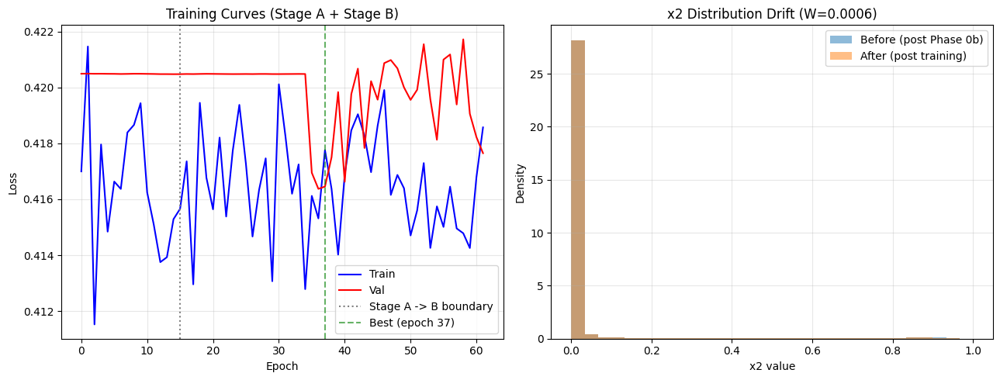

In [18]:
# [DRIFT-ANCHOR] Anchor targets for L_drift. REVIEW FIX: they come from TRAINING crops only (x2_dist_before_train);
# the previous version took them from validation images, so validation features leaked into the optimisation
# objective. The validation-derived x2_dist_before is kept solely for the before/after drift REPORT further down.
@torch.no_grad()
def _train_x2_reference(n_batches=None):
    model.eval(); out = []
    for i, (imgs, _, _) in enumerate(loader_train):
        if i >= (n_batches or FEATURE_DRIFT_N_BATCHES): break
        _, _, x2_map, _, _, _ = model(imgs.to(DEVICE))
        out.append(x2_map.flatten().cpu())
    return torch.cat(out).numpy()

if globals().get('x2_dist_before_train') is None:
    # resumed from an older checkpoint: the model is still in its Phase-0b state here, so recomputing is valid
    x2_dist_before_train = _train_x2_reference()
    print('[drift-anchor] training-derived reference recomputed from the training loader')
X2_MEAN_ANCHOR = float(x2_dist_before_train.mean())
X2_STD_ANCHOR  = float(x2_dist_before_train.std())
print(f'[drift-anchor] targets captured (TRAINING data): x2 mean={X2_MEAN_ANCHOR:.4f} std={X2_STD_ANCHOR:.4f}')


def set_trainable(params, trainable: bool):
    for p in params:
        p.requires_grad = trainable

def set_bn_eval(module):
    for m in module.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()

def set_bn_train(module):
    for m in module.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.train()

encoder_modules = [model.enc1, model.enc2, model.enc3, model.enc4, model.bot]
decoder_modules = [model.smoe2, model.smoe3, model.smoe4,
                   model.up4, model.dec4, model.up3, model.dec3,
                   model.up2, model.dec2, model.up1, model.dec1, model.unet_head]


def _frozen_state_checksum():
    """md5 over the FULL state (parameters AND BatchNorm running statistics) of every module that Stage A must not
    touch: encoder, bottleneck, sMoE blocks, decoder and the x2 head (unet_head). Used to PROVE the freeze."""
    h = hashlib.md5()
    for m in encoder_modules + decoder_modules:
        for k, v in m.state_dict().items():
            h.update(k.encode()); h.update(v.detach().cpu().numpy().tobytes())
    return h.hexdigest()[:12]


def train_one_epoch_stageA(model, loader, optimizer, criterion, device):
    model.train()
    for m in encoder_modules + decoder_modules:
        set_bn_eval(m)
    running = 0.0
    for imgs, masks, _ in tqdm(loader, desc='  StageA train', leave=False):
        imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        optimizer.zero_grad()
        prob, rule_maps, _, _, _, _ = model(imgs)
        if prob.dim() == 3: prob = prob.unsqueeze(1)
        # [ADDED] rule-utilization regularizer -- ANFIS/MF params are already
        # trainable in Stage A, so rule collapse can begin forming here too.
        l_util = rule_utilization_loss(rule_maps)
        loss = criterion(prob, masks) + LAMBDA_RULE_UTIL * l_util
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        optimizer.step()
        running += loss.item()
    return running / len(loader)


def train_one_epoch_stageB(model, loader, optimizer, criterion, device, alpha, encoder_frozen, drift_active):
    model.train()
    if encoder_frozen:
        for m in encoder_modules:
            set_bn_eval(m)
    else:
        for m in encoder_modules:
            set_bn_train(m)
    # [FIXED v5] decoder BN used to be train-mode even while the decoder was
    # frozen (epochs 1..DECODER_UNFREEZE_EPOCH), so running stats kept moving and
    # x2 drifted away from the FCM-fitted geometry despite requires_grad=False.
    # `drift_active` == "decoder/x2_head unfrozen".
    for m in decoder_modules:
        if drift_active: set_bn_train(m)
        else:            set_bn_eval(m)

    running, running_drift, running_util = 0.0, 0.0, 0.0
    for imgs, masks, _ in tqdm(loader, desc='  StageB train', leave=False):
        imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        optimizer.zero_grad()
        prob, rule_maps, x2, _, unet_logits, _ = model(imgs)
        if prob.dim() == 3: prob = prob.unsqueeze(1)
        l_backbone = criterion(torch.sigmoid(unet_logits), masks)
        l_anfis    = criterion(prob, masks)

        # [DRIFT-ANCHOR, added] Only meaningful once x2_head is actually
        # trainable -- while frozen, x2 physically cannot move, so this would
        # just be near-constant noise in the loss. Anchors x2's batch mean/std
        # back toward the Phase-0b snapshot instead of letting it drift freely
        # once unfrozen (this is what turns "delayed unfreeze" into "delayed
        # AND then gently held in place", the missing half of the fix).
        if drift_active:
            l_drift = (x2.mean() - X2_MEAN_ANCHOR).abs() + (x2.std() - X2_STD_ANCHOR).abs()
        else:
            l_drift = torch.zeros((), device=device)

        # [ADDED] rule-utilization regularizer -- see rule_utilization_loss()
        # docstring. Applied every Stage-B epoch (ANFIS params are trainable
        # throughout Stage B, MF params from MF_FREEZE_EPOCHS onward).
        l_util = rule_utilization_loss(rule_maps)

        loss = alpha * l_backbone + (1 - alpha) * l_anfis + LAMBDA_DRIFT * l_drift + LAMBDA_RULE_UTIL * l_util
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        optimizer.step()
        running += loss.item()
        running_drift += l_drift.item()
        running_util += l_util.item()
    return running / len(loader), running_drift / len(loader), running_util / len(loader)


def validate_epoch(model, loader, criterion, device):
    model.eval()
    running = 0.0
    with torch.no_grad():
        for imgs, masks, _ in tqdm(loader, desc='  val', leave=False):
            masks = masks.to(device, non_blocking=True)
            pred  = predict_native(model, imgs, device, which='anfis')
            running += criterion(pred, masks).item()
    return running / len(loader)


@torch.no_grad()
def print_rule_diagnostics(model, loader, device, n_batches=15, tag=''):
    wbars = []
    model.eval()
    for i, (imgs, _, _) in enumerate(loader):
        if i >= n_batches: break
        imgs_pad, H, W = pad_to_multiple(imgs.to(device), multiple=PAD_MULTIPLE)
        _, wbar, _, _, _, _ = model(imgs_pad)
        wbars.append(wbar[..., :H, :W].cpu())
    mean_w, max_w, dom_pct = rule_activation_diagnostics(wbars)
    print(f'  [rule diagnostics{tag}] ' +
          '  '.join(f'R{k+1}: fire={mean_w[k]:.2f} dom={dom_pct[k]:.0f}%' for k in range(len(mean_w))))
    if dom_pct.max() > 95:
        print('    WARNING: possible rule collapse (one rule >95% dominant).')


# [ADDED] Resume support: restore model/optimizer/scheduler state, loss
# history, best-weight tracking, and which stage/epoch to resume at, from
# a checkpoint if one exists. The existing in-memory best_state_dict
# tracking below is unchanged -- this only adds where it can be restored
# FROM after a session restart.
if 'CKPT_TRAIN' not in globals(): CKPT_TRAIN = 'training_state_v10.pt'
_train_ckpt = load_checkpoint(CKPT_TRAIN)
if _train_ckpt is not None:
    model.load_state_dict(_train_ckpt['model_state'])
    apply_model_behaviour(model, _train_ckpt)
    optimizer.load_state_dict(_train_ckpt['optimizer_state'])
    scheduler.load_state_dict(_train_ckpt['scheduler_state'])
    train_losses = _train_ckpt['train_losses']
    val_losses = _train_ckpt['val_losses']
    best_val_loss = _train_ckpt['best_val_loss']
    best_epoch = _train_ckpt['best_epoch']
    best_state_dict = _train_ckpt['best_state_dict']
    _patience_ctr_resume = _train_ckpt['patience_ctr']
    if _train_ckpt['stage'] == 'A':
        _stageA_start_epoch = _train_ckpt['epoch'] + 1
        _stageB_start_epoch = 1
    else:
        _stageA_start_epoch = FROZEN_BASELINE_EPOCHS + 1
        _stageB_start_epoch = _train_ckpt['epoch'] + 1
    print(f"[resume] Training restored from checkpoint -- stage={_train_ckpt['stage']} "
          f"epoch={_train_ckpt['epoch']} best_val_loss={best_val_loss:.4f}")
    if RESTORE_RNG_ON_RESUME and '_rng' in _train_ckpt:
        restore_rng_state(_train_ckpt['_rng'])
else:
    train_losses, val_losses = [], []
    best_val_loss, best_epoch = float('inf'), 0
    best_state_dict = None   # kept IN MEMORY, same as before [UNCHANGED]
    _patience_ctr_resume = 0
    _stageA_start_epoch = 1
    _stageB_start_epoch = 1

# ---------------------------------------------------------------------------
# STAGE A -- frozen baseline
# ---------------------------------------------------------------------------
print('='*72)
print(f'STAGE A -- frozen-backbone baseline ({FROZEN_BASELINE_EPOCHS} epochs): encoder, decoder AND x2 head (unet_head)')
print('           have requires_grad=False and BatchNorm in eval mode; verified below by a state checksum')
print('='*72)
set_trainable(encoder_params, False)
set_trainable(decoder_params, False)
set_trainable(x2_head_params, False)   # [review fix] unet_head is NOT in decoder_params -- it was never frozen in Stage A
set_trainable(anfis_params,   True)
set_trainable(mf_params,      True)
_stageA_will_run = _stageA_start_epoch <= FROZEN_BASELINE_EPOCHS
if _stageA_will_run:
    _frozen_before = _frozen_state_checksum()

for epoch in range(_stageA_start_epoch, FROZEN_BASELINE_EPOCHS + 1):
    model.anfis_head.update_sigma_ceiling()   # sigma ceiling: refresh from current centers
    tl = train_one_epoch_stageA(model, loader_train, optimizer, criterion, DEVICE)
    vl = validate_epoch(model, loader_val, criterion, DEVICE)
    train_losses.append(tl); val_losses.append(vl)
    print(f'  [StageA] epoch {epoch:3d}/{FROZEN_BASELINE_EPOCHS}  train={tl:.4f}  val={vl:.4f}')
    if _stageA_will_run and epoch == _stageA_start_epoch:   # fail fast: do not wait 15 epochs to learn the freeze is broken
        assert _frozen_state_checksum() == _frozen_before, 'Stage A changed frozen modules during its first epoch'
    if vl < best_val_loss:
        best_val_loss, best_epoch = vl, epoch
        best_state_dict = copy.deepcopy(model.state_dict())   # in-memory only [UNCHANGED]

    # [ADDED] per-epoch checkpoint save point (Stage A)
    save_checkpoint({
        'stage': 'A', 'epoch': epoch,
        'model_state': model.state_dict(),
        'optimizer_state': optimizer.state_dict(),
        'scheduler_state': scheduler.state_dict(),
        'train_losses': train_losses, 'val_losses': val_losses,
        'best_val_loss': best_val_loss, 'best_epoch': best_epoch,
        'patience_ctr': 0, 'best_state_dict': best_state_dict,
    }, CKPT_TRAIN)

print(f'\nStage A complete. Best val loss so far: {best_val_loss:.4f}')
if _stageA_will_run:
    _frozen_after = _frozen_state_checksum()
    assert _frozen_before == _frozen_after, (
        f'Stage A modified frozen modules (checksum {_frozen_before} -> {_frozen_after}): the freeze is broken')
    print(f'[Stage A check] encoder + decoder + x2 head state (weights AND BN statistics) unchanged: checksum {_frozen_after}  PASS')

# ---------------------------------------------------------------------------
# STAGE B -- joint fine-tuning, gradual unfreeze
# ---------------------------------------------------------------------------
print('\n' + '='*72)
print(f'STAGE B -- joint fine-tuning, up to {MAX_EPOCHS} epochs, gradual unfreeze')
print('='*72)
set_trainable(decoder_params, False)   # FIX: was unconditionally True from epoch 1
set_trainable(x2_head_params, False)   # [DRIFT-ANCHOR, added] same protection as decoder_params
set_trainable(anfis_params,   True)
patience_ctr = _patience_ctr_resume   # [CHANGED] resume the counter instead of always 0

for epoch in range(_stageB_start_epoch, MAX_EPOCHS + 1):
    mf_frozen = epoch <= MF_FREEZE_EPOCHS
    set_trainable(mf_params, not mf_frozen)

    encoder_frozen = epoch <= ENCODER_UNFREEZE_EPOCH
    set_trainable(encoder_params, not encoder_frozen)

    # FIX: decoder (unet_head -> x2) now protected on its own schedule instead
    # of being trainable from Stage-B epoch 1 -- this was the earliest, most
    # direct source of x2 drift relative to the FCM-fitted geometry.
    decoder_frozen = epoch <= DECODER_UNFREEZE_EPOCH
    set_trainable(decoder_params, not decoder_frozen)
    set_trainable(x2_head_params, not decoder_frozen)   # [DRIFT-ANCHOR, added]

    model.anfis_head.update_sigma_ceiling()   # sigma ceiling: refresh from current centers

    if epoch == 1:
        print(f'  MF params frozen for Stage-B epochs 1-{MF_FREEZE_EPOCHS}')
        print(f'  Encoder frozen (weights+BN) for Stage-B epochs 1-{ENCODER_UNFREEZE_EPOCH}, '
              f'then unfreezes at lr={LR_ENCODER}')
        print(f'  Decoder (smoe/up/dec) frozen for Stage-B epochs 1-{DECODER_UNFREEZE_EPOCH}, '
              f'then unfreezes at lr={LR_DECODER}')
        print(f'  [DRIFT-ANCHOR] x2_head (unet_head) frozen for Stage-B epochs 1-{DECODER_UNFREEZE_EPOCH}, '
              f'then unfreezes at lr={LR_X2_HEAD} (10x smaller than decoder) with L_drift active '
              f'(lambda={LAMBDA_DRIFT}, anchored to x2 mean={X2_MEAN_ANCHOR:.4f} std={X2_STD_ANCHOR:.4f})')
    if epoch == ENCODER_UNFREEZE_EPOCH + 1:
        print(f'  >>> Encoder unfrozen at Stage-B epoch {epoch} (lr={LR_ENCODER})')
    if epoch == DECODER_UNFREEZE_EPOCH + 1:
        print(f'  >>> Decoder unfrozen at Stage-B epoch {epoch} (lr={LR_DECODER})')
        print(f'  >>> [DRIFT-ANCHOR] x2_head unfrozen at Stage-B epoch {epoch} '
              f'(lr={LR_X2_HEAD}, L_drift now active)')

    tl, drift_avg, util_avg = train_one_epoch_stageB(model, loader_train, optimizer, criterion, DEVICE,
                                ALPHA_BACKBONE, encoder_frozen, drift_active=not decoder_frozen)
    vl = validate_epoch(model, loader_val, criterion, DEVICE)
    train_losses.append(tl); val_losses.append(vl)
    scheduler.step(vl)

    if vl < best_val_loss:
        best_val_loss, best_epoch, patience_ctr = vl, len(train_losses), 0
        best_state_dict = copy.deepcopy(model.state_dict())   # in-memory only [UNCHANGED]
        status = 'BEST'
    else:
        patience_ctr += 1
        status = f'pat {patience_ctr}/{PATIENCE}'

    # [ADDED] per-epoch checkpoint save point (Stage B)
    save_checkpoint({
        'stage': 'B', 'epoch': epoch,
        'model_state': model.state_dict(),
        'optimizer_state': optimizer.state_dict(),
        'scheduler_state': scheduler.state_dict(),
        'train_losses': train_losses, 'val_losses': val_losses,
        'best_val_loss': best_val_loss, 'best_epoch': best_epoch,
        'patience_ctr': patience_ctr, 'best_state_dict': best_state_dict,
    }, CKPT_TRAIN)

    if epoch % 10 == 0 or epoch == 1:
        lrs = [f'{g["name"]}={g["lr"]:.1e}' for g in optimizer.param_groups]
        print(f'  [StageB] epoch {epoch:4d} train={tl:.4f} val={vl:.4f} {" ".join(lrs)}  {status}')

    # [DRIFT-ANCHOR, added] Live drift-loss trend, separate from the final
    # before/after Wasserstein report -- lets you see whether L_drift is
    # actually shrinking (x2 settling near its anchor) or growing (anchor
    # too weak / LR_X2_HEAD still too high) well before training finishes.
    if not decoder_frozen and epoch % DRIFT_REPORT_EVERY_N_EPOCHS == 0:
        print(f'  [drift-anchor] epoch {epoch:4d}  L_drift={drift_avg:.5f}  '
              f'(target x2 mean={X2_MEAN_ANCHOR:.4f} std={X2_STD_ANCHOR:.4f})')

    if epoch % RULE_DIAG_EVERY_N_EPOCHS == 0:
        print_rule_diagnostics(model, loader_val, DEVICE, tag=f' @ StageB epoch {epoch}')
        log_rule_geometry(model.anfis_head, tag=f' @ StageB epoch {epoch}')
        # [ADDED] observability for the new regularizer: 0=balanced usage, 1=collapse
        print(f'  [rule-util loss] epoch {epoch:4d}  L_util={util_avg:.4f}  (0=balanced, 1=full collapse)')

    if patience_ctr >= PATIENCE:
        print(f'\nEarly stopping at Stage-B epoch {epoch}')
        break

# Restore best weights (in-memory swap, nothing written to disk)
if best_state_dict is not None:
    model.load_state_dict(best_state_dict)
print(f'\nBest val loss: {best_val_loss:.4f} at global epoch {best_epoch} (best weights restored from memory)')

# Step 1: verify the restored weights genuinely belong to THIS run, not a
# stale reference -- prints a checksum of the loaded state_dict plus the
# actual consequent/sigma-ceiling values, so results can be compared across
# runs to confirm they differ when training genuinely differs. Read-only.
_state_bytes = b''.join(p.detach().cpu().numpy().tobytes() for p in model.parameters())
_state_checksum = hashlib.md5(_state_bytes).hexdigest()[:12]
print(f'Loaded-weights checksum: {_state_checksum}  (best_epoch={best_epoch})')
log_rule_geometry(model.anfis_head, tag=' (post-training, restored best weights)')
print(f'ANFIS consequents (restored):\n{model.anfis_head.consequents.detach().cpu().numpy()}')

# Feature-drift snapshot AFTER training (compare against the Phase-0b baseline)
with torch.no_grad():
    x2_after_list = []
    for i, (imgs, _, _) in enumerate(loader_val):
        if i >= FEATURE_DRIFT_N_BATCHES: break
        imgs_pad, H, W = pad_to_multiple(imgs.to(DEVICE), multiple=PAD_MULTIPLE)
        _, _, x2_map, _, _, _ = model(imgs_pad)
        x2_after_list.append(x2_map[..., :H, :W].cpu().flatten())
x2_dist_after = torch.cat(x2_after_list).numpy()

w_dist = wasserstein_distance(x2_dist_before, x2_dist_after)
hist_before, edges = np.histogram(x2_dist_before, bins=30, range=(0,1), density=True)
hist_after, _      = np.histogram(x2_dist_after,  bins=edges, density=True)
kl = float(np.sum(np.where(hist_before > 0,
                           hist_before * np.log((hist_before + 1e-8) / (hist_after + 1e-8)), 0)) * (edges[1]-edges[0]))

print('\n' + '='*72)
print('FEATURE-DRIFT REPORT -- x2 = sigmoid(unet_logits), before vs after backbone fine-tuning')
print('='*72)
print(f'  Before (post Phase-0b) : mean={x2_dist_before.mean():.4f}  std={x2_dist_before.std():.4f}')
print(f'  After  (post training) : mean={x2_dist_after.mean():.4f}  std={x2_dist_after.std():.4f}')
print(f'  Wasserstein distance   : {w_dist:.4f}')
print(f'  Approx. KL(before||after): {kl:.4f}')
if w_dist > 0.05:
    print('  NOTE: noticeable drift -- the FCM rule geometry was fit on a feature')
    print('  space that has since moved; consider a smaller LR_ENCODER or an')
    print('  earlier ENCODER_UNFREEZE_EPOCH if downstream metrics look off.')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(train_losses, 'b-', lw=1.5, label='Train')
axes[0].plot(val_losses,   'r-', lw=1.5, label='Val')
axes[0].axvline(FROZEN_BASELINE_EPOCHS, color='gray', ls=':', label='Stage A -> B boundary')
axes[0].axvline(best_epoch, color='g', ls='--', alpha=0.6, label=f'Best (epoch {best_epoch})')
axes[0].set(xlabel='Epoch', ylabel='Loss', title='Training Curves (Stage A + Stage B)')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].hist(x2_dist_before, bins=30, range=(0,1), alpha=0.5, label='Before (post Phase 0b)', density=True)
axes[1].hist(x2_dist_after,  bins=30, range=(0,1), alpha=0.5, label='After (post training)', density=True)
axes[1].set(xlabel='x2 value', ylabel='Density', title=f'x2 Distribution Drift (W={w_dist:.4f})')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/training_curves_and_drift.png', dpi=150)
plt.show()


## Cell — Evaluation: ODS / OIS / AP
### v6: `standard` protocol (NMS thinning + per-annotator matching) reported alongside the v4/v5 `legacy` protocol; optional flip-TTA rows; Sobel calibration check.


[self-check] matching: components == sparse min-cost == dense reference on 40/40 random instances  PASS
EVALUATION on the TEST split with the custom BSDS-style evaluator (not the official toolbox; not validated against it)
  Test results: settings must already be frozen. The evaluator/TTA history is NOT test-independent (see the header of this cell); make further choices on EVAL_SPLIT="val".

Computing metrics...


Matching [standard]: 100%|██████████| 200/200 [1:34:37<00:00, 28.39s/it]


anfis   [standard]             ODS=0.7491  OIS=0.7658 (mean-of-image-F 0.7618)  AP=0.7914 (reached 0.8035)  best_t=0.01  max_recall=0.980
                               95% CI over test images: ODS [0.7353, 0.7628]  OIS [0.7542, 0.7781]  AP [0.7756, 0.8051]
                               classic grid 0.01-0.99 only: ODS=0.7491  OIS=0.7621  AP=0.6662


Matching [standard]: 100%|██████████| 200/200 [1:20:11<00:00, 24.06s/it]


anfis   [standard+MS-TTA]      ODS=0.7590  OIS=0.7775 (mean-of-image-F 0.7728)  AP=0.8022 (reached 0.8148)  best_t=0.01  max_recall=0.964
                               95% CI over test images: ODS [0.7456, 0.7727]  OIS [0.7655, 0.7893]  AP [0.7877, 0.8155]
                               classic grid 0.01-0.99 only: ODS=0.7590  OIS=0.7743  AP=0.7012
  [saved probability maps] /kaggle/working/smoe_results_v4/preds/anfis_ms_test.npz


Matching [standard]: 100%|██████████| 200/200 [1:24:30<00:00, 25.35s/it]


backbone[standard]             ODS=0.7489  OIS=0.7656 (mean-of-image-F 0.7622)  AP=0.7859 (reached 0.7989)  best_t=0.01  max_recall=0.966
                               95% CI over test images: ODS [0.7347, 0.7625]  OIS [0.7537, 0.7779]  AP [0.7707, 0.8000]
                               classic grid 0.01-0.99 only: ODS=0.7489  OIS=0.7640  AP=0.6751


Matching [standard]: 100%|██████████| 200/200 [1:11:44<00:00, 21.52s/it]


backbone[standard+MS-TTA]      ODS=0.7583  OIS=0.7771 (mean-of-image-F 0.7727)  AP=0.7951 (reached 0.8088)  best_t=0.01  max_recall=0.949
                               95% CI over test images: ODS [0.7449, 0.7721]  OIS [0.7652, 0.7888]  AP [0.7806, 0.8095]
                               classic grid 0.01-0.99 only: ODS=0.7583  OIS=0.7754  AP=0.7017
  [saved probability maps] /kaggle/working/smoe_results_v4/preds/backbone_ms_test.npz

ANFIS - Backbone [single-scale] (paired image bootstrap): ODS +0.0001 [-0.0006, 0.0009]  OIS +0.0002 [-0.0008, 0.0012]  AP +0.0049 [0.0034, 0.0059]

ANFIS - Backbone [multi-scale] (paired image bootstrap): ODS +0.0006 [-0.0007, 0.0012]  OIS +0.0004 [-0.0008, 0.0013]  AP +0.0065 [0.0047, 0.0077]


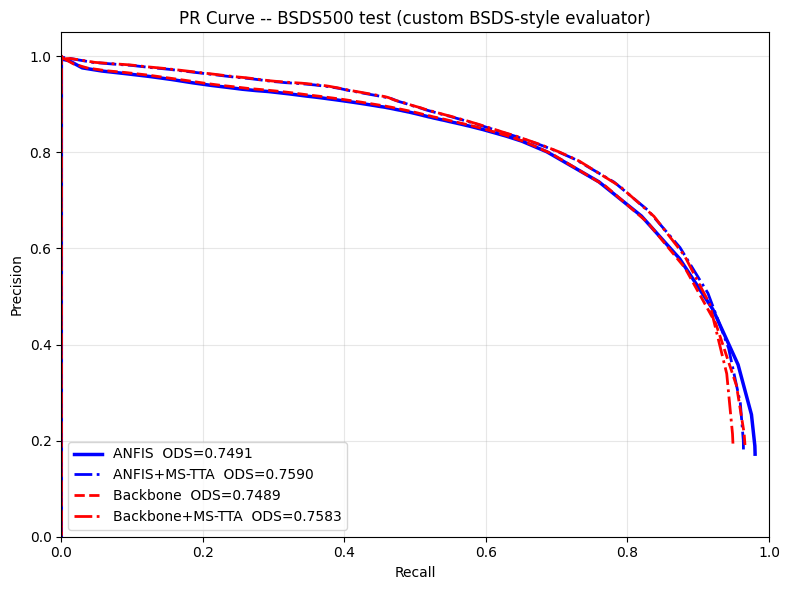

In [19]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial  import cKDTree
from scipy.sparse   import coo_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components, min_weight_full_bipartite_matching
from scipy.ndimage  import gaussian_filter, map_coordinates
import glob, concurrent.futures, multiprocessing as mp

# ============================================================================================================
# CUSTOM BSDS-STYLE EVALUATOR -- read this before quoting any number from it.
#  * It is NOT the official Berkeley/MATLAB toolbox and has NOT been validated against it (per-threshold count
#    agreement on identical saved maps is still to be done: see export_for_external_benchmark /
#    compare_with_reference_counts below). Label results "custom evaluator" until that comparison exists.
#  * Its design was revised AFTER inspecting test-set logs: the log-spaced low-threshold segment of the grid (v8:
#    best_t sat at the lowest grid point), the prediction cap, and the TTA scales were all chosen/changed while
#    looking at test results. Correcting an evaluator is legitimate, but the development history is NOT
#    independent of test feedback -- do not describe it as "no test-set tuning". From this version the evaluator is
#    FROZEN (EVALUATOR_CONFIG below is stored in every checkpoint manifest); any further inference/evaluator choice
#    must be made with EVAL_SPLIT='val', and 'test' used once for the final run.
# ============================================================================================================
N_WORKERS = min(os.cpu_count() or 4, 4)
MAX_PRED  = 15000          # legacy protocol cap (legacy is kept only for comparison with old logs)

def make_thresholds(n_lin=99, extend=True):
    """Linear 0.01..0.99 grid (the classic grid) plus, for the standard protocol, EVAL_N_LOW log-spaced points in
    [EVAL_T_LOW, 0.01): ODS/AP depend only on ranking, and these detectors are under-confident, so the useful
    operating range reaches below 0.01. A boundary check in score_predictions warns if the optimum still sits at
    a grid edge."""
    lin = np.linspace(0.01, 0.99, n_lin)
    if not extend:
        return lin
    n_low = int(globals().get('EVAL_N_LOW', 8)); t_low = float(globals().get('EVAL_T_LOW', 1e-4))
    low = np.geomspace(t_low, 0.01, n_low, endpoint=False)
    return np.concatenate([low, lin])

# ---------------------------------------------------------------------------
# Ground truth loading (unchanged from v4/v5)
# ---------------------------------------------------------------------------
def load_gt_boundaries(mat_path):
    boundaries = []
    try:
        mat = scipy.io.loadmat(mat_path, squeeze_me=True)
        gt_cell = mat['groundTruth']
        if gt_cell.ndim == 0:
            gt_cell = gt_cell.reshape(1)
        for ann in gt_cell.flat:
            try:
                b = ann['Boundaries'] if isinstance(ann, np.void) else ann[()]['Boundaries']
            except (KeyError, TypeError, IndexError):
                b = ann[0, 0][1] if hasattr(ann, '__getitem__') else ann.Boundaries
            if hasattr(b, 'toarray'):
                b = b.toarray()
            boundaries.append(b.astype(np.float32))
        return boundaries
    except Exception:
        return []


# ---------------------------------------------------------------------------
# [ADDED v6] Ridge-based non-maximum suppression (thinning).
# Simplified re-implementation of the idea behind Dollar's edgesNms: estimate the
# across-edge direction from the Hessian of the smoothed map, keep a pixel only if
# it is a local maximum along that direction. Differences from the MATLAB toolbox:
# Gaussian (not triangle) smoothing, no image-border suppression term.
# Computed ONCE per image; thresholds then just select pixels of the thinned map.
# ---------------------------------------------------------------------------
def edge_nms(prob, sigma=2.0, radius=1, mult=1.01):
    E = prob.astype(np.float32)
    a = gaussian_filter(E, sigma, order=(0, 2))    # d2/dx2   (axis0=y, axis1=x)
    c = gaussian_filter(E, sigma, order=(2, 0))    # d2/dy2
    b = gaussian_filter(E, sigma, order=(1, 1))    # d2/dxdy
    half = 0.5 * (a + c)
    rad  = np.sqrt((0.5 * (a - c)) ** 2 + b ** 2)
    lam1, lam2 = half + rad, half - rad
    th1   = 0.5 * np.arctan2(2.0 * b, a - c)       # (x,y) direction of eigvec for lam1
    theta = np.where(np.abs(lam1) >= np.abs(lam2), th1, th1 + np.pi / 2)   # across-ridge
    dx, dy = np.cos(theta), np.sin(theta)
    H, W = E.shape
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    keep = np.ones((H, W), dtype=bool)
    e = E * mult
    for d in range(1, radius + 1):
        for sgn in (-1.0, 1.0):
            nb = map_coordinates(E, [yy + sgn * d * dy, xx + sgn * d * dx],
                                 order=1, mode='nearest')
            keep &= (e >= nb)
    return np.where(keep, E, 0.0).astype(np.float32)


# ---------------------------------------------------------------------------
# Bipartite matching. Both matchers return (n_matched, indices of matched PREDICTED pixels) and give the same
# match count (maximum-cardinality, then minimum total distance) -- checked by selftest_matching() below.
#   _match_components    : connected components + dense Hungarian per component (fast for moderate sets)
#   _match_sparse_mincost: ONE sparse min-cost assignment over the whole candidate graph, with a dummy
#                          "unmatched" column per prediction (cost > any possible saving), so it scales to the
#                          dense prediction sets that appear once the prediction cap is removed.
# ---------------------------------------------------------------------------
def _match_sparse_mincost(pred_yx, gt_yx, gt_tree, maxDist):
    n_p, n_g = len(pred_yx), len(gt_yx)
    empty = np.zeros(0, dtype=np.int64)
    if n_p == 0 or n_g == 0:
        return 0.0, empty
    pairs = cKDTree(pred_yx).sparse_distance_matrix(gt_tree, maxDist, output_type='ndarray')
    i, j, v = pairs['i'], pairs['j'], pairs['v']
    keep = v < maxDist
    i, j, v = i[keep], j[keep], v[keep]
    if len(i) == 0:
        return 0.0, empty
    C = (n_p + 1.0) * maxDist                        # unmatched cost: cardinality is maximised first
    rows = np.concatenate([i, np.arange(n_p)])
    cols = np.concatenate([j, n_g + np.arange(n_p)])
    w = np.concatenate([v + 1e-6, np.full(n_p, C)])  # +1e-6: explicit non-zero weights
    r, c = min_weight_full_bipartite_matching(csr_matrix((w, (rows, cols)), shape=(n_p, n_g + n_p)))
    real = c < n_g
    return float(real.sum()), r[real]


def _match_components(pred_yx, gt_yx, gt_tree, maxDist):
    n_pred = len(pred_yx); n_gt = len(gt_yx)
    empty = np.zeros(0, dtype=np.int64)
    if n_pred == 0 or n_gt == 0:
        return 0.0, empty
    neighbors = gt_tree.query_ball_point(pred_yx, r=maxDist)
    pred_idx_list, gt_idx_list, dist_list = [], [], []
    for pi, gts in enumerate(neighbors):
        if not gts: continue
        gy = gt_yx[gts]
        d  = np.sqrt(((gy - pred_yx[pi]) ** 2).sum(-1))
        for gj, dd in zip(gts, d):
            pred_idx_list.append(pi); gt_idx_list.append(gj); dist_list.append(dd)
    if not pred_idx_list:
        return 0.0, empty
    pred_idx_arr = np.array(pred_idx_list); gt_idx_arr = np.array(gt_idx_list)
    dist_arr = np.array(dist_list)
    n_total = n_pred + n_gt
    rows = np.concatenate([pred_idx_arr, gt_idx_arr + n_pred])
    cols = np.concatenate([gt_idx_arr + n_pred, pred_idx_arr])
    data = np.ones(len(rows))
    graph = coo_matrix((data, (rows, cols)), shape=(n_total, n_total))
    _, labels = connected_components(graph, directed=False)
    pred_labels = labels[:n_pred]
    edge_comp = pred_labels[pred_idx_arr]
    tp = 0.0
    matched = []
    for comp_id in np.unique(edge_comp):
        mask = edge_comp == comp_id
        p_local_ids = np.unique(pred_idx_arr[mask]); g_local_ids = np.unique(gt_idx_arr[mask])
        r, c = len(p_local_ids), len(g_local_ids)
        if r * c > 25_000_000:                      # one giant component: dense cost matrix would not fit
            return _match_sparse_mincost(pred_yx, gt_yx, gt_tree, maxDist)
        p_map = {p: k for k, p in enumerate(p_local_ids)}
        g_map = {g: k for k, g in enumerate(g_local_ids)}
        cost = np.full((r, c), 1e9)
        for p, g, d in zip(pred_idx_arr[mask], gt_idx_arr[mask], dist_arr[mask]):
            cost[p_map[p], g_map[g]] = d
        row_ind, col_ind = linear_sum_assignment(cost)
        valid = cost[row_ind, col_ind] < maxDist
        tp += float(valid.sum())
        matched.append(p_local_ids[row_ind[valid]])
    matched = np.concatenate(matched) if matched else empty
    return tp, matched


def _match_dispatch(pred_yx, gt_yx, gt_tree, maxDist):
    if len(pred_yx) <= int(globals().get('EVAL_COMPONENT_MATCH_MAX', 10000)):
        return _match_components(pred_yx, gt_yx, gt_tree, maxDist)
    return _match_sparse_mincost(pred_yx, gt_yx, gt_tree, maxDist)

_sparse_bipartite_tp = _match_dispatch      # old name kept for backward compatibility


def selftest_matching(n_trials=40, seed=0, maxDist=4.3):
    """Both matchers must return the same match count as an independent dense reference on random instances."""
    rng = np.random.RandomState(seed); bad = 0
    for _ in range(n_trials):
        npred, ngt = rng.randint(5, 300), rng.randint(5, 200)
        P = np.unique(np.column_stack([rng.randint(0, 60, npred), rng.randint(0, 60, npred)]).astype(np.float32), axis=0)
        G = np.unique(np.column_stack([rng.randint(0, 60, ngt),  rng.randint(0, 60, ngt)]).astype(np.float32), axis=0)
        tree = cKDTree(G)
        a, _ = _match_components(P, G, tree, maxDist); b, _ = _match_sparse_mincost(P, G, tree, maxDist)
        d = np.sqrt(((P[:, None, :] - G[None, :, :]) ** 2).sum(-1))
        cost = np.full(d.shape, 1e9); cost[d < maxDist] = d[d < maxDist]
        ri, ci = linear_sum_assignment(cost); ref = float((cost[ri, ci] < maxDist).sum())
        bad += int(not (a == b == ref))
    print(f'[self-check] matching: components == sparse min-cost == dense reference on {n_trials - bad}/{n_trials} '
          f'random instances' + ('  PASS' if bad == 0 else '   <-- WARNING'))
    return bad == 0

selftest_matching()


# ---------------------------------------------------------------------------
# Counts at every threshold for ONE image.
#   protocol='legacy'   : v4/v5 behaviour -- raw (unthinned) map, GT = union of annotators, single 1:1 match,
#                         maxDist = .0075*max(H,W), cap MAX_PRED. Kept only to compare with old logs.
#   protocol='standard' : thinned map (edge_nms); every annotator matched separately; recall = sum matched GT px /
#                         sum GT px over annotators; precision = predicted px matched to >=1 annotator / predicted
#                         px; maxDist = .0075*image diagonal; prediction cap = MAX_PRED_STANDARD (None = no cap).
# Returns (cntP, sumP, cntR, sumR, capped[T]).
# Exact shortcuts (no approximation): thresholds are ascending, so predicted sets are NESTED -- equal size means an
# identical set (counts copied); thresholds that all hit the cap select the identical top-`cap` set (matched once).
# ---------------------------------------------------------------------------
def counts_at_thresholds(prob, gt_boundaries, thresholds, protocol='standard'):
    H, W = prob.shape
    n_thresh = len(thresholds)
    if protocol == 'standard':
        maxDist = max(0.0075 * float(np.hypot(H, W)), 1.0)
        gts = [(b > 0.5) for b in gt_boundaries]
        prob_eval = edge_nms(prob, sigma=NMS_SIGMA)
        _cap = globals().get('MAX_PRED_STANDARD', None)
        cap = np.inf if _cap is None else int(_cap)
    else:
        maxDist = max(0.0075 * max(H, W), 1.0)
        gts = [(np.stack(gt_boundaries, 0).max(0) > 0.5)]
        prob_eval = prob
        cap = MAX_PRED
    gts = [g for g in gts if g.any()]
    cntP = np.zeros(n_thresh); sumP = np.zeros(n_thresh)
    cntR = np.zeros(n_thresh); sumR = np.zeros(n_thresh)
    capped_arr = np.zeros(n_thresh, dtype=bool)
    if not gts:
        for i, t in enumerate(thresholds):
            sumP[i] = float((prob_eval >= t).sum())
        return cntP, sumP, cntR, sumR, capped_arr
    gt_yx_list = [np.column_stack(np.where(g)).astype(np.float32) for g in gts]
    trees      = [cKDTree(y) for y in gt_yx_list]
    sumR[:] = float(sum(len(y) for y in gt_yx_list))
    prev = None            # (n_pred_before_cap, index) of the last threshold whose counts were actually computed
    capped_ref = None
    for i, t in enumerate(thresholds):
        pred_edge = (prob_eval >= t)
        n_all = int(pred_edge.sum())
        if n_all == 0:
            continue
        is_capped = n_all > cap
        capped_arr[i] = is_capped
        if prev is not None and n_all == prev[0]:
            j = prev[1]; cntP[i], sumP[i], cntR[i] = cntP[j], sumP[j], cntR[j]; continue
        if is_capped and capped_ref is not None:
            j = capped_ref; cntP[i], sumP[i], cntR[i] = cntP[j], sumP[j], cntR[j]; continue
        pred_yx = np.column_stack(np.where(pred_edge)).astype(np.float32)
        if is_capped:      # keep the `cap` most CONFIDENT predictions (no GT information used)
            pred_conf = prob_eval[pred_edge]
            pred_yx = pred_yx[np.argsort(-pred_conf)[:int(cap)]]
        n_pred = len(pred_yx)
        matched_any = np.zeros(n_pred, dtype=bool)
        for gt_yx, tree in zip(gt_yx_list, trees):
            tp_g, m = _match_dispatch(pred_yx, gt_yx, tree, maxDist)
            cntR[i] += tp_g
            if len(m): matched_any[m] = True
        cntP[i] = float(matched_any.sum())
        sumP[i] = float(n_pred)
        prev = (n_all, i)
        if is_capped: capped_ref = i
    return cntP, sumP, cntR, sumR, capped_arr


def _image_counts_worker(args):
    prob, mat_path, gt_fallback, thresholds, protocol = args
    gt_bnd = load_gt_boundaries(mat_path) if (mat_path and os.path.exists(mat_path)) else []
    used_fallback = False
    if not gt_bnd:
        gt_bnd = [gt_fallback]; used_fallback = True      # reported loudly by the caller
    return counts_at_thresholds(prob, gt_bnd, thresholds, protocol), used_fallback


def _prf(cntP, sumP, cntR, sumR):
    P = cntP / (sumP + 1e-8); R = cntR / (sumR + 1e-8)
    return P, R, 2 * P * R / (P + R + 1e-8)


def _ap_bsds_style(precs, recs):
    """AP = mean precision at recall = 0, .01, ..., 1 using UNIQUE recall values and LINEAR interpolation, with 0
    outside the recall range the detector reaches -- the procedure the review describes for Berkeley's
    collect_eval_bdry.m (no precision envelope). UNVERIFIED against the MATLAB source (it could not be fetched);
    tie rule for equal recalls: first occurrence in recall order. Do not call it 'the BSDS AP' until
    compare_with_reference_counts / a reference run confirms it."""
    order = np.argsort(recs, kind='stable'); r, p = recs[order], precs[order]
    ur, idx = np.unique(r, return_index=True); up = p[idx]
    if len(ur) < 2:
        return 0.0
    vals = np.interp(np.linspace(0, 1, 101), ur, up, left=np.nan, right=np.nan)
    return float(np.nan_to_num(vals, nan=0.0).mean())


def _ap_envelope(precs, recs):
    """The pre-review AP: precision ENVELOPE (monotone) at 101 recall points, 0 beyond the reached recall. Kept only
    so older logs remain interpretable; it is not the Berkeley calculation."""
    order = np.argsort(recs)
    r, p = recs[order], precs[order]
    env = np.maximum.accumulate(p[::-1])[::-1]
    grid = np.linspace(0, 1, 101)
    vals = [env[np.searchsorted(r, g, side='left')] if g <= r[-1] else 0.0 for g in grid]
    return float(np.mean(vals))


# ---------------------------------------------------------------------------
# Inference helpers
# ---------------------------------------------------------------------------
@torch.no_grad()
def predict_tta(model, img, device, which='anfis', scales=(1.0,), dihedral=False):
    """Mean over `scales` x 4 flips (x2 transposes when dihedral=True -> 8 views per scale). Every view is mapped
    back to the original orientation and size before averaging. Inference-only; no parameter changes. The 8 dihedral
    views are in-distribution (training used 90-degree rotations and flips). Applied identically to every head."""
    H, W = img.shape[-2:]
    acc, n = None, 0
    for s in scales:
        xs = img if s == 1.0 else F.interpolate(
            img, size=(max(int(round(H * s)), 32), max(int(round(W * s)), 32)),
            mode='bilinear', align_corners=False)
        for tp in ((False, True) if dihedral else (False,)):
            for hf in (False, True):
                for vf in (False, True):
                    x = xs
                    if tp: x = x.transpose(-1, -2).contiguous()
                    if hf: x = torch.flip(x, dims=[-1])
                    if vf: x = torch.flip(x, dims=[-2])
                    p = predict_native(model, x, device, which=which)
                    if vf: p = torch.flip(p, dims=[-2])
                    if hf: p = torch.flip(p, dims=[-1])
                    if tp: p = p.transpose(-1, -2)
                    p = p.reshape(1, 1, p.shape[-2], p.shape[-1]).float()
                    if s != 1.0:
                        p = F.interpolate(p, size=(H, W), mode='bilinear', align_corners=False)
                    acc = p if acc is None else acc + p
                    n += 1
    return acc / n


@torch.no_grad()
def collect_predictions(model, loader, device, which='anfis', tta=False, scales=(1.0,), dihedral=False):
    model.eval()
    preds = []
    _lab = f'{which}' + ('' if not tta else ('+MS-TTA' if tuple(scales) != (1.0,) else '+TTA') + ('8' if dihedral else ''))
    for imgs, masks, stems in tqdm(loader, desc=f'Inference ({_lab})'):
        if tta:
            pred = predict_tta(model, imgs, device, which=which, scales=scales, dihedral=dihedral)
        else:
            pred = predict_native(model, imgs, device, which=which)
        prob = pred.squeeze().cpu().numpy().astype(np.float32)
        gt_b = (masks.squeeze().cpu().numpy() > 0.5).astype(np.float32)
        stem = stems[0] if isinstance(stems, (list, tuple)) else stems
        preds.append((prob, stem, gt_b))
    return preds


def save_preds(preds, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    np.savez_compressed(path, **{stem: prob.astype(np.float32) for prob, stem, _ in preds})
    print(f'  [saved probability maps] {path}')

def load_preds(path):
    d = np.load(path)
    return {k: d[k] for k in d.files}


def score_predictions(preds, protocol='standard', n_thresh=99, split='test'):
    thresholds = make_thresholds(n_thresh, extend=(protocol == 'standard'))
    gt_dir = os.path.join(BSR_ROOT, 'data', 'groundTruth', split)
    jobs = [(prob, os.path.join(gt_dir, f'{stem}.mat'), gt_b, thresholds, protocol)
            for prob, stem, gt_b in preds]
    results = None
    try:   # CPU-bound pure-python matching: processes (fork) beat threads (GIL)
        ctx = mp.get_context('fork')
        with concurrent.futures.ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
            results = list(tqdm(ex.map(_image_counts_worker, jobs, chunksize=2),
                                total=len(jobs), desc=f'Matching [{protocol}]'))
    except Exception as e:
        print(f'  [matching] process pool unavailable ({type(e).__name__}); falling back to threads')
    if results is None:
        with concurrent.futures.ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
            results = list(tqdm(ex.map(_image_counts_worker, jobs), total=len(jobs),
                                desc=f'Matching [{protocol}] (threads)'))
    n_fb = sum(1 for _, fb in results if fb)
    if n_fb:
        print(f'  WARNING: GT .mat could not be parsed for {n_fb}/{len(results)} images -- those used the '
              f'single binary fallback mask, so the protocol is NOT what it claims for them.')
    per_image = [r for r, _ in results]
    N = len(per_image)
    cP_i = np.stack([r[0] for r in per_image]); sP_i = np.stack([r[1] for r in per_image])
    cR_i = np.stack([r[2] for r in per_image]); sR_i = np.stack([r[3] for r in per_image])
    capped = np.stack([r[4] for r in per_image])

    # ODS: counts pooled over images at ONE global threshold.
    precs, recs, fscs = _prf(cP_i.sum(0), sP_i.sum(0), cR_i.sum(0), sR_i.sum(0))
    best_i = int(np.argmax(fscs))
    # OIS (aggregation as described for Berkeley's collect_eval_bdry.m): each image selects ITS OWN best-F operating
    # point; the matching COUNTS at those points are pooled over images and F is computed from the pooled counts.
    # (The pre-review code averaged per-image F instead -- kept as OIS_mean_img for continuity.)
    _, _, F_img = _prf(cP_i, sP_i, cR_i, sR_i)                          # (N, T)
    rows = np.arange(N); best_img = F_img.argmax(axis=1)
    ois_sel = tuple(a[rows, best_img] for a in (cP_i, sP_i, cR_i, sR_i))
    OIS = float(_prf(*(a.sum() for a in ois_sel))[2])
    OIS_mean_img = float(F_img.max(axis=1).mean())

    n_cap_low, n_cap_best = int(capped[:, 0].sum()), int(capped[:, best_i].sum())
    if best_i == 0:
        print(f'  WARNING: best threshold ({thresholds[0]:.2g}) is the LOWEST grid point -- the optimum may lie below '
              f'it; lower EVAL_T_LOW. ODS/AP are still under-estimated.')
    elif best_i == len(thresholds) - 1:
        print('  WARNING: best threshold is the HIGHEST grid point -- extend the grid upward.')
    if n_cap_low or n_cap_best:
        print(f'  NOTE: the prediction cap (MAX_PRED_STANDARD) removed predictions for {n_cap_low}/{N} images at the '
              f'lowest threshold and {n_cap_best}/{N} at the ODS-optimal threshold ({thresholds[best_i]:.2g}); '
              f'capped results are NOT benchmark counts.')
    # classic grid (thresholds >= 0.01 only), computed from the same counts
    m = thresholds >= 0.01 - 1e-12
    Pc, Rc, Fc = _prf(cP_i.sum(0)[m], sP_i.sum(0)[m], cR_i.sum(0)[m], sR_i.sum(0)[m])
    bi_c = F_img[:, m].argmax(axis=1)
    sel_c = tuple(a[:, m][rows, bi_c] for a in (cP_i, sP_i, cR_i, sR_i))
    classic = dict(ODS=float(Fc.max()), OIS=float(_prf(*(a.sum() for a in sel_c))[2]), AP=_ap_bsds_style(Pc, Rc))
    order = np.argsort(recs)
    try:   AP_reached = float(auc(recs[order], precs[order]))
    except ValueError: AP_reached = 0.0
    return dict(ODS=float(fscs[best_i]), OIS=OIS, OIS_mean_img=OIS_mean_img,
                AP=_ap_bsds_style(precs, recs), AP_envelope=_ap_envelope(precs, recs), AP_reached=AP_reached,
                best_t=float(thresholds[best_i]), max_recall=float(recs.max()),
                n_cap_low=n_cap_low, n_cap_best=n_cap_best, classic=classic,
                counts=(cP_i, sP_i, cR_i, sR_i), ois_sel=ois_sel, thresholds=thresholds,
                precs=precs, recs=recs, protocol=protocol, split=split)


# ---------------------------------------------------------------------------
# Uncertainty from the finite test set: bootstrap over IMAGES (pixels within an image are strongly correlated, so
# resampling pixels would be wrong). Per-image operating points for OIS are held fixed. Captures test-sampling
# noise only -- NOT training-seed variance (that needs several independently trained models).
# ---------------------------------------------------------------------------
def _boot_stats(res, idx):
    cP, sP, cR, sR = res['counts']; sc, ss, sr, ssr = res['ois_sel']
    P, R, Fm = _prf(cP[idx].sum(0), sP[idx].sum(0), cR[idx].sum(0), sR[idx].sum(0))
    ois = _prf(sc[idx].sum(), ss[idx].sum(), sr[idx].sum(), ssr[idx].sum())[2]
    return float(Fm.max()), float(ois), _ap_bsds_style(P, R)

def bootstrap_ci(res, n_boot=1000, seed=0, alpha=0.05):
    N = len(res['counts'][0]); rng = np.random.RandomState(seed)
    out = np.array([_boot_stats(res, rng.randint(0, N, N)) for _ in range(n_boot)])
    q = lambda v: (float(np.percentile(v, 100 * alpha / 2)), float(np.percentile(v, 100 * (1 - alpha / 2))))
    return dict(ODS=q(out[:, 0]), OIS=q(out[:, 1]), AP=q(out[:, 2]))

def bootstrap_diff(res_a, res_b, n_boot=1000, seed=0, alpha=0.05):
    """Paired bootstrap (same resampled images for both) of metric(a) - metric(b)."""
    N = len(res_a['counts'][0]); rng = np.random.RandomState(seed); d = []
    for _ in range(n_boot):
        idx = rng.randint(0, N, N)
        d.append(np.array(_boot_stats(res_a, idx)) - np.array(_boot_stats(res_b, idx)))
    d = np.array(d); q = lambda v: (float(np.percentile(v, 100 * alpha / 2)), float(np.percentile(v, 100 * (1 - alpha / 2))))
    return {k: dict(mean=float(d[:, i].mean()), ci=q(d[:, i]), p_pos=float((d[:, i] > 0).mean()))
            for i, k in enumerate(('ODS', 'OIS', 'AP'))}


# ---------------------------------------------------------------------------
# Validation hooks (review item D). To validate this evaluator, score the SAME saved probability maps with an
# established implementation and compare PER-THRESHOLD COUNTS (not just final ODS):
#   1. export_for_external_benchmark(preds, dir)  -> one .mat per image with the raw probability map 'E'
#   2. run the reference pipeline (NMS + matching + collection) on those maps, saving cntP/sumP/cntR/sumR as an
#      .npz with arrays of shape (N images, T thresholds) in the same image order and the same thresholds
#   3. compare_with_reference_counts(result, ref.npz)
# NOT performed in this notebook -- until it is, label all numbers "custom evaluator".
# ---------------------------------------------------------------------------
def export_for_external_benchmark(preds, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    for prob, stem, _ in preds:
        scipy.io.savemat(os.path.join(out_dir, f'{stem}.mat'), {'E': prob.astype(np.float32)})
    print(f'  [export] {len(preds)} probability maps -> {out_dir}')

def export_counts(res, path):
    cP, sP, cR, sR = res['counts']
    np.savez_compressed(path, cntP=cP, sumP=sP, cntR=cR, sumR=sR, thresholds=res['thresholds'])
    print(f'  [export] per-image per-threshold counts -> {path}')

def compare_with_reference_counts(res, ref_npz_path, atol=0.5):
    ref = np.load(ref_npz_path); ok = True
    if 'thresholds' in ref.files and not np.allclose(ref['thresholds'], res['thresholds']):
        print('  WARNING: reference thresholds differ from this evaluator\'s grid'); ok = False
    for k, a in zip(('cntP', 'sumP', 'cntR', 'sumR'), res['counts']):
        b = ref[k]
        if a.shape != b.shape:
            print(f'  {k}: shape mismatch {a.shape} vs {b.shape}'); ok = False; continue
        dlt = np.abs(a - b)
        print(f'  {k}: max|diff|={dlt.max():.1f}  mean|diff|={dlt.mean():.3f}  cells differing by >{atol}: {(dlt > atol).mean()*100:.2f}%')
        ok &= bool(dlt.max() <= atol)
    print('  per-threshold counts agree with the reference' if ok else '  per-threshold counts DIFFER from the reference')
    return ok

EVALUATOR_CONFIG = dict(
    name='custom BSDS-style evaluator (not the official toolbox; not validated against it)',
    nms=f'custom Hessian-ridge NMS (gaussian sigma={NMS_SIGMA}, radius 1, no border suppression)',
    thresholds=f'{int(globals().get("EVAL_N_LOW", 8))} log-spaced in [{float(globals().get("EVAL_T_LOW", 1e-4)):g}, 0.01) + '
               f'{EVAL_N_THRESH} linear in [0.01, 0.99]',
    prediction_cap=globals().get('MAX_PRED_STANDARD', None),
    matcher=f'max-cardinality / min-distance; components <= {int(globals().get("EVAL_COMPONENT_MATCH_MAX", 10000))} px else sparse min-cost',
    tolerance='0.0075 * image diagonal', gt='each annotator matched separately',
    ODS='counts pooled over images at one global threshold',
    OIS="counts pooled at each image's own best-F threshold",
    AP='unique-recall linear interpolation, 101 recall points, 0 outside reached range (unverified vs MATLAB)',
    history='grid extension, cap and TTA scales were changed AFTER inspecting test logs; evaluator frozen from this version')


# ---------------------------------------------------------------------------
# Sobel as a detector (protocol calibration only) -- uses the model's own calibrated Sobel layer
# ---------------------------------------------------------------------------
@torch.no_grad()
def collect_sobel_predictions(model, loader, device, max_images=None):
    model.eval(); preds = []
    for i, (imgs, masks, stems) in enumerate(tqdm(loader, desc='Inference (sobel)')):
        if max_images is not None and i >= max_images: break
        x_raw = (imgs.to(device) * model.img_std + model.img_mean).clamp(0, 1)
        prob = model.sobel(x_raw).squeeze().cpu().numpy().astype(np.float32)
        gt_b = (masks.squeeze().cpu().numpy() > 0.5).astype(np.float32)
        stem = stems[0] if isinstance(stems, (list, tuple)) else stems
        preds.append((prob, stem, gt_b))
    return preds

RESULTS = {}
_eval_loader = {'val': loader_val, 'test': loader_test}[EVAL_SPLIT]

def _fmt_ci(ci): return f'[{ci[0]:.4f}, {ci[1]:.4f}]'
def _report(tag, r):
    print(f'{tag:<30} ODS={r["ODS"]:.4f}  OIS={r["OIS"]:.4f} (mean-of-image-F {r["OIS_mean_img"]:.4f})  '
          f'AP={r["AP"]:.4f} (reached {r["AP_reached"]:.4f})  best_t={r["best_t"]:.2g}  max_recall={r["max_recall"]:.3f}')
    if 'ci' in r:
        print(f'{"":<30} 95% CI over test images: ODS {_fmt_ci(r["ci"]["ODS"])}  OIS {_fmt_ci(r["ci"]["OIS"])}  '
              f'AP {_fmt_ci(r["ci"]["AP"])}')
    c = r.get('classic')
    if c: print(f'{"":<30} classic grid 0.01-0.99 only: ODS={c["ODS"]:.4f}  OIS={c["OIS"]:.4f}  AP={c["AP"]:.4f}')

def _score(preds, protocol='standard'):
    r = score_predictions(preds, protocol, EVAL_N_THRESH, split=EVAL_SPLIT)
    if EVAL_BOOTSTRAP > 0 and protocol == 'standard':
        r['ci'] = bootstrap_ci(r, EVAL_BOOTSTRAP)
    return r

print('='*100)
print(f'EVALUATION on the {EVAL_SPLIT.upper()} split with the {EVALUATOR_CONFIG["name"]}')
if EVAL_SPLIT == 'test':
    print('  Test results: settings must already be frozen. The evaluator/TTA history is NOT test-independent '
          '(see the header of this cell); make further choices on EVAL_SPLIT="val".')
print('='*100)

if RUN_SOBEL_CALIBRATION:
    print('\n[calibration] Raw Sobel as a detector on the first '
          f'{SOBEL_CALIB_N_IMAGES} {EVAL_SPLIT} images. The base paper reports Sobel ODS=0.5769 (Table 1); its NMS/matching '
          'details are not disclosed. Whichever protocol puts Sobel nearer that row is the closer yardstick.')
    _sp = collect_sobel_predictions(model, _eval_loader, DEVICE, max_images=SOBEL_CALIB_N_IMAGES)
    for _proto in ('standard', 'legacy'):
        RESULTS[('sobel', _proto, False)] = score_predictions(_sp, _proto, EVAL_N_THRESH, split=EVAL_SPLIT)
        _report(f'Sobel   [{_proto}]', RESULTS[('sobel', _proto, False)])
    del _sp

_heads = ['anfis'] + (['backbone'] if EVALUATE_BACKBONE_BASELINE else [])
print('\nComputing metrics...')
for _which in _heads:
    _pred = collect_predictions(model, _eval_loader, DEVICE, which=_which, tta=False)
    RESULTS[(_which, 'standard', False)] = _score(_pred, 'standard')
    _report(f'{_which:<8}[standard]', RESULTS[(_which, 'standard', False)])
    if EVAL_LEGACY_ALSO:
        RESULTS[(_which, 'legacy', False)] = _score(_pred, 'legacy')
        _report(f'{_which:<8}[legacy]', RESULTS[(_which, 'legacy', False)])
    del _pred
    if EVAL_TTA:
        _pred = collect_predictions(model, _eval_loader, DEVICE, which=_which, tta=True)
        RESULTS[(_which, 'standard', True)] = _score(_pred, 'standard')
        _report(f'{_which:<8}[standard+TTA]', RESULTS[(_which, 'standard', True)])
        del _pred
    if EVAL_MS_TTA:
        _pred = collect_predictions(model, _eval_loader, DEVICE, which=_which, tta=True, scales=EVAL_MS_SCALES)
        RESULTS[(_which, 'standard', 'ms')] = _score(_pred, 'standard')
        _report(f'{_which:<8}[standard+MS-TTA]', RESULTS[(_which, 'standard', 'ms')])
        if SAVE_TEST_PREDS:
            save_preds(_pred, f'{PRED_DIR}/{_which}_ms{RUN_TAG}_{EVAL_SPLIT}.npz')
        del _pred
    if EVAL_MS8:
        _pred = collect_predictions(model, _eval_loader, DEVICE, which=_which, tta=True, scales=EVAL_MS_SCALES, dihedral=True)
        RESULTS[(_which, 'standard', 'ms8')] = _score(_pred, 'standard')
        _report(f'{_which:<8}[standard+MS-TTA 8-fold]', RESULTS[(_which, 'standard', 'ms8')])
        if SAVE_TEST_PREDS:
            save_preds(_pred, f'{PRED_DIR}/{_which}_ms8{RUN_TAG}_{EVAL_SPLIT}.npz')
        del _pred

# Paired comparison ANFIS vs backbone on the SAME resampled images.
if EVAL_BOOTSTRAP > 0:
    for _mode, _tag in ((False, 'single-scale'), ('ms', 'multi-scale'), ('ms8', 'multi-scale 8-fold')):
        _a, _b = RESULTS.get(('anfis', 'standard', _mode)), RESULTS.get(('backbone', 'standard', _mode))
        if _a is not None and _b is not None:
            _d = bootstrap_diff(_a, _b, EVAL_BOOTSTRAP)
            print(f'\nANFIS - Backbone [{_tag}] (paired image bootstrap): ' + '  '.join(
                f'{k} {v["mean"]:+.4f} {_fmt_ci(v["ci"])}' for k, v in _d.items()))

# Backwards-compatible names for downstream cells (standard protocol, no TTA).
_r = RESULTS[('anfis', 'standard', False)]
ODS, OIS, AP, precs, recs, best_t = _r['ODS'], _r['OIS'], _r['AP'], _r['precs'], _r['recs'], _r['best_t']

fig, ax = plt.subplots(figsize=(8, 6))
_styles = {('anfis', False): ('b-', 2.5, 'ANFIS'), ('anfis', True): ('b:', 2, 'ANFIS+TTA'),
           ('backbone', False): ('r--', 2, 'Backbone'), ('backbone', True): ('r:', 2, 'Backbone+TTA'),
           ('anfis', 'ms'): ('b-.', 2, 'ANFIS+MS-TTA'), ('backbone', 'ms'): ('r-.', 2, 'Backbone+MS-TTA'),
           ('anfis', 'ms8'): ('b--', 1.5, 'ANFIS+MS-TTA8'), ('backbone', 'ms8'): ('r-', 1.5, 'Backbone+MS-TTA8')}
for (_w, _p, _t), _res in RESULTS.items():
    if _p != 'standard' or _w == 'sobel': continue
    _fmt, _lw, _nm = _styles[(_w, _t)]
    ax.plot(_res['recs'], _res['precs'], _fmt, lw=_lw, label=f'{_nm}  ODS={_res["ODS"]:.4f}')
if ('sobel', 'standard', False) in RESULTS:
    _s = RESULTS[('sobel', 'standard', False)]
    ax.plot(_s['recs'], _s['precs'], 'k-', lw=1, alpha=0.5, label=f'Sobel (subset)  ODS={_s["ODS"]:.4f}')
ax.set(xlabel='Recall', ylabel='Precision', title=f'PR Curve -- BSDS500 {EVAL_SPLIT} (custom BSDS-style evaluator)',
       xlim=[0,1], ylim=[0,1.05])
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/pr_curve.png', dpi=150)
plt.show()


## Cell — Metric Comparison Table (paper baseline vs backbone-this-run vs ANFIS-this-run)

In [20]:
print('='*118)
print(f'  COMPARISON: base-paper Table 1 vs this run  ({EVAL_SPLIT} split, CUSTOM BSDS-style evaluator -- not the official toolbox)')
print('='*118)
print('  The paper does not disclose its NMS / matching tolerance / annotator handling, and its OIS is BELOW its ODS in')
print('  every row (unusual: with the standard definitions OIS is a per-image maximum and normally >= ODS), so the paper')
print('  most likely defines ODS and/or OIS differently. Absolute numbers are therefore NOT directly comparable.')
print('  AP here = unique-recall linear interpolation (unverified against the MATLAB source), not "the BSDS AP".')
print('-'*118)
print(f'  {"Row":<34} {"ODS":>7} {"OIS":>7} {"AP":>7} {"AP(reached)":>12} {"max R":>7}   {"ODS 95% CI (images)":>22}')
print(f'  {"Paper: sMoE U-Net (Table 1)":<34} {0.7628:>7.4f} {0.7458:>7.4f} {0.7222:>7.4f} {"-":>12} {"-":>7}')
print(f'  {"Paper: U-Net (Table 1)":<34} {0.7437:>7.4f} {0.7260:>7.4f} {0.6946:>7.4f} {"-":>12} {"-":>7}')
print(f'  {"Paper: Sobel (Table 1)":<34} {0.5769:>7.4f} {0.5303:>7.4f} {0.4743:>7.4f} {"-":>12} {"-":>7}')
print('-'*118)
for (_w, _p, _t), _r in RESULTS.items():
    _tag = {False: '', True: '+TTA', 'ms': '+MS-TTA', 'ms8': '+MS-TTA(8-fold)'}[_t]
    _lab = f'{_w} [{_p}{_tag}]' + (' (subset)' if _w == 'sobel' else '')
    _ci = _fmt_ci(_r['ci']['ODS']) if 'ci' in _r else '-'
    print(f'  {_lab:<34} {_r["ODS"]:>7.4f} {_r["OIS"]:>7.4f} {_r["AP"]:>7.4f} {_r["AP_reached"]:>12.4f} {_r["max_recall"]:>7.3f}   {_ci:>22}')
print('-'*118)
_a, _b = RESULTS.get(('anfis','standard',False)), RESULTS.get(('backbone','standard',False))
if _a and _b:
    print(f'  ANFIS - Backbone (single-scale): ODS {_a["ODS"]-_b["ODS"]:+.4f}  OIS {_a["OIS"]-_b["OIS"]:+.4f}  AP {_a["AP"]-_b["AP"]:+.4f}'
          '   (see the paired image-bootstrap line printed above for the uncertainty)')
print('  Logs from older notebook versions used a capped, different-grid, mean-of-image-F OIS evaluator: NOT comparable.')
print('-'*118)
print('  CLAIM DISCIPLINE: is the paper\'s ODS (0.7628) distinguishable from each row of THIS run?')
_PAPER_ODS = 0.7628
for (_w, _p, _t), _r in RESULTS.items():
    if _p != 'standard' or _w == 'sobel' or 'ci' not in _r: continue
    _lo, _hi = _r['ci']['ODS']
    _verdict = ('inside the 95% CI -> the difference is NOT resolvable on this test set' if _lo <= _PAPER_ODS <= _hi else
                ('paper ODS is ABOVE the CI -> this row is lower' if _PAPER_ODS > _hi else 'paper ODS is BELOW the CI -> this row is higher'))
    print(f'    {_w:<9} mode={_t!s:<5} ODS={_r["ODS"]:.4f}  diff to paper {_r["ODS"]-_PAPER_ODS:+.4f}  95% CI [{_lo:.4f}, {_hi:.4f}]: {_verdict}')
print('  (the paper\'s own pipeline is undisclosed, so even a resolvable difference would not be a like-for-like comparison)')
print('='*118)

  COMPARISON: base-paper Table 1 vs this run  (test split, CUSTOM BSDS-style evaluator -- not the official toolbox)
  The paper does not disclose its NMS / matching tolerance / annotator handling, and its OIS is BELOW its ODS in
  every row (unusual: with the standard definitions OIS is a per-image maximum and normally >= ODS), so the paper
  most likely defines ODS and/or OIS differently. Absolute numbers are therefore NOT directly comparable.
  AP here = unique-recall linear interpolation (unverified against the MATLAB source), not "the BSDS AP".
----------------------------------------------------------------------------------------------------------------------
  Row                                    ODS     OIS      AP  AP(reached)   max R      ODS 95% CI (images)
  Paper: sMoE U-Net (Table 1)         0.7628  0.7458  0.7222            -       -
  Paper: U-Net (Table 1)              0.7437  0.7260  0.6946            -       -
  Paper: Sobel (Table 1)              0.5769  0.5303  0

## Cell — Qualitative Results (unchanged)

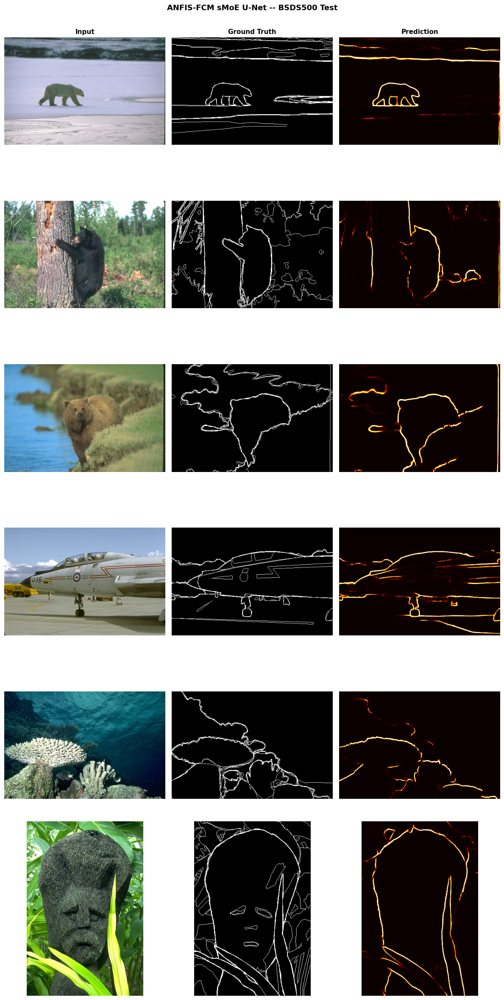

In [21]:
def denorm(t):
    mean = torch.tensor([0.485,0.456,0.406], device=t.device).view(3,1,1)
    std  = torch.tensor([0.229,0.224,0.225], device=t.device).view(3,1,1)
    return (t*std+mean).clamp(0,1).permute(1,2,0).cpu().numpy()

model.eval()
N = min(6, len(ds_test))
samples = []
with torch.no_grad():
    for i, (img, mask, stem) in enumerate(loader_test):
        if i >= N: break
        pred = predict_native(model, img, DEVICE, which='anfis')
        if pred.dim() == 3: pred = pred.unsqueeze(1)
        samples.append((img.cpu(), mask.cpu(), pred.cpu(), stem[0]))

fig, axes = plt.subplots(N, 3, figsize=(12, 4*N))
titles = ['Input', 'Ground Truth', 'Prediction']
fig.suptitle('ANFIS-FCM sMoE U-Net -- BSDS500 Test', fontsize=13, fontweight='bold')
for row, (img, mask, pred, stem) in enumerate(samples):
    axes[row,0].imshow(denorm(img[0]))
    axes[row,1].imshow(mask[0,0].numpy(), cmap='gray')
    axes[row,2].imshow(pred[0,0].numpy(), cmap='hot')
    for col in range(3):
        axes[row,col].axis('off')
        if row == 0:
            axes[row,col].set_title(titles[col], fontsize=11, fontweight='bold')
    axes[row,0].set_ylabel(stem, fontsize=8, rotation=0, labelpad=60)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/qualitative_results.png', dpi=150, bbox_inches='tight')
plt.show()


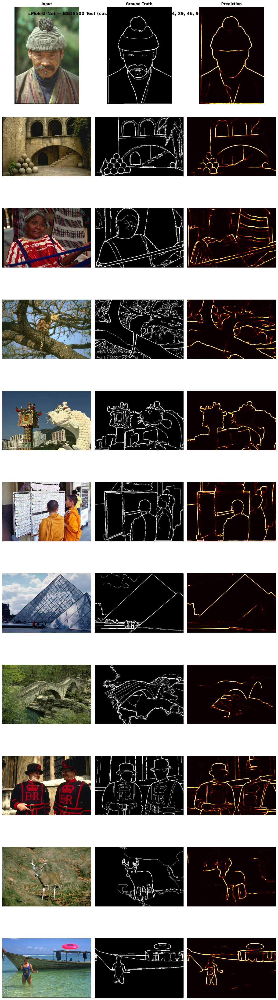

Qualitative results saved for indices: [110, 27, 76, 34, 29, 46, 96, 89, 156, 140, 193]


In [22]:
def denorm(t):
    mean = torch.tensor([0.485,0.456,0.406], device=t.device).view(3,1,1)
    std  = torch.tensor([0.229,0.224,0.225], device=t.device).view(3,1,1)
    return (t*std+mean).clamp(0,1).permute(1,2,0).cpu().numpy()

model.eval()

# Option 4: Specify exact indices you want to see
INDICES_TO_SHOW = [110, 27, 76, 34, 29, 46, 96, 89, 156, 140, 193]  # Change these numbers
N = len(INDICES_TO_SHOW)

samples = []
with torch.no_grad():
    for idx in INDICES_TO_SHOW:
        img, mask, stem = ds_test[idx]
        img = img.unsqueeze(0)  # Add batch dimension
        mask = mask.unsqueeze(0)
        
        pred = predict_native(model, img, DEVICE)
        if pred.dim() == 3: 
            pred = pred.unsqueeze(1)
        samples.append((img.cpu(), mask.cpu(), pred.cpu(), stem))

fig, axes = plt.subplots(N, 3, figsize=(12, 4*N))
titles = [' Input ', ' Ground Truth ' , ' Prediction ' ]
fig.suptitle(f'sMoE U-Net — BSDS500 Test (custom indices: {INDICES_TO_SHOW})',
             fontsize=13, fontweight='bold')
for row, (img, mask, pred, stem) in enumerate(samples):
    axes[row,0].imshow(denorm(img[0]))
    axes[row,1].imshow(mask[0,0].numpy(), cmap='gray')
    axes[row,2].imshow(pred[0,0].numpy(), cmap='hot')
    for col in range(3):
        axes[row,col].axis('off')
        if row == 0:
            axes[row,col].set_title(titles[col], fontsize=11, fontweight='bold')
    axes[row,0].set_ylabel(f"#{INDICES_TO_SHOW[row]}: {stem}", fontsize=8, rotation=0, labelpad=60)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/qualitative_results_custom.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Qualitative results saved for indices: {INDICES_TO_SHOW}')

## Cell — ANFIS Rule Firing Maps + Entropy Map (R*, native XAI)

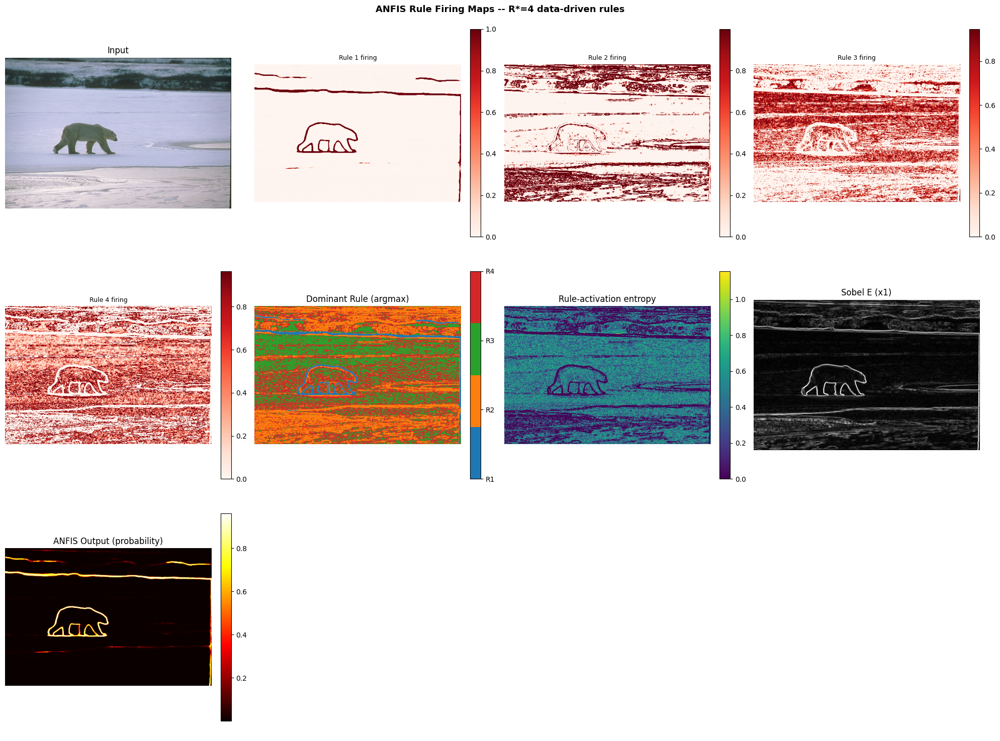

ANFIS rule firing maps + rule-activation entropy map saved (R*=4 rules). Entropy describes how activation is spread over rules; it is NOT shown to predict errors or annotator disagreement.


In [23]:
model.eval()
_imgs, _masks, _stems = next(iter(loader_test))
_imgs_pad, H0, W0 = pad_to_multiple(_imgs.to(DEVICE), multiple=PAD_MULTIPLE)

with torch.no_grad():
    out = model(_imgs_pad)

prob, rule_maps, x2_map, edge_sig, z_map, x1_map = out    # z_map = the backbone logits the head really used
prob      = prob[..., :H0, :W0]
rule_maps = rule_maps[..., :H0, :W0]
edge_sig  = edge_sig[..., :H0, :W0]
x1_map    = x1_map[..., :H0, :W0]
x2_map    = x2_map[..., :H0, :W0]
z_map     = z_map[..., :H0, :W0]

img_disp  = denorm(_imgs[0])
pred_disp = prob[0].cpu().numpy()
if pred_disp.ndim == 3 and pred_disp.shape[0] == 1:
    pred_disp = pred_disp.squeeze(0)
edge_disp = edge_sig[0,0].cpu().numpy()
rw        = rule_maps[0].cpu()
R         = rw.shape[0]
entropy_map = rule_entropy_map(rule_maps)[0,0].cpu().numpy()   # rule-ACTIVATION entropy (not validated as predictive uncertainty)

n_panels = R + 5
n_cols   = 4
n_rows   = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 5*n_rows))
axes = np.array(axes).reshape(-1)
fig.suptitle(f'ANFIS Rule Firing Maps -- R*={R} data-driven rules', fontsize=13, fontweight='bold')

axes[0].imshow(img_disp); axes[0].set_title('Input'); axes[0].axis('off')

cmap_cycle = plt.cm.tab10(np.linspace(0, 1, max(R, 10)))
for k in range(R):
    ax = axes[k+1]
    rmap = rw[k].numpy()
    vmax = max(float(np.percentile(rmap, 99)), 1e-3)
    im = ax.imshow(rmap, cmap='Reds', vmin=0, vmax=vmax)
    ax.set_title(f'Rule {k+1} firing', fontsize=9); ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

dom = rw.argmax(dim=0).numpy()
ax_dom = axes[R+1]
cmap_dom = ListedColormap([cmap_cycle[k] for k in range(R)])
im_dom = ax_dom.imshow(dom, cmap=cmap_dom, vmin=0, vmax=R-1)
ax_dom.set_title('Dominant Rule (argmax)'); ax_dom.axis('off')
cbar = plt.colorbar(im_dom, ax=ax_dom, fraction=0.046, pad=0.04, ticks=range(R))
cbar.set_ticklabels([f'R{k+1}' for k in range(R)])

im_ent = axes[R+2].imshow(entropy_map, cmap='viridis')
axes[R+2].set_title('Rule-activation entropy'); axes[R+2].axis('off')
plt.colorbar(im_ent, ax=axes[R+2], fraction=0.046, pad=0.04)

axes[R+3].imshow(edge_disp, cmap='gray')
axes[R+3].set_title('Sobel E (x1)'); axes[R+3].axis('off')

im_out = axes[R+4].imshow(pred_disp, cmap='hot')
axes[R+4].set_title('ANFIS Output (probability)'); axes[R+4].axis('off')
plt.colorbar(im_out, ax=axes[R+4], fraction=0.046, pad=0.04)

for ax in axes[n_panels:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig(f'{WORK_DIR}/rule_firing_maps.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'ANFIS rule firing maps + rule-activation entropy map saved (R*={R} rules). '
      f'Entropy describes how activation is spread over rules; it is NOT shown to predict errors or annotator disagreement.')


## Cell — Rule Correction Maps (exact logit decomposition; replaces the older w̄·TSK contribution maps)
Distinct from firing maps: a rule can fire strongly (`wbar` high) yet
contribute negatively to the final prediction if its consequent `(p,q,r)` is
negative -- e.g. actively suppressing a false texture edge. Firing alone
can't show that; contribution `wbar_i * TSK_i(x)` can.


[explanation fidelity] max |z + sum_r correction_r - head logit| = 2.86e-06  PASS


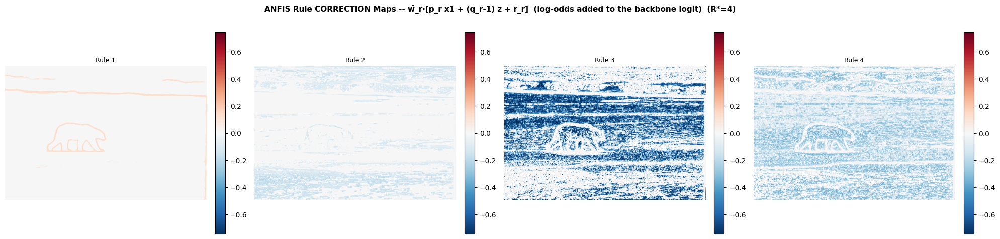

Rule correction/contribution maps saved -- blue = rule lowers the backbone log-odds, red = rule raises it


In [24]:
# Explanation of HOW the fuzzy head changes the backbone decision.
# In logit mode the head's pre-sigmoid value decomposes EXACTLY as
#     y_hat = z + sum_r wbar_r * [ p_r*x1 + (q_r - 1)*z + r_r ]        (z = backbone logit)
# so the decision INHERITED from the backbone (z) is separated from what each rule ADDS (the correction maps below).
# The older w̄_r*TSK_r maps mixed the two. The REAL backbone logits (z_map) are used -- never logits re-derived from a
# clipped probability (that recovers -13.8 where the forward pass used -18).
if getattr(model.anfis_head, 'logit_consequents', False):
    inherited, corr = rule_logit_decomposition(model.anfis_head, x1_map, x2_map, rule_maps, z2=z_map)
    _fid = explanation_fidelity(model.anfis_head, x1_map, x2_map, z_map)
    print(f'[explanation fidelity] max |z + sum_r correction_r - head logit| = {_fid:.2e}'
          + ('  PASS' if _fid < 1e-4 else '   <-- WARNING: the plotted explanation does not reconstruct the decision'))
    contrib = corr[0].cpu()                                   # [R,H,W]  additive change of the log-odds per rule
    _title = 'ANFIS Rule CORRECTION Maps -- w̄_r·[p_r x1 + (q_r-1) z + r_r]  (log-odds added to the backbone logit)'
    _note  = 'blue = rule lowers the backbone log-odds, red = rule raises it'
else:
    contrib = rule_contribution_maps(model.anfis_head, x1_map, x2_map, rule_maps, z2=z_map)[0].cpu()
    _title = 'ANFIS Rule Contribution Maps -- w̄_r x TSK_r(x)'
    _note  = 'blue/red = negative/positive contribution'
vmax_c = float(np.percentile(np.abs(contrib.numpy()), 99)) or 1e-3

n_cols = 4
n_rows = int(np.ceil(R / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 5*n_rows))
axes = np.array(axes).reshape(-1)
fig.suptitle(f'{_title}  (R*={R})', fontsize=11, fontweight='bold')
for k in range(R):
    im = axes[k].imshow(contrib[k].numpy(), cmap='RdBu_r', vmin=-vmax_c, vmax=vmax_c)
    axes[k].set_title(f'Rule {k+1}', fontsize=9); axes[k].axis('off')
    plt.colorbar(im, ax=axes[k], fraction=0.046, pad=0.04)
for ax in axes[R:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/rule_contribution_maps.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Rule correction/contribution maps saved -- {_note}')


## Cell — Rule Semantic Profiling Table
For each rule: mean x1, mean x2, mean GT edge probability, mean predicted
probability where that rule dominates, and a plain-language interpretation --
much more informative than a firing heatmap alone.


In [25]:
# Rule semantics should be DEFINED on training/validation data; the test split is for a final descriptive pass only.
_prof_loader = {'val': loader_val, 'test': loader_test}[PROFILE_SPLIT]
_gt_label = 'mean annotator agreement' if PROFILE_SPLIT == 'val' else 'union-positive fraction'   # val masks are soft, test masks are binary union
print(f'Computing rule profile over the {PROFILE_SPLIT.upper()} split (dominant-rule pixels only); GT column = {_gt_label}...')
sums = {k: {'x1':0.0,'x2':0.0,'gt':0.0,'pred':0.0,'n':0} for k in range(R)}
model.eval()
with torch.no_grad():
    for imgs, masks, _ in tqdm(_prof_loader, desc='  profiling'):
        imgs_pad, H, W = pad_to_multiple(imgs.to(DEVICE), multiple=PAD_MULTIPLE)
        prob_t, wbar_t, x2_t, _, _, x1_t = model(imgs_pad)
        prob_t = prob_t[..., :H, :W]; wbar_t = wbar_t[..., :H, :W]
        x1_t = x1_t[..., :H, :W]; x2_t = x2_t[..., :H, :W]
        gt_t = F.interpolate(masks.to(DEVICE), size=(H, W), mode='nearest')
        dom_t = wbar_t.argmax(dim=1)
        for k in range(R):
            mask_k = (dom_t == k)
            if mask_k.sum() == 0: continue
            sums[k]['x1']   += x1_t[:,0][mask_k].sum().item()
            sums[k]['x2']   += x2_t[:,0][mask_k].sum().item()
            sums[k]['gt']   += gt_t[:,0][mask_k].sum().item()
            sums[k]['pred'] += prob_t.squeeze(1)[mask_k].sum().item()
            sums[k]['n']    += mask_k.sum().item()

def _interp(x1_lvl, x2_lvl):
    # HEURISTIC labels from the mean (x1, x2) level only. A cluster in (x1, x2) space does not establish a corner,
    # texture or semantic-boundary concept; several rules may share a label (that is not four distinct concepts).
    if x1_lvl == 'Low'  and x2_lvl == 'Low':  return 'low-x1/low-x2 (background-like)'
    if x1_lvl == 'High' and x2_lvl == 'Low':  return 'high-x1/low-x2 (texture-like?)'
    if x1_lvl == 'Low'  and x2_lvl == 'High': return 'low-x1/high-x2 (backbone-only edge?)'
    return 'high-x1/high-x2 (strong edge)'

print(f'\n  {"Rule":<6} {"mean x1":>9} {"mean x2":>9} {"mean GT*":>9} {"mean pred":>10} {"x1":>6} {"x2":>6}  Heuristic label   (*GT = {_gt_label})')
print('  ' + '-'*84)
for k in range(R):
    n = max(sums[k]['n'], 1)
    mx1, mx2 = sums[k]['x1']/n, sums[k]['x2']/n
    mgt, mpr = sums[k]['gt']/n, sums[k]['pred']/n
    x1_lvl = 'High' if mx1 > 0.5 else 'Low'
    x2_lvl = 'High' if mx2 > 0.5 else 'Low'
    interp = _interp(x1_lvl, x2_lvl)
    print(f'  R{k+1:<5} {mx1:>9.3f} {mx2:>9.3f} {mgt:>9.3f} {mpr:>10.3f} {x1_lvl:>6} {x2_lvl:>6}  {interp}')


Computing rule profile over the VAL split (dominant-rule pixels only); GT column = mean annotator agreement...


  profiling: 100%|██████████| 100/100 [00:13<00:00,  7.42it/s]


  Rule     mean x1   mean x2  mean GT*  mean pred     x1     x2  Heuristic label   (*GT = mean annotator agreement)
  ------------------------------------------------------------------------------------
  R1         0.493     0.692     0.172      0.711    Low   High  low-x1/high-x2 (backbone-only edge?)
  R2         0.317     0.010     0.019      0.009    Low    Low  low-x1/low-x2 (background-like)
  R3         0.015     0.002     0.004      0.001    Low    Low  low-x1/low-x2 (background-like)
  R4         0.066     0.003     0.008      0.002    Low    Low  low-x1/low-x2 (background-like)


## Cell — ANFIS Rule-Base Visualisation (effective widths = raw softplus sigma passed through the smooth ceiling)

  Rule         c_x1  sig_x1(eff)     c_x2  sig_x2(eff)   raw x1   raw x2        p        q        r
  ----------------------------------------------------------------------------------------------------
  Rule 1       0.543        0.299    0.753        0.195    0.313    0.195    0.019    1.009    0.098
  Rule 2       0.529        0.166    0.086        0.107    0.167    0.107    0.026    1.028    0.028
  Rule 3       0.013        0.019    0.003        0.021    0.020    0.032   -0.029    1.107   -0.071
  Rule 4       0.055        0.020    0.005        0.021    0.024    0.043   -0.005    1.047   -0.007


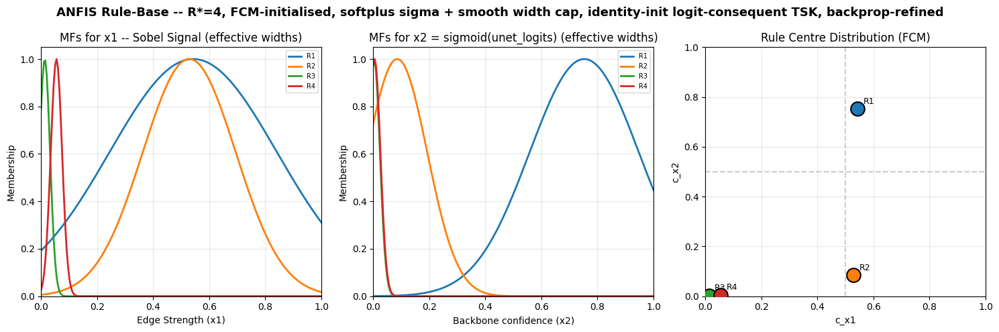

ANFIS rule-base + MF curve visualisation saved (R*=4); membership curves use the EFFECTIVE widths used by inference


In [26]:
x_range = np.linspace(0, 1, 200)
anfis_head = model.anfis_head
R = anfis_head.n_rules
theta = anfis_head.consequents.detach().cpu().numpy()
eff = anfis_head.effective_sigmas().cpu().numpy()   # [R,2] widths ACTUALLY used by inference (after the smooth ceiling)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(f'ANFIS Rule-Base -- R*={R}, FCM-initialised, softplus sigma + smooth width cap, identity-init logit-consequent TSK, backprop-refined',
             fontsize=13, fontweight='bold')
colours = plt.cm.tab10(np.linspace(0, 1, max(R, 10)))

print(f'  {"Rule":<8} {"c_x1":>8} {"sig_x1(eff)":>12} {"c_x2":>8} {"sig_x2(eff)":>12} {"raw x1":>8} {"raw x2":>8} {"p":>8} {"q":>8} {"r":>8}')
print('  ' + '-'*100)

for i_r, rule in enumerate(anfis_head.rules):
    cx1 = rule.mf_x1.center.item(); sx1 = float(eff[i_r, 0]); raw1 = rule.mf_x1.sigma.item()
    cx2 = rule.mf_x2.center.item(); sx2 = float(eff[i_r, 1]); raw2 = rule.mf_x2.sigma.item()
    pv, qv, rv = theta[i_r]
    m1 = np.exp(-((x_range-cx1)**2)/(2*sx1**2+1e-8))
    m2 = np.exp(-((x_range-cx2)**2)/(2*sx2**2+1e-8))
    axes[0].plot(x_range, m1, color=colours[i_r], lw=2, label=f'R{i_r+1}')
    axes[1].plot(x_range, m2, color=colours[i_r], lw=2, label=f'R{i_r+1}')
    axes[2].scatter(cx1, cx2, s=220, color=colours[i_r], edgecolors='k', lw=1.5, zorder=5)
    axes[2].annotate(f'R{i_r+1}', (cx1+0.02, cx2+0.02), fontsize=9)
    print(f'  Rule {i_r+1:<4} {cx1:>8.3f} {sx1:>12.3f} {cx2:>8.3f} {sx2:>12.3f} {raw1:>8.3f} {raw2:>8.3f} '
          f'{pv:>8.3f} {qv:>8.3f} {rv:>8.3f}')

for ax, xl, title in [(axes[0],'Edge Strength (x1)','MFs for x1 -- Sobel Signal (effective widths)'),
                       (axes[1],'Backbone confidence (x2)','MFs for x2 = sigmoid(unet_logits) (effective widths)')]:
    ax.set(xlabel=xl, ylabel='Membership', title=title, xlim=[0,1], ylim=[0,1.05])
    ax.legend(fontsize=7); ax.grid(alpha=0.3)

axes[2].axhline(0.5, color='gray', ls='--', alpha=0.4)
axes[2].axvline(0.5, color='gray', ls='--', alpha=0.4)
axes[2].set(xlabel='c_x1', ylabel='c_x2', title='Rule Centre Distribution (FCM)', xlim=[0,1], ylim=[0,1])
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/anfis_rule_viz.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'ANFIS rule-base + MF curve visualisation saved (R*={R}); membership curves use the EFFECTIVE widths used by inference')
